# DILU-IA | Análise de dados
Este caderno serve para importar os exceis resultantes do caderno de preparação dos dados para análise:

### Tabelas de input:
Serão criadas 3 tabelas para análise:

- Respostas: id x momento x exercicio, contendo respostas aos ex de conhecimento
- Escalas: id x momento, com PANAS e SIMS
- Participante: com turno, SUS score e covariáveis

Daqui resultará uma Tabela mestra para testes estatíticos: id + colunas_pré e pós.


## 0. Preparação

In [1]:
#pip install pingouin

In [2]:
#pip install statsmodels

In [3]:
#bibliotecas
import re
from pathlib import Path
 
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib.pyplot as plt
import pingouin as pg
import statsmodels
from statsmodels.stats.contingency_tables import mcnemar, SquareTable
from statsmodels.stats.multitest import multipletests

In [4]:
#Pastas e versões
PASTA = Path.cwd()
DADOS = PASTA / "dados_limpos_2026-10-16"    
OUT_TAB = PASTA / "outputs" / "tabelas"
OUT_FIG = PASTA / "outputs" / "figuras"
OUT_TAB.mkdir(parents=True, exist_ok=True)
OUT_FIG.mkdir(parents=True, exist_ok=True)
 
SEMENTE = 2026
N_BOOT = 10_000      
 
print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__, "| statsmodels", statsmodels.__version__, "| pingouin", pg.__version__) 

pandas 3.0.6 | numpy 2.4.6 | scipy 1.15.3 | statsmodels 0.15.0 | pingouin 0.7.0


In [5]:
# Carregar as tabelas congeladas -----------------------------
respostas = pd.read_parquet(DADOS / "respostas.parquet")
escalas = pd.read_parquet(DADOS / "escalas.parquet")
participantes = pd.read_parquet(DADOS / "participantes.parquet")
mestra = pd.read_parquet(DADOS / "mestra.parquet")
larga = pd.read_parquet(DADOS / "larga.parquet")
 
for nome, t in [("respostas", respostas), ("escalas", escalas), ("participantes", participantes),
                ("mestra", mestra), ("larga", larga)]:
    print(f"{nome:<14} {t.shape}")

respostas      (738, 21)
escalas        (202, 34)
participantes  (118, 83)
mestra         (246, 14)
larga          (118, 128)


In [6]:
#Estilo das figuras (paleta do piloto) ----------------------
DILU_BLUE, DILU_PURPLE, DILU_DARK = "#6B74C8", "#7C3AED", "#3730A3"
DILU_LIGHT, DILU_TEXT, DILU_ACCENT = "#DBEAFE", "#1E1B4B", "#93C5FD"
VERMELHO = "#EF4444"
 
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": DILU_TEXT, "axes.labelcolor": DILU_TEXT, "text.color": DILU_TEXT,
    "xtick.color": DILU_TEXT, "ytick.color": DILU_TEXT,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "sans-serif", "axes.labelsize": 11, "savefig.dpi": 300,
})
 

In [7]:
# Formatação APA ---------------------------------------------
DECIMAL = ","   # DECISÃO: separador decimal da tese ("," ou ".")
 
def fmt(x, casas=2, zero_inicial=True):
    """Número com 'casas' decimais. zero_inicial=False tira o 0 antes da vírgula
    (APA: para valores que não podem passar de 1, como p, r, α)."""
    if pd.isna(x):
        return "—"
    s = f"{x:.{casas}f}"
    if not zero_inicial:
        s = re.sub(r"^(-?)0\.", r"\1.", s)
    return s.replace(".", DECIMAL)
 
def fmt_p(p):
    """p em estilo APA: exato com 3 casas, ou '< ,001'."""
    if pd.isna(p):
        return "—"
    return "< " + fmt(0.001, 3, False) if p < 0.001 else fmt(p, 3, False)
 
def mdn_iiq(serie, casas=2):
    """'Mdn [Q1; Q3]' para tabelas descritivas."""
    s = serie.dropna()
    return f"{fmt(s.median(), casas)} [{fmt(s.quantile(.25), casas)}; {fmt(s.quantile(.75), casas)}]"
 
def m_dp(serie, casas=2):
    """'M (DP)' para tabelas descritivas."""
    s = serie.dropna()
    return f"{fmt(s.mean(), casas)} ({fmt(s.std(), casas)})"
 
def n_pct(serie, valor, casas=1):
    """'n (%)' de um valor numa variável categórica (percentagem sobre os não vazios)."""
    s = serie.dropna()
    n = int((s == valor).sum())
    return f"{n} ({fmt(100 * n / len(s), casas)})" if len(s) else "—"

In [8]:
# Testes com output SPSS-like ---------------------------------
def z_de_p(p):
    """|Z| a partir de um p bilateral assintótico (sinal negativo, como no SPSS)."""
    return -stats.norm.isf(p / 2)
 
def mann_whitney_spss(dados, var, grupo, rotulos, titulo):
    """Mann-Whitney com tabelas Ranks e Test Statistics, como no SPSS.
    rotulos: {valor_do_grupo: 'nome a mostrar'}."""
    d = dados[[var, grupo]].dropna()
    d = d.assign(rank=d[var].rank())                  # ordens com empates a média
    g = [d.loc[d[grupo] == v, var] for v in rotulos]
 
    ranks = pd.DataFrame({
        "N": [len(x) for x in g] + [len(d)],
        "Mean Rank": [d.loc[d[grupo] == v, "rank"].mean() for v in rotulos] + [np.nan],
        "Sum of Ranks": [d.loc[d[grupo] == v, "rank"].sum() for v in rotulos] + [np.nan],
    }, index=list(rotulos.values()) + ["Total"])
 
    res = stats.mannwhitneyu(g[0], g[1], alternative="two-sided",
                             method="asymptotic", use_continuity=False)
    u = min(res.statistic, len(g[0]) * len(g[1]) - res.statistic)   # U reportado pelo SPSS
    n1, n2 = len(g[0]), len(g[1])
    rbc = 2 * res.statistic / (n1 * n2) - 1          # rank-biserial; > 0: 1.º grupo de 'rotulos' tem valores mais altos
    z = abs(z_de_p(res.pvalue)) * (1 if rbc >= 0 else -1)   # Z com o sinal da direção
 
    print(f"\n{'=' * 60}\n  {titulo}\n{'=' * 60}")
    print("Ranks\n", ranks.round(2).to_string())
    print(f"\nTest Statistics\n  Mann-Whitney U = {u:.1f}\n  Z = {z:.3f}"
          f"\n  Asymp. Sig. (2-tailed) = {res.pvalue:.3f}\n  Rank-biserial r = {rbc:.3f}")
    return {"variavel": titulo, "n1": len(g[0]), "n2": len(g[1]),
            "Mdn1": g[0].median(), "Mdn2": g[1].median(),
            "U": u, "Z": z, "p": res.pvalue, "r_rb": rbc}
 
def fisher_ou_quiquadrado(dados, var, grupo, titulo):
    """Tabela de contingência; exato de Fisher em 2×2, χ² de Pearson nos restantes."""
    tab = pd.crosstab(dados[var], dados[grupo])
    print(f"\n{'=' * 60}\n  {titulo}\n{'=' * 60}")
    print(pd.crosstab(dados[var], dados[grupo], margins=True, margins_name="Total").to_string())
    if tab.shape == (2, 2):
        _, p = stats.fisher_exact(tab)
        print(f"\n  Fisher's Exact Test: Exact Sig. (2-sided) = {p:.3f}")
        return {"variavel": titulo, "teste": "Fisher", "estatistica": np.nan, "gl": np.nan, "p": p}
    chi2, p, gl, esperados = stats.chi2_contingency(tab, correction=False)
    pct_baixos = 100 * (esperados < 5).mean()
    print(f"\n  Pearson Chi-Square = {chi2:.3f}, df = {gl}, Asymp. Sig. (2-sided) = {p:.3f}"
          f"\n  Células com frequência esperada < 5: {pct_baixos:.0f}%")
    return {"variavel": titulo, "teste": "Qui-quadrado", "estatistica": chi2, "gl": gl, "p": p}
 
def kruskal_spss(dados, var, grupo, titulo):
    """Kruskal-Wallis com tabela Ranks e Test Statistics, como no SPSS."""
    d = dados[[var, grupo]].dropna()
    d = d.assign(rank=d[var].rank())
    niveis = sorted(d[grupo].unique())
    ranks = pd.DataFrame({
        "N": [int((d[grupo] == v).sum()) for v in niveis] + [len(d)],
        "Mean Rank": [d.loc[d[grupo] == v, "rank"].mean() for v in niveis] + [np.nan],
    }, index=[f"{grupo} {v}" for v in niveis] + ["Total"])
    h, p = stats.kruskal(*[d.loc[d[grupo] == v, var] for v in niveis])
    gl = len(niveis) - 1
    eps2 = h / (len(d) - 1)                     # épsilon² (tamanho de efeito)
    print(f"\n{'=' * 60}\n  {titulo}\n{'=' * 60}")
    print("Ranks\n", ranks.round(2).to_string())
    print(f"\nTest Statistics\n  Kruskal-Wallis H = {h:.3f}\n  df = {gl}"
          f"\n  Asymp. Sig. = {p:.3f}\n  ε² = {eps2:.3f}")
    return {"variavel": titulo, "H": h, "gl": gl, "p": p, "eps2": eps2}

In [9]:
def mcnemar_spss(tabela_pares, titulo, rotulo_1="certo"):
    """McNemar exato (binomial) para uma variável 0/1 pré vs pós.
    b = 1 no pré e 0 no pós; c = 0 no pré e 1 no pós.
    rotulo_1: o que significa o valor 1 (para o output)."""
    t = pd.crosstab(tabela_pares["pre"], tabela_pares["pos"]).reindex(
        index=[0, 1], columns=[0, 1], fill_value=0)
    b, c = int(t.loc[1, 0]), int(t.loc[0, 1])
    n = int(t.values.sum())
    p_pre, p_pos = tabela_pares["pre"].mean(), tabela_pares["pos"].mean()
 
    print(f"\n{'=' * 64}\n  {titulo}\n{'=' * 64}")
    print(f"Crosstab (linhas = pré, colunas = pós; 1 = {rotulo_1})")
    print(pd.crosstab(tabela_pares["pre"], tabela_pares["pos"], margins=True,
                      margins_name="Total").to_string())
 
    if b + c == 0:
        print("  Sem pares discordantes: teste não calculável.")
        return {"teste": titulo, "tipo": "McNemar", "n": n, "p": np.nan}
 
    res = mcnemar(t.values, exact=True)
    print(f"\n  % {rotulo_1}: pré = {100 * p_pre:.1f}%, pós = {100 * p_pos:.1f}%"
          f"\n  Discordantes: 1→0 (b) = {b}, 0→1 (c) = {c}"
          f"\n  McNemar Test: Exact Sig. (2-sided, binomial) = {res.pvalue:.4f}")
    return {"teste": titulo, "tipo": "McNemar", "n": n,
            "pct_pre": 100 * p_pre, "pct_pos": 100 * p_pos,
            "b_piorou": b, "c_melhorou": c, "estatistica": np.nan, "gl": np.nan, "p": res.pvalue}

In [10]:
def stuart_maxwell_spss(tabela_pares, titulo):
    """Teste de homogeneidade marginal (Stuart-Maxwell) para uma variável
    categórica pré vs pós. A tabela tem de ser quadrada (mesmas categorias)."""
    categorias = sorted(set(tabela_pares["pre"]) | set(tabela_pares["pos"]))
    t = pd.crosstab(tabela_pares["pre"], tabela_pares["pos"]).reindex(
        index=categorias, columns=categorias, fill_value=0)
 
    print(f"\n{'=' * 64}\n  {titulo}\n{'=' * 64}")
    print("Crosstab (linhas = pré, colunas = pós)")
    print(t.to_string())
    try:
        res = SquareTable(t.values, shift_zeros=False).homogeneity()
        estat, gl, p = float(res.statistic), int(res.df), float(res.pvalue)
        if not np.isfinite(estat):
            raise ValueError("estatística não finita")
    except Exception as erro:
        print(f"  Teste não calculável ({erro}). Reporta-se só a distribuição descritiva (decisão 20).")
        return {"teste": titulo, "tipo": "Stuart-Maxwell", "n": int(t.values.sum()), "p": np.nan}
    print(f"\n  Stuart-Maxwell χ² = {estat:.3f}, df = {gl}, Asymp. Sig. = {p:.4f}")
    return {"teste": titulo, "tipo": "Stuart-Maxwell", "n": int(t.values.sum()),
            "estatistica": estat, "gl": gl, "p": p}

In [11]:
# Função: IC 95% por bootstrap -------------------------------
def ic_bootstrap(diferencas, funcao, n_boot=N_BOOT, semente=SEMENTE):
    """Reamostra os participantes (as suas diferenças pós − pré) n_boot vezes,
    calcula 'funcao' (np.mean ou np.median) em cada reamostragem e devolve
    os percentis 2,5 e 97,5 (IC 95% por percentis). Decisão 22."""
    rng = np.random.default_rng(semente)
    d = np.asarray(diferencas)
    amostras = rng.choice(d, size=(n_boot, len(d)), replace=True)
    valores = funcao(amostras, axis=1)
    return np.percentile(valores, [2.5, 97.5])
 
# Função: Wilcoxon (Pratt) com output à SPSS ------------------
def wilcoxon_pratt_spss(pre, pos, titulo):
    """Wilcoxon emparelhado, zeros pelo método de Pratt, p assintótico sem
    correção de continuidade (decisão 21). Tamanhos de efeito da decisão 22."""
    dados = pd.DataFrame({"pre": pre, "pos": pos}).dropna()
    d = (dados["pos"] - dados["pre"]).to_numpy()
    n = len(d)
 
    # Ordens pelo método de Pratt: os zeros entram na ordenação e depois saem
    ordens = stats.rankdata(np.abs(d))
    t_pos, t_neg = ordens[d > 0].sum(), ordens[d < 0].sum()
    n_pos, n_neg, n_zero = int((d > 0).sum()), int((d < 0).sum()), int((d == 0).sum())
 
    ranks = pd.DataFrame({
        "N": [n_neg, n_pos, n_zero, n],
        "Mean Rank": [ordens[d < 0].mean() if n_neg else np.nan,
                      ordens[d > 0].mean() if n_pos else np.nan, np.nan, np.nan],
        "Sum of Ranks": [t_neg, t_pos, np.nan, np.nan],
    }, index=["Negative Ranks (pós < pré)", "Positive Ranks (pós > pré)",
              "Ties (pós = pré)", "Total"])
 
    if n_pos + n_neg == 0:
        print(f"{titulo}: todas as diferenças são zero; teste não calculável.")
        return None
 
    res = stats.wilcoxon(dados["pos"], dados["pre"], zero_method="pratt",
                         method="approx", correction=False)
    rbc = (t_pos - t_neg) / (t_pos + t_neg)          # > 0: pós maior do que pré
    z = abs(z_de_p(res.pvalue)) * (1 if rbc >= 0 else -1)   # Z com o sinal da direção
    ic_media = ic_bootstrap(d, np.mean)
    ic_mediana = ic_bootstrap(d, np.median)
 
    print(f"\n{'=' * 64}\n  {titulo}\n{'=' * 64}")
    print(f"Descriptive Statistics (n = {n})")
    for nome in ["pre", "pos"]:
        s = dados[nome]
        print(f"  {nome:<4} M = {s.mean():.2f} (DP = {s.std():.2f})   "
              f"Mdn = {s.median():.2f} [{s.quantile(.25):.2f}; {s.quantile(.75):.2f}]")
    print("\nRanks (método de Pratt: zeros incluídos na ordenação)")
    print(ranks.round(2).to_string())
    print(f"\nTest Statistics\n  Z = {z:.3f}\n  Asymp. Sig. (2-tailed) = {res.pvalue:.4f}"
          f"\n  Rank-biserial r = {rbc:.3f}"
          f"\n  Diferença média = {d.mean():.2f}  IC 95% [{ic_media[0]:.2f}; {ic_media[1]:.2f}]"
          f"\n  Mediana das diferenças = {np.median(d):.2f}  IC 95% [{ic_mediana[0]:.2f}; {ic_mediana[1]:.2f}]")
 
    return {"analise": titulo, "n": n,
            "M_pre": dados["pre"].mean(), "M_pos": dados["pos"].mean(),
            "Mdn_pre": dados["pre"].median(), "Mdn_pos": dados["pos"].median(),
            "n_melhorou": n_pos, "n_igual": n_zero, "n_piorou": n_neg,
            "Z": z, "p": res.pvalue, "rbc": rbc,
            "dif_media": d.mean(), "dif_media_ic_inf": ic_media[0], "dif_media_ic_sup": ic_media[1],
            "dif_mediana": np.median(d), "dif_mediana_ic_inf": ic_mediana[0],
            "dif_mediana_ic_sup": ic_mediana[1]}

# Verificação do sinal com um exemplo inventado -------------
# Todos melhoram: a rank-biserial tem de dar +1 e a diferença média tem de ser positiva
teste = wilcoxon_pratt_spss(pd.Series([0, 1, 1, 2, 0, 1, 2, 0, 1, 0]),
                            pd.Series([1, 2, 3, 3, 2, 2, 3, 1, 3, 2]), "VERIFICAÇÃO (dados inventados)")
assert teste["rbc"] == 1 and teste["dif_media"] > 0, "O sinal da rank-biserial está trocado"

# Mann-Whitney: o 1.º grupo tem todos os valores acima do 2.º → r_rb tem de dar +1
df_teste = pd.DataFrame({"x": [5, 6, 7, 8, 1, 2, 3, 4],
                         "g": ["A", "A", "A", "A", "B", "B", "B", "B"]})
t_mw = mann_whitney_spss(df_teste, "x", "g", {"A": "A", "B": "B"}, "VERIFICAÇÃO MW (dados inventados)")
assert t_mw["r_rb"] == 1 and t_mw["Z"] > 0, "O sinal da rank-biserial do Mann-Whitney está trocado"

# Wilcoxon: o Z tem de ter o mesmo sinal da rank-biserial
assert np.sign(teste["Z"]) == np.sign(teste["rbc"]), "O sinal do Z do Wilcoxon está trocado"


  VERIFICAÇÃO (dados inventados)
Descriptive Statistics (n = 10)
  pre  M = 0.80 (DP = 0.79)   Mdn = 1.00 [0.00; 1.00]
  pos  M = 2.20 (DP = 0.79)   Mdn = 2.00 [2.00; 3.00]

Ranks (método de Pratt: zeros incluídos na ordenação)
                             N  Mean Rank  Sum of Ranks
Negative Ranks (pós < pré)   0        NaN           0.0
Positive Ranks (pós > pré)  10        5.5          55.0
Ties (pós = pré)             0        NaN           NaN
Total                       10        NaN           NaN

Test Statistics
  Z = 2.889
  Asymp. Sig. (2-tailed) = 0.0039
  Rank-biserial r = 1.000
  Diferença média = 1.40  IC 95% [1.10; 1.70]
  Mediana das diferenças = 1.00  IC 95% [1.00; 2.00]

  VERIFICAÇÃO MW (dados inventados)
Ranks
        N  Mean Rank  Sum of Ranks
A      4        6.5          26.0
B      4        2.5          10.0
Total  8        NaN           NaN

Test Statistics
  Mann-Whitney U = 0.0
  Z = 2.309
  Asymp. Sig. (2-tailed) = 0.021
  Rank-biserial r = 1.000


In [12]:
def cochran_spss(largo, titulo):
    """Q de Cochran para uma variável 0/1 em k momentos (linhas = participantes completos).
    Q = (k − 1) · [k · Σ C_j² − N²] / (k · N − Σ R_i²)
    C_j = total de 1 em cada momento; R_i = total de 1 em cada participante; N = total de 1.
    Sob H0, Q segue um χ² com k − 1 graus de liberdade."""
    n, k = len(largo), largo.shape[1]
    pct = largo.mean() * 100
    print(f"\n{'=' * 64}\n  {titulo}\n{'=' * 64}")
    print(f"n = {n} (método válido nos três momentos)")
    print("  % usou fórmula: " + " | ".join(f"{NOMES_MOM[m]} = {pct[m]:.1f}%" for m in largo.columns))
    base = {"teste": titulo, "tipo": "Cochran", "n": n,
            "pct_pre": pct["pre"], "pct_pos": pct["pos"], "pct_follow": pct["follow"]}

    C = largo.sum(axis=0)          # totais por momento
    R = largo.sum(axis=1)          # totais por participante
    N = C.sum()
    denominador = k * N - (R ** 2).sum()
    if denominador == 0:
        print("  Ninguém mudou de método: teste não calculável.")
        return {**base, "estatistica": np.nan, "gl": np.nan, "p": np.nan}

    q = (k - 1) * (k * (C ** 2).sum() - N ** 2) / denominador
    gl = k - 1
    p = stats.chi2.sf(q, gl)

    # Verificação com o pingouin (só o Q, para não depender do nome da coluna do p)
    longo = largo.reset_index().melt(id_vars="participant_id", var_name="momento", value_name="usou_formula")
    q_pg = float(pg.cochran(data=longo, dv="usou_formula", within="momento", subject="participant_id")["Q"].iloc[0])
    assert np.isclose(q, q_pg), f"Q diferente do pingouin ({q:.4f} vs {q_pg:.4f})"

    print(f"  Cochran's Q = {q:.3f}, df = {gl}, Asymp. Sig. = {p:.4f}")
    return {**base, "estatistica": q, "gl": gl, "p": p}

## 1. Análise de atrição
### 1.1. Fluxograma

In [13]:
fluxo = pd.Series({
    "Participantes (pré ou pós)": int(((participantes["tem_pre"] == 1) | (participantes["tem_pos"] == 1)).sum()),
    "Com pré": int(participantes["tem_pre"].sum()),
    "Com pós": int(participantes["tem_pos"].sum()),
    "Pares pré–pós": int(participantes["par_pre_pos"].sum()),
    "Códigos não emparelháveis (591, 592, 58, 59 = 2 pessoas)": int(participantes["pre_pos_nao_emparelhavel"].sum()),
    "Pares que completaram o jogo": int(((participantes["par_pre_pos"] == 1)
                                         & (participantes["game_finished"] == 1)).sum()),
    "Pares sinalizados (colaboração)": int(((participantes["par_pre_pos"] == 1)
                                            & (participantes["suspeita_colaboracao"] == 1)).sum()),
    "Pares com desvio no pós": int(((participantes["par_pre_pos"] == 1)
                                    & ((participantes["pos_sem_tempo"] == 1)
                                       | (participantes["pos_fora_sessao"] == 1))).sum()),
    "Follow-up: submissões válidas": int(participantes["tem_follow"].sum()),
    "Follow-up: não atribuíveis (1131, 1132)": int(participantes["follow_nao_atribuivel"].sum()),
    "Pares pré–follow-up (F1)": int(participantes["par_pre_follow"].sum()),
    "Três momentos (F2)": int(participantes["tres_momentos"].sum()),
    "Pares pré–follow-up sinalizados (colaboração no follow-up)": int(((participantes["par_pre_follow"] == 1)
                                         & (participantes["suspeita_colaboracao_follow"] == 1)).sum()),
})
print(fluxo.to_string())

Participantes (pré ou pós)                                    115
Com pré                                                       113
Com pós                                                        89
Pares pré–pós                                                  87
Códigos não emparelháveis (591, 592, 58, 59 = 2 pessoas)        4
Pares que completaram o jogo                                   32
Pares sinalizados (colaboração)                                 9
Pares com desvio no pós                                         7
Follow-up: submissões válidas                                  44
Follow-up: não atribuíveis (1131, 1132)                         2
Pares pré–follow-up (F1)                                       41
Três momentos (F2)                                             32
Pares pré–follow-up sinalizados (colaboração no follow-up)      2


```
Inscritos com consentimento (n = 118)
 ├─ Sem pré nem pós (n = 5)
 │    └─ Responderam só ao follow-up (n = 1): apenas descritivos
 └─ Responderam ao pré (n = 113)
     ├─ Códigos partilhados em simultâneo, não emparelháveis (n = 2: 58 e 59)
     ├─ Sem pós (n = 24)
     │    └─ Com follow-up (n = 9)
     └─ Pares pré–pós: ANÁLISE PRIMÁRIA (n = 87)
          ├─ S1: completaram o jogo (n = 32)
          ├─ S2: sem sinalizados por colaboração (n = 78)
          ├─ S6: sem desvios no pós (n = 80)
          └─ Com follow-up: TRÊS MOMENTOS, F2 (n = 32)
               └─ F3: sem nenhum exercício por resolver no pós (n = 28)

Pré–follow-up: FAMÍLIA 3, ANÁLISE PRINCIPAL, F1 (n = 41 = 32 + 9)
     └─ Sem sinalizados por colaboração no follow-up (n = 39)
```
Notas ao lado:
- Pré e pós: submissões excluídas por falta de consentimento (pré: 5; pós: 4)
  e 1 ressubmissão removida no pré.
- Follow-up: 49 submissões → 3 ressubmissões e 2 submissões repetidas
  removidas → 44 válidas. 2 não atribuíveis (código 113 usado por duas
  pessoas, provavelmente 113 e 133; ambas têm par pré–pós) e 1 sem pré
  nem pós → 41 pares pré–follow-up.

### 1.2. Atrição pré-pós

In [14]:
# Quem tem pré (e é emparelhável): tem pós vs não tem pós
atr = larga[(larga["tem_pre"] == 1) & (larga["pre_pos_nao_emparelhavel"] == 0)].copy()
atr["grupo_pos"] = atr["tem_pos"].map({1: "Com pós", 0: "Sem pós"})
print(atr["grupo_pos"].value_counts())

grupo_pos
Com pós    87
Sem pós    24
Name: count, dtype: int64


In [15]:
#Atrição: variáveis contínuas e ordinais (Mann-Whitney) -----
VARS_ATR = {
    "conhecimento_pre": "Conhecimento (pré)",
    "AP_pre": "Afeto positivo (pré)",
    "AN_pre": "Afeto negativo (pré)",
    "motivacao_intrinseca_pre": "Motivação intrínseca (pré)",
    "regulacao_identificada_pre": "Regulação identificada (pré)",
    "regulacao_externa_pre": "Regulação externa (pré)",
    "desmotivacao_pre": "Amotivação (pré)",
    "digital_confort": "Conforto com jogos digitais",
    "ia_confort": "Conforto com IA",
}
res_atr = [mann_whitney_spss(atr, v, "grupo_pos", {"Com pós": "Com pós", "Sem pós": "Sem pós"}, rot)
           for v, rot in VARS_ATR.items()]
 



  Conhecimento (pré)
Ranks
            N  Mean Rank  Sum of Ranks
Com pós   87      57.91        5038.5
Sem pós   24      49.06        1177.5
Total    111        NaN           NaN

Test Statistics
  Mann-Whitney U = 877.5
  Z = 1.243
  Asymp. Sig. (2-tailed) = 0.214
  Rank-biserial r = 0.159

  Afeto positivo (pré)
Ranks
            N  Mean Rank  Sum of Ranks
Com pós   87      55.10        4793.5
Sem pós   24      59.27        1422.5
Total    111        NaN           NaN

Test Statistics
  Mann-Whitney U = 965.5
  Z = -0.564
  Asymp. Sig. (2-tailed) = 0.573
  Rank-biserial r = -0.075

  Afeto negativo (pré)
Ranks
            N  Mean Rank  Sum of Ranks
Com pós   87      56.32        4899.5
Sem pós   24      54.85        1316.5
Total    111        NaN           NaN

Test Statistics
  Mann-Whitney U = 1016.5
  Z = 0.198
  Asymp. Sig. (2-tailed) = 0.843
  Rank-biserial r = 0.026

  Motivação intrínseca (pré)
Ranks
            N  Mean Rank  Sum of Ranks
Com pós   86      56.20        4833.

In [16]:
#Atrição: variáveis categóricas -----------------------------
res_atr_cat = [fisher_ou_quiquadrado(atr, v, "grupo_pos", rot) for v, rot in
               [("gender", "Género (1 = masculino)"), ("prior_education", "Grau superior prévio"),
                ("turno", "Turno")]]
 


  Género (1 = masculino)
grupo_pos  Com pós  Sem pós  Total
gender                            
0.0             66       18     84
1.0             21        6     27
Total           87       24    111

  Fisher's Exact Test: Exact Sig. (2-sided) = 1.000

  Grau superior prévio
grupo_pos        Com pós  Sem pós  Total
prior_education                         
0.0                   83       21    104
1.0                    4        3      7
Total                 87       24    111

  Fisher's Exact Test: Exact Sig. (2-sided) = 0.171

  Turno
grupo_pos  Com pós  Sem pós  Total
turno                             
1.0             29        4     33
2.0             28       12     40
3.0             30        8     38
Total           87       24    111

  Pearson Chi-Square = 3.422, df = 2, Asymp. Sig. (2-sided) = 0.181
  Células com frequência esperada < 5: 0%


In [17]:
linhas = []
for r_ in res_atr:
    linhas.append({"Variável": r_["variavel"],
                   "Com pós Mdn": fmt(r_["Mdn1"]), "Sem pós Mdn": fmt(r_["Mdn2"]),
                   "U": fmt(r_["U"], 1), "Z": fmt(r_["Z"]), "p": fmt_p(r_["p"]),
                   "r_rb": fmt(r_["r_rb"], 2, False)})
tabela_atr = pd.DataFrame(linhas)
print(tabela_atr.to_string(index=False))
tabela_atr.to_excel(OUT_TAB / "1_atricao_mannwhitney.xlsx", index=False)
pd.DataFrame(res_atr_cat).to_excel(OUT_TAB / "1_atricao_categoricas.xlsx", index=False)

                    Variável Com pós Mdn Sem pós Mdn      U     Z    p r_rb
          Conhecimento (pré)        2,00        1,50  877,5  1,24 ,214  ,16
        Afeto positivo (pré)       16,00       16,00  965,5 -0,56 ,573 -,08
        Afeto negativo (pré)        8,00        8,50 1016,5  0,20 ,843  ,03
  Motivação intrínseca (pré)        3,50        3,00  886,0  0,77 ,443  ,10
Regulação identificada (pré)        4,25        4,50  849,0 -0,81 ,418 -,11
     Regulação externa (pré)        4,00        4,50  746,0 -1,67 ,095 -,23
            Amotivação (pré)        2,50        2,50  897,5 -0,29 ,772 -,04
 Conforto com jogos digitais        4,00        4,00 1011,5  0,25 ,805  ,03
             Conforto com IA        4,00        4,00  879,5  1,28 ,200  ,16


In [18]:
#Comparação do pré entre turnos (Kruskal-Wallis) ------------
pre_turnos = larga[(larga["tem_pre"] == 1) & (larga["pre_pos_nao_emparelhavel"] == 0)]
res_turnos = [kruskal_spss(pre_turnos, v, "turno", rot) for v, rot in VARS_ATR.items()]
pd.DataFrame(res_turnos).to_excel(OUT_TAB / "1_turnos_pre_kruskal.xlsx", index=False)


  Conhecimento (pré)
Ranks
              N  Mean Rank
turno 1.0   33      50.03
turno 2.0   40      49.62
turno 3.0   38      67.89
Total      111        NaN

Test Statistics
  Kruskal-Wallis H = 8.572
  df = 2
  Asymp. Sig. = 0.014
  ε² = 0.078

  Afeto positivo (pré)
Ranks
              N  Mean Rank
turno 1.0   33      60.18
turno 2.0   40      51.96
turno 3.0   38      56.62
Total      111        NaN

Test Statistics
  Kruskal-Wallis H = 1.208
  df = 2
  Asymp. Sig. = 0.547
  ε² = 0.011

  Afeto negativo (pré)
Ranks
              N  Mean Rank
turno 1.0   33      57.83
turno 2.0   40      57.56
turno 3.0   38      52.76
Total      111        NaN

Test Statistics
  Kruskal-Wallis H = 0.592
  df = 2
  Asymp. Sig. = 0.744
  ε² = 0.005

  Motivação intrínseca (pré)
Ranks
              N  Mean Rank
turno 1.0   31      55.23
turno 2.0   40      51.58
turno 3.0   38      58.42
Total      109        NaN

Test Statistics
  Kruskal-Wallis H = 0.921
  df = 2
  Asymp. Sig. = 0.631
  ε² = 0.009


In [19]:
pre_turnos = larga[(larga["tem_pre"] == 1) & (larga["pre_pos_nao_emparelhavel"] == 0)]
pd.crosstab(pre_turnos["turno"], pre_turnos["conhecimento_pre"], normalize="index").round(2) * 100

conhecimento_pre,0.0,1.0,2.0,3.0
turno,,,,
1.0,21.0,39.0,9.0,30.0
2.0,25.0,30.0,18.0,28.0
3.0,11.0,13.0,26.0,50.0


### 1.3. Atrição do Follow-up

In [20]:
def tabela_mw(resultados, rot1, rot2):
    """Tabela APA a partir dos resultados de mann_whitney_spss."""
    return pd.DataFrame([{"Variável": r["variavel"],
                          f"{rot1} Mdn": fmt(r["Mdn1"]), f"{rot2} Mdn": fmt(r["Mdn2"]),
                          "U": fmt(r["U"], 1), "Z": fmt(r["Z"]), "p": fmt_p(r["p"]),
                          "r_rb": fmt(r["r_rb"], 2, False)} for r in resultados])

In [21]:
EXCLUIR_ATR_F = [113, 133]
atr_f = larga[(larga["tem_pre"] == 1) & (larga["pre_pos_nao_emparelhavel"] == 0)
              & ~larga["participant_id"].isin(EXCLUIR_ATR_F)].copy()
atr_f["grupo_follow"] = np.where(atr_f["par_pre_follow"] == 1, "Com follow-up", "Sem follow-up")
print(atr_f["grupo_follow"].value_counts())   # esperado: 41 vs 68

grupo_follow
Sem follow-up    68
Com follow-up    41
Name: count, dtype: int64


In [22]:
# Variáveis pré
ROT_F = {"Com follow-up": "Com follow-up", "Sem follow-up": "Sem follow-up"}
res_atr_f = [mann_whitney_spss(atr_f, v, "grupo_follow", ROT_F, rot) for v, rot in VARS_ATR.items()]
res_atr_f_cat = [fisher_ou_quiquadrado(atr_f, v, "grupo_follow", rot) for v, rot in
                 [("gender", "Género (1 = masculino)"), ("prior_education", "Grau superior prévio"),
                  ("turno", "Turno"), ("tem_pos", "Respondeu ao pós")]]


  Conhecimento (pré)
Ranks
                  N  Mean Rank  Sum of Ranks
Com follow-up   41      56.21        2304.5
Sem follow-up   68      54.27        3690.5
Total          109        NaN           NaN

Test Statistics
  Mann-Whitney U = 1344.5
  Z = 0.323
  Asymp. Sig. (2-tailed) = 0.747
  Rank-biserial r = 0.036

  Afeto positivo (pré)
Ranks
                  N  Mean Rank  Sum of Ranks
Com follow-up   41      57.73        2367.0
Sem follow-up   68      53.35        3628.0
Total          109        NaN           NaN

Test Statistics
  Mann-Whitney U = 1282.0
  Z = 0.703
  Asymp. Sig. (2-tailed) = 0.482
  Rank-biserial r = 0.080

  Afeto negativo (pré)
Ranks
                  N  Mean Rank  Sum of Ranks
Com follow-up   41      54.45        2232.5
Sem follow-up   68      55.33        3762.5
Total          109        NaN           NaN

Test Statistics
  Mann-Whitney U = 1371.5
  Z = -0.142
  Asymp. Sig. (2-tailed) = 0.887
  Rank-biserial r = -0.016

  Motivação intrínseca (pré)
Ranks
 

In [23]:
# Variáveis do pós
atr_f2 = atr_f[atr_f["par_pre_pos"] == 1].copy()
print(atr_f2["grupo_follow"].value_counts())   # esperado: 32 vs 53

VARS_ATR_POS = {
    "conhecimento_pos": "Conhecimento (pós)",
    "delta_conhecimento": "Diferença pós − pré (conhecimento)",
    "AP_pos": "Afeto positivo (pós)",
    "AN_pos": "Afeto negativo (pós)",
    "SUS": "SUS",
}
res_atr_f2 = [mann_whitney_spss(atr_f2, v, "grupo_follow", ROT_F, rot) for v, rot in VARS_ATR_POS.items()]
res_atr_f2_cat = [fisher_ou_quiquadrado(atr_f2, v, "grupo_follow", rot) for v, rot in
                  [("sem_resolucao_pos", "Nenhum exercício resolvido no pós"),
                   ("game_finished", "Terminou o jogo"),
                   ("suspeita_colaboracao", "Sinalizado por colaboração (pré/pós)")]]

grupo_follow
Sem follow-up    53
Com follow-up    32
Name: count, dtype: int64

  Conhecimento (pós)
Ranks
                 N  Mean Rank  Sum of Ranks
Com follow-up  32      41.62        1332.0
Sem follow-up  53      43.83        2323.0
Total          85        NaN           NaN

Test Statistics
  Mann-Whitney U = 804.0
  Z = -0.419
  Asymp. Sig. (2-tailed) = 0.676
  Rank-biserial r = -0.052

  Diferença pós − pré (conhecimento)
Ranks
                 N  Mean Rank  Sum of Ranks
Com follow-up  32       42.0        1344.0
Sem follow-up  53       43.6        2311.0
Total          85        NaN           NaN

Test Statistics
  Mann-Whitney U = 816.0
  Z = -0.304
  Asymp. Sig. (2-tailed) = 0.761
  Rank-biserial r = -0.038

  Afeto positivo (pós)
Ranks
                 N  Mean Rank  Sum of Ranks
Com follow-up  32      46.09        1475.0
Sem follow-up  53      41.13        2180.0
Total          85        NaN           NaN

Test Statistics
  Mann-Whitney U = 749.0
  Z = 0.902
  Asymp. Sig. (2

In [24]:
# Exportar
tab_atr_f = pd.concat([tabela_mw(res_atr_f, "Com FU", "Sem FU"),
                       tabela_mw(res_atr_f2, "Com FU", "Sem FU")], ignore_index=True)
print(tab_atr_f.to_string(index=False))
tab_atr_f.to_excel(OUT_TAB / "1_atricao_followup_mannwhitney.xlsx", index=False)
pd.DataFrame(res_atr_f_cat + res_atr_f2_cat).to_excel(OUT_TAB / "1_atricao_followup_categoricas.xlsx", index=False)

                          Variável Com FU Mdn Sem FU Mdn      U     Z    p r_rb
                Conhecimento (pré)       2,00       2,00 1344,5  0,32 ,747  ,04
              Afeto positivo (pré)      16,00      16,00 1282,0  0,70 ,482  ,08
              Afeto negativo (pré)       8,00       8,00 1371,5 -0,14 ,887 -,02
        Motivação intrínseca (pré)       3,62       3,25 1235,0  0,68 ,498  ,08
      Regulação identificada (pré)       4,25       4,50 1234,0 -0,14 ,892 -,02
           Regulação externa (pré)       3,75       4,25  985,0 -2,08 ,037 -,24
                  Amotivação (pré)       2,25       2,50 1102,0 -1,23 ,218 -,14
       Conforto com jogos digitais       4,00       4,00 1168,0  1,50 ,134  ,16
                   Conforto com IA       4,00       4,00 1315,5 -0,53 ,593 -,06
                Conhecimento (pós)       1,00       2,00  804,0 -0,42 ,676 -,05
Diferença pós − pré (conhecimento)       0,00       0,00  816,0 -0,30 ,761 -,04
              Afeto positivo (pós)      

### 1.4. Resultados

**Fluxo.** Dos 118 inscritos com consentimento, 113 responderam ao pré e 87 formaram pares pré–pós (amostra da análise primária). Entre o pré e o pós perderam-se 24 participantes (22% dos 111 emparelháveis). Dois inscritos (58 e 59) partilharam o mesmo código em simultâneo no pré e não puderam ser emparelhados. Cinco inscritos não submeteram o pré nem o pós; um deles respondeu ao follow-up e entra apenas nos descritivos.

**Atrição.** Não se encontraram diferenças entre quem respondeu ao pós (n = 87) e quem
não respondeu (n = 24) nas variáveis do pré: conhecimento, afeto positivo e negativo,
subescalas da SIMS, conforto com jogos e com IA (Mann-Whitney, todos p ≥ ,095; |r_rb| ≤ ,23) — nem no género, na escolaridade (Fisher, p ≥ ,171) ou no turno
(χ²(2) = 3,42, p = ,181). Não há, portanto, indicação de que a atrição tenha retido
sobretudo os alunos com melhor desempenho inicial. Ainda assim, quem não respondeu
ao pós tinha uma mediana de conhecimento no pré ligeiramente mais baixa (1,5 vs. 2,0;
p = ,214, r_rb = ,16): se esta diferença for real, a melhoria pré → pós pode estar
ligeiramente inflacionada. Com apenas 24 perdas, estes testes têm pouca potência para
detetar diferenças pequenas; a ausência de diferenças não prova que os grupos sejam
equivalentes. As perdas foram maiores no turno 2 (12 de 40; 30%) do que nos turnos 1
(4 de 33; 12%) e 3 (8 de 38; 21%), sem diferença significativa.

**Comparação entre turnos.** As variáveis do pré foram semelhantes nos três turnos
(Kruskal-Wallis, todos p ≥ ,058), exceto o conhecimento (H(2) = 8,57, p = ,014,
ε² = 0,08). O turno 3 começou com mais conhecimento: 50% acertaram os três exercícios
e 76% pelo menos dois, contra 30% e 39% no turno 1 e 28% e 46% no turno 2. Explicações
compatíveis com os dados, não testáveis: difusão dos exercícios entre turnos (o pré foi
o mesmo, na mesma tarde), colaboração durante o pré (mais intensa no turno 3, segundo o
diário de implementação) ou diferenças na composição dos turnos. O conforto com jogos
digitais foi ligeiramente mais baixo no turno 1 (p = ,058), sem significado estatístico.

**Consequências.** A análise primária (Wilcoxon emparelhado) compara cada aluno consigo
próprio e não é afetada pelas diferenças de partida. Na sensibilidade por turno (S3),
o turno 3 tem menos margem para melhorar (efeito de teto: metade dos alunos já estava
no máximo). Por isso, o ganho por turno é apresentado ao lado do pré e do pós, e um
ganho menor no turno 3 não deve ser lido como menor efeito da sessão.

Nota: todos os testes desta secção são descritivos e não têm correção para comparações
múltiplas (decisão 27). Os n das subescalas da SIMS são menores por causa dos itens em
falta no pré.

**Follow-up.** Das 49 submissões, 44 foram válidas e 41 formaram pares pré–follow-up (37,6% dos 109 com pré atribuível). Destes, 32 têm os três momentos (37% dos pares pré–pós) e 9 não tinham respondido ao pós. Duas submissões com o código 113, de duas pessoas diferentes, não foram atribuídas.

**Atrição no follow-up.** Quem respondeu ao follow-up não diferiu de quem não respondeu:
- nas variáveis do pré: conhecimento (Mdn = 2 em ambos; p = ,747), afeto positivo e negativo, motivação intrínseca, regulação identificada, amotivação, conforto com jogos e com IA (Mann-Whitney, todos p ≥ ,134), género, escolaridade e ter respondido ao pós (Fisher, p ≥ ,709);
- nas variáveis do pós (pares pré–pós): conhecimento (p = ,676), mudança pós − pré (p = ,761), afeto (p ≥ ,344), SUS (p = ,978), não resolução no pós (12,5% vs. 26,4%; p = ,173) e conclusão do jogo (44,4% vs. 54,3%; p = ,609).

Houve duas exceções, a ler com cautela:
- a regulação externa no pré foi mais baixa em quem respondeu (Mdn = 3,75 vs. 4,25; U = 985,0, p = ,037, r_rb = −,24). É um resultado isolado em 21 testes sem correção, mas é coerente com uma resposta voluntária menos motivada por obrigação;
- o turno 2 estava sobre-representado entre quem respondeu (51% dos alunos do turno 2, contra 33% no turno 1 e 27% no turno 3; χ²(2) = 5,13, p = ,077).

Os participantes sinalizados por colaboração no pré/pós responderam mais ao follow-up (6 de 9; p = ,075).

Não há indicação de que o follow-up tenha retido sobretudo os alunos com melhor desempenho. Ainda assim, com 41 respostas a potência é baixa e uma autosseleção por fatores não medidos (por exemplo, interesse ou estudo posterior) não pode ser excluída.

*Nota: os testes de atrição do follow-up são descritivos e não têm correção para comparações múltiplas (como na decisão 27). O 113 e o 133 foram excluídos desta comparação porque responderam, mas as respostas não são atribuíveis.*

## 2. Caracterização da amostra

In [25]:
# Tabela 1 da tese: a amostra da análise primária (pares pré–pós)
pares = larga[larga["par_pre_pos"] == 1].copy()
print("Pares:", len(pares))
print(pares["turno"].value_counts().sort_index())
 

Pares: 87
turno
1.0    29
2.0    28
3.0    30
Name: count, dtype: int64


In [26]:
#funções para a contrução da taebla: uma linha por variavel
def linha_continua(dados, var, rotulo, casas=2):
    """Mdn [Q1; Q3] e M (DP) no total e por turno."""
    linha = {"Variável": rotulo, "n": int(dados[var].notna().sum()),
             "Total": mdn_iiq(dados[var], casas), "Total M (DP)": m_dp(dados[var], casas)}
    for t in sorted(dados["turno"].unique()):
        linha[f"Turno {int(t)}"] = mdn_iiq(dados.loc[dados["turno"] == t, var], casas)
    return linha
 
def linha_categorica(dados, var, valor, rotulo):
    """n (%) de um valor, no total e por turno."""
    linha = {"Variável": rotulo, "n": int(dados[var].notna().sum()),
             "Total": n_pct(dados[var], valor), "Total M (DP)": ""}
    for t in sorted(dados["turno"].unique()):
        linha[f"Turno {int(t)}"] = n_pct(dados.loc[dados["turno"] == t, var], valor)
    return linha
 

### 2.1. Tabela 1 

In [27]:
# Tabela 1: caracterização da amostra -------------------------
linhas = [
    linha_categorica(pares, "gender", 1, "Género masculino, n (%)"),
    linha_categorica(pares, "prior_education", 1, "Grau superior prévio, n (%)"),
    linha_continua(pares, "digital_confort", "Conforto com jogos digitais (1–5)", 1),
    linha_continua(pares, "ia_confort", "Conforto com IA (1–5)", 1),
    linha_continua(pares, "conhecimento_pre", "Conhecimento no pré (0–3)", 1),
    linha_continua(pares, "AP_pre", "Afeto positivo no pré (5–25)", 1),
    linha_continua(pares, "AN_pre", "Afeto negativo no pré (5–25)", 1),
    linha_continua(pares, "motivacao_intrinseca_pre", "Motivação intrínseca no pré (1–7)"),
    linha_continua(pares, "regulacao_identificada_pre", "Regulação identificada no pré (1–7)"),
    linha_continua(pares, "regulacao_externa_pre", "Regulação externa no pré (1–7)"),
    linha_continua(pares, "desmotivacao_pre", "Amotivação no pré (1–7)"),
]
tabela1 = pd.DataFrame(linhas)
# Nota da tabela: n (%) nas variáveis categóricas; Mdn [Q1; Q3] nas restantes
print(tabela1.to_string(index=False))
tabela1.to_excel(OUT_TAB / "2_tabela1_caracterizacao.xlsx", index=False)

                           Variável  n             Total Total M (DP)           Turno 1           Turno 2           Turno 3
            Género masculino, n (%) 87         21 (24,1)                       4 (13,8)          8 (28,6)          9 (30,0)
        Grau superior prévio, n (%) 87           4 (4,6)                        2 (6,9)           0 (0,0)           2 (6,7)
  Conforto com jogos digitais (1–5) 87    4,0 [3,0; 4,0]    3,7 (1,0)    3,0 [3,0; 4,0]    4,0 [4,0; 4,0]    4,0 [3,0; 5,0]
              Conforto com IA (1–5) 87    4,0 [3,0; 4,0]    3,8 (0,8)    4,0 [3,0; 4,0]    4,0 [3,0; 4,0]    4,0 [4,0; 4,8]
          Conhecimento no pré (0–3) 87    2,0 [1,0; 3,0]    1,8 (1,1)    1,0 [1,0; 3,0]    1,5 [1,0; 3,0]    2,5 [1,2; 3,0]
       Afeto positivo no pré (5–25) 87 16,0 [12,5; 19,0]   15,8 (4,3) 17,0 [13,0; 20,0] 16,0 [12,8; 18,0] 15,5 [12,2; 19,8]
       Afeto negativo no pré (5–25) 87   8,0 [6,0; 13,0]   10,1 (5,0)   9,0 [7,0; 13,0]   7,5 [6,0; 13,5]   8,0 [6,2; 12,0]
  Motiva

### 2.2. Conhecimento no pré

In [28]:
dist_pre = pd.crosstab(pares["turno"], pares["conhecimento_pre"], margins=True, margins_name="Total")
dist_pre_pct = pd.crosstab(pares["turno"], pares["conhecimento_pre"],
                           normalize="index", margins=True, margins_name="Total") * 100
print(dist_pre.to_string())
print(dist_pre_pct.round(1).to_string())
 

conhecimento_pre  0.0  1.0  2.0  3.0  Total
turno                                      
1.0                 5   12    3    9     29
2.0                 5    9    4   10     28
3.0                 4    4    7   15     30
Total              14   25   14   34     87
conhecimento_pre   0.0   1.0   2.0   3.0
turno                                   
1.0               17.2  41.4  10.3  31.0
2.0               17.9  32.1  14.3  35.7
3.0               13.3  13.3  23.3  50.0
Total             16.1  28.7  16.1  39.1


### 2.3. Tabela 1b: Dados do Follow-up

In [29]:
AMOSTRAS = {
    "Pré–pós": larga[larga["par_pre_pos"] == 1],
    "Pré–follow-up (F1)": larga[larga["par_pre_follow"] == 1],
    "Três momentos (F2)": larga[larga["tres_momentos"] == 1],
}

def linha_amostras(var, rotulo, valor=None, casas=1):
    """n (%) se 'valor' for dado; senão Mdn [Q1; Q3]. Uma coluna por amostra."""
    linha = {"Variável": rotulo}
    for nome, d in AMOSTRAS.items():
        linha[f"{nome} (n = {len(d)})"] = n_pct(d[var], valor) if valor is not None else mdn_iiq(d[var], casas)
    return linha

linhas = [
    linha_amostras("gender", "Género masculino, n (%)", valor=1),
    linha_amostras("prior_education", "Grau superior prévio, n (%)", valor=1),
    linha_amostras("turno", "Turno 1, n (%)", valor=1),
    linha_amostras("turno", "Turno 2, n (%)", valor=2),
    linha_amostras("turno", "Turno 3, n (%)", valor=3),
    linha_amostras("digital_confort", "Conforto com jogos digitais (1–5)"),
    linha_amostras("ia_confort", "Conforto com IA (1–5)"),
    linha_amostras("conhecimento_pre", "Conhecimento no pré (0–3)"),
    linha_amostras("AP_pre", "Afeto positivo no pré (5–25)"),
    linha_amostras("AN_pre", "Afeto negativo no pré (5–25)"),
    linha_amostras("motivacao_intrinseca_pre", "Motivação intrínseca no pré (1–7)", casas=2),
    linha_amostras("desmotivacao_pre", "Amotivação no pré (1–7)", casas=2),
]
tabela1b = pd.DataFrame(linhas)
print(tabela1b.to_string(index=False))
tabela1b.to_excel(OUT_TAB / "2_tabela1b_amostras_followup.xlsx", index=False)

                         Variável  Pré–pós (n = 87) Pré–follow-up (F1) (n = 41) Três momentos (F2) (n = 32)
          Género masculino, n (%)         21 (24,1)                   10 (24,4)                    7 (21,9)
      Grau superior prévio, n (%)           4 (4,6)                     2 (4,9)                     1 (3,1)
                   Turno 1, n (%)         29 (33,3)                   11 (26,8)                   10 (31,2)
                   Turno 2, n (%)         28 (32,2)                   20 (48,8)                   14 (43,8)
                   Turno 3, n (%)         30 (34,5)                   10 (24,4)                    8 (25,0)
Conforto com jogos digitais (1–5)    4,0 [3,0; 4,0]              4,0 [4,0; 4,0]              4,0 [4,0; 4,0]
            Conforto com IA (1–5)    4,0 [3,0; 4,0]              4,0 [4,0; 4,0]              4,0 [4,0; 4,0]
        Conhecimento no pré (0–3)    2,0 [1,0; 3,0]              2,0 [1,0; 3,0]              2,0 [1,0; 3,0]
     Afeto positivo no pré (

### 2.4. Resultados

A amostra da análise primária tem 87 pares pré–pós, distribuídos de forma equilibrada
pelos turnos (29, 28 e 30). A maioria é do género feminino (75,9%) e entrou no curso
diretamente do ensino secundário (95,4%). O conforto com jogos digitais e com
ferramentas de IA é elevado (ambos Mdn = 4 em 5).

**Conhecimento no pré.** A mediana foi de 2 exercícios certos em 3 (IIQ 1–3), mas a
distribuição é mais informativa: 39,1% dos alunos acertaram os três exercícios já no pré
(50,0% no turno 3) e só 16,1% não acertaram nenhum. Os 39,1% que acertaram os três não podiam melhorar:
há um efeito de teto importante, que limita o ganho possível e tem de ser considerado
na interpretação da análise primária.

**Afeto e motivação no pré.** O afeto positivo foi moderado (Mdn = 16 em 25) e o
negativo baixo (Mdn = 8; mínimo possível = 5), o que deixa pouca margem para o afeto
negativo descer. A motivação intrínseca foi moderada (Mdn = 3,50 em 7), e a amotivação foi baixa (Mdn = 2,50).

**Amostras do follow-up (Tabela 1b).** As amostras pré–follow-up (F1, n = 41) e dos três momentos (F2, n = 32) foram semelhantes à amostra primária no género (22–24% masculino), na escolaridade, no conforto com jogos e com IA (Mdn = 4) e no conhecimento no pré (Mdn = 2). Diferiram em dois aspetos descritivos:
- o turno 2 estava sobre-representado (48,8% em F1 e 43,8% em F2, contra 32,2%). É relevante porque o turno 2 teve a maior descida entre o pré e o pós;
- a amostra F2 apresentou motivação intrínseca mais alta (Mdn = 4,00 vs. 3,50) e amotivação mais baixa (Mdn = 1,75 vs. 2,50) no pré.

As comparações com o follow-up assentam, portanto, num subconjunto ligeiramente mais motivado de participantes.

## 3. Fiabilidade

In [30]:
#Função: alfa de Cronbach ------------------------------------

def interpretar_alfa(a):
    return ("Excelente" if a >= .9 else "Bom" if a >= .8 else "Aceitável" if a >= .7
            else "Questionável" if a >= .6 else "Pobre" if a >= .5 else "Inaceitável")
 
def alfa(dados, itens, escala, momento):
    """Alfa de Cronbach com IC 95%, só com quem respondeu a todos os itens."""
    completos = dados[itens].dropna()
    a, ic = pg.cronbach_alpha(data=completos)
    return {"Escala": escala, "Momento": momento, "n": len(completos), "Itens": len(itens),
            "α": a, "IC95_inf": ic[0], "IC95_sup": ic[1], "Interpretação": interpretar_alfa(a)}

In [31]:
# Itens de cada escala ---------------------------------------
ESCALAS_ITENS = {
    "PANAS: afeto positivo": ["affect_1", "affect_3", "affect_5", "affect_6", "affect_9"],
    "PANAS: afeto negativo": ["affect_2", "affect_4", "affect_7", "affect_8", "affect_10"],
    "SIMS: motivação intrínseca": ["motiv_1", "motiv_5", "motiv_9", "motiv_13"],
    "SIMS: regulação identificada": ["motiv_2", "motiv_6", "motiv_10", "motiv_14"],
    "SIMS: regulação externa": ["motiv_3", "motiv_7", "motiv_11", "motiv_15"],
    "SIMS: amotivação": ["motiv_4", "motiv_8", "motiv_12", "motiv_16"],
}

In [32]:
#Alfa por escala e momento (todos os que responderam) --------
res_alfa = []
for escala, itens in ESCALAS_ITENS.items():
    for momento in ["pre", "pos"]:
        dados_m = escalas[escalas["momento"] == momento]
        res_alfa.append(alfa(dados_m, itens, escala, "Pré" if momento == "pre" else "Pós"))
# SUS: itens recodificados (ímpares: resposta − 1; pares: 5 − resposta)
sus_rec = pd.DataFrame({f"sus{i}": (participantes[f"sus{i}"] - 1) if i % 2 == 1
                        else (5 - participantes[f"sus{i}"]) for i in range(1, 11)})
res_alfa.append(alfa(sus_rec, list(sus_rec.columns), "SUS", "Pós"))
 
tabela_alfa = pd.DataFrame(res_alfa)
print(tabela_alfa.round(3).to_string(index=False))
 

                      Escala Momento   n  Itens     α  IC95_inf  IC95_sup Interpretação
       PANAS: afeto positivo     Pré 113      5 0.865     0.821     0.900           Bom
       PANAS: afeto positivo     Pós  89      5 0.880     0.836     0.916           Bom
       PANAS: afeto negativo     Pré 113      5 0.880     0.841     0.912           Bom
       PANAS: afeto negativo     Pós  89      5 0.940     0.917     0.957     Excelente
  SIMS: motivação intrínseca     Pré 111      4 0.895     0.859     0.924           Bom
  SIMS: motivação intrínseca     Pós  89      4 0.913     0.879     0.939     Excelente
SIMS: regulação identificada     Pré 108      4 0.725     0.630     0.801     Aceitável
SIMS: regulação identificada     Pós  89      4 0.871     0.821     0.910           Bom
     SIMS: regulação externa     Pré 108      4 0.787     0.712     0.845     Aceitável
     SIMS: regulação externa     Pós  89      4 0.859     0.804     0.902           Bom
            SIMS: amotivação    

In [33]:
# Tabela APA da fiabilidade ----------------------------------
tabela_alfa_apa = pd.DataFrame({
    "Escala": tabela_alfa["Escala"],
    "Momento": tabela_alfa["Momento"],
    "n": tabela_alfa["n"],
    "Itens": tabela_alfa["Itens"],
    "α": tabela_alfa["α"].apply(lambda x: fmt(x, 2, False)),
    "IC 95%": [f"[{fmt(i, 2, False)}; {fmt(s, 2, False)}]"
               for i, s in zip(tabela_alfa["IC95_inf"], tabela_alfa["IC95_sup"])],
})
print(tabela_alfa_apa.to_string(index=False))
tabela_alfa_apa.to_excel(OUT_TAB / "3_fiabilidade_alfa.xlsx", index=False)

                      Escala Momento   n  Itens   α     IC 95%
       PANAS: afeto positivo     Pré 113      5 ,86 [,82; ,90]
       PANAS: afeto positivo     Pós  89      5 ,88 [,84; ,92]
       PANAS: afeto negativo     Pré 113      5 ,88 [,84; ,91]
       PANAS: afeto negativo     Pós  89      5 ,94 [,92; ,96]
  SIMS: motivação intrínseca     Pré 111      4 ,90 [,86; ,92]
  SIMS: motivação intrínseca     Pós  89      4 ,91 [,88; ,94]
SIMS: regulação identificada     Pré 108      4 ,73 [,63; ,80]
SIMS: regulação identificada     Pós  89      4 ,87 [,82; ,91]
     SIMS: regulação externa     Pré 108      4 ,79 [,71; ,84]
     SIMS: regulação externa     Pós  89      4 ,86 [,80; ,90]
            SIMS: amotivação     Pré 109      4 ,85 [,80; ,89]
            SIMS: amotivação     Pós  89      4 ,85 [,80; ,90]
                         SUS     Pós  89     10 ,85 [,80; ,89]


In [34]:
# KR-20 (= α de Cronbach para itens 0/1) do conhecimento, por momento
for m in ["pre", "pos", "follow"]:
    w = (respostas[respostas["momento"].astype(str) == m]
         .pivot(index="participant_id", columns="exercicio", values="correct").dropna())
    a, ic = pg.cronbach_alpha(data=w)
    print(f"{m}: n = {len(w)}, KR-20 = {a:.2f}, IC 95% [{ic[0]:.2f}; {ic[1]:.2f}]")

pre: n = 113, KR-20 = 0.70, IC 95% [0.59; 0.79]
pos: n = 89, KR-20 = 0.84, IC 95% [0.77; 0.89]
follow: n = 44, KR-20 = 0.15, IC 95% [-0.40; 0.51]


### 3.1. Resultados
**Fiabilidade**

Todas as escalas tiveram consistência interna aceitável a excelente (α entre ,73 e ,94),
em ambos os momentos. A regulação identificada no pré teve o valor mais baixo
(α = ,73, IC 95% [,63; ,80]), ainda assim aceitável. A SUS teve α = ,85, superior
à do piloto (α = ,75). 

## 4. Análise principal: Conhecimento pré-pós

### 4.1. Análise primária

In [35]:
prim = larga[larga["par_pre_pos"] == 1]
res_primaria = wilcoxon_pratt_spss(prim["conhecimento_pre"], prim["conhecimento_pos"],
                                   "Conhecimento: pré vs pós (análise primária)")


  Conhecimento: pré vs pós (análise primária)
Descriptive Statistics (n = 87)
  pre  M = 1.78 (DP = 1.14)   Mdn = 2.00 [1.00; 3.00]
  pos  M = 1.48 (DP = 1.29)   Mdn = 1.00 [0.00; 3.00]

Ranks (método de Pratt: zeros incluídos na ordenação)
                             N  Mean Rank  Sum of Ranks
Negative Ranks (pós < pré)  32      63.50        2032.0
Positive Ranks (pós > pré)  19      59.47        1130.0
Ties (pós = pré)            36        NaN           NaN
Total                       87        NaN           NaN

Test Statistics
  Z = -1.995
  Asymp. Sig. (2-tailed) = 0.0460
  Rank-biserial r = -0.285
  Diferença média = -0.30  IC 95% [-0.56; -0.03]
  Mediana das diferenças = 0.00  IC 95% [0.00; 0.00]


### 4.2. Transição e melhorou / igual / piorou

In [36]:
# Tabela de transição pré × pós -------------------------------
transicao = pd.crosstab(prim["conhecimento_pre"], prim["conhecimento_pos"],
                        rownames=["Pré"], colnames=["Pós"], margins=True, margins_name="Total")
print(transicao.to_string())
transicao.to_excel(OUT_TAB / "4_transicao_pre_pos.xlsx")

Pós    0.0  1.0  2.0  3.0  Total
Pré                             
0.0      6    4    3    1     14
1.0     15    5    3    2     25
2.0      4    0    4    6     14
3.0      6    4    3   21     34
Total   31   13   13   30     87


In [37]:
def mip(pre, pos):
    """Contagens e percentagens de melhorou / igual / piorou."""
    d = (pos - pre).dropna()
    n = len(d)
    contagens = {"Piorou": int((d < 0).sum()), "Igual": int((d == 0).sum()), "Melhorou": int((d > 0).sum())}
    return n, contagens
 
MAXIMO = 3
grupos_mip = {
    "Todos os pares": prim,
    "Com margem para melhorar (pré < 3)": prim[prim["conhecimento_pre"] < MAXIMO],
    "No máximo no pré (pré = 3)": prim[prim["conhecimento_pre"] == MAXIMO],
}
linhas_mip = []
for rotulo, g in grupos_mip.items():
    n, c = mip(g["conhecimento_pre"], g["conhecimento_pos"])
    linhas_mip.append({"Grupo": rotulo, "n": n,
                       **{k: f"{v} ({fmt(100 * v / n, 1)})" for k, v in c.items()}})
tabela_mip = pd.DataFrame(linhas_mip)
print(tabela_mip.to_string(index=False))
tabela_mip.to_excel(OUT_TAB / "4_melhorou_igual_piorou.xlsx", index=False)

                             Grupo  n    Piorou     Igual  Melhorou
                    Todos os pares 87 32 (36,8) 36 (41,4) 19 (21,8)
Com margem para melhorar (pré < 3) 53 19 (35,8) 15 (28,3) 19 (35,8)
        No máximo no pré (pré = 3) 34 13 (38,2) 21 (61,8)   0 (0,0)


In [38]:
# Função: figura melhorou / igual / piorou --------------------
CORES_MIP = {"Piorou": VERMELHO, "Igual": "#D1D5DB", "Melhorou": DILU_BLUE}
 
def figura_mip(grupos, ficheiro, largura=8):
    """Barras horizontais de 100%: uma barra por grupo (ou por análise).
    grupos: {rótulo: tabela com conhecimento_pre e conhecimento_pos}."""
    rotulos, pcts = [], []
    for rotulo, g in grupos.items():
        n, c = mip(g["conhecimento_pre"], g["conhecimento_pos"])
        rotulos.append(f"{rotulo}\n(n = {n})")
        pcts.append({k: 100 * v / n for k, v in c.items()})
    pcts = pd.DataFrame(pcts, index=rotulos)
 
    fig, ax = plt.subplots(figsize=(largura, 0.9 * len(grupos) + 1.2))
    esquerda = np.zeros(len(pcts))
    for categoria in ["Piorou", "Igual", "Melhorou"]:
        valores = pcts[categoria].to_numpy()
        ax.barh(pcts.index, valores, left=esquerda, color=CORES_MIP[categoria],
                label=categoria, edgecolor="white", height=0.6)
        for i, v in enumerate(valores):
            if v >= 5:   # só escreve a percentagem se houver espaço
                ax.text(esquerda[i] + v / 2, i, f"{fmt(v, 0)}%", ha="center", va="center",
                        fontsize=9, color="white" if categoria != "Igual" else DILU_TEXT)
        esquerda += valores
 
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentagem de participantes (%)")
    ax.invert_yaxis()                       # primeiro grupo em cima
    ax.legend(ncol=3, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -.60))
    plt.savefig(OUT_FIG / ficheiro, bbox_inches="tight")
    plt.show()
 

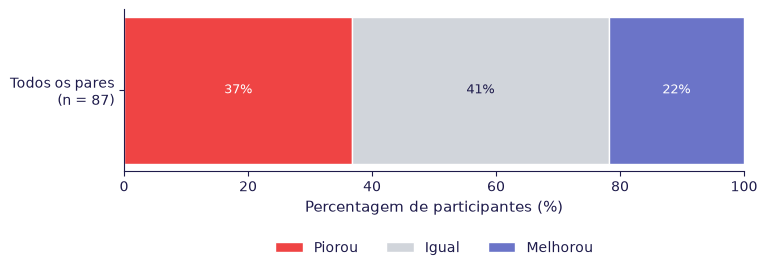

In [39]:
#Figuras: sem e com separação --------------------------------
figura_mip({"Todos os pares": prim}, "4_mip_primaria.png")

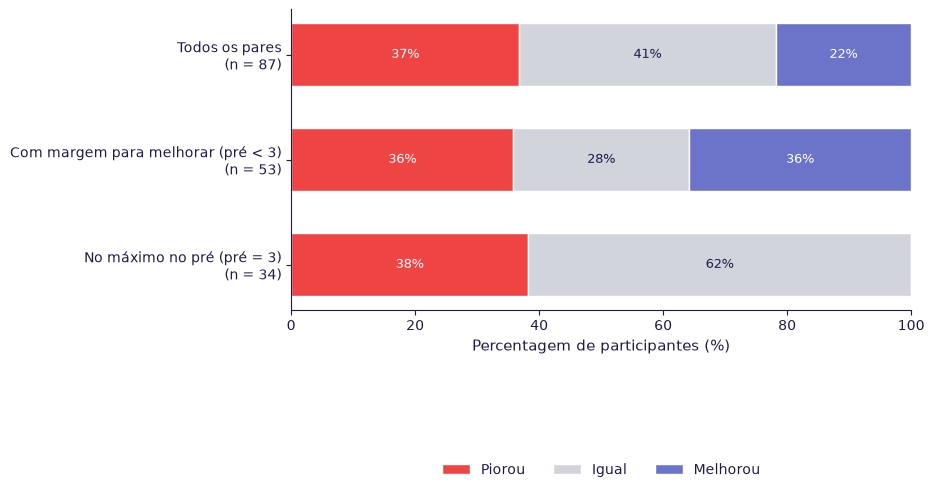

In [40]:
figura_mip(grupos_mip, "4_mip_primaria_por_margem.png")

In [41]:
ids_pares = prim["participant_id"]
r_pares = respostas[respostas["participant_id"].isin(ids_pares)
                    & respostas["momento"].astype(str).isin(["pre", "pos"])]
pd.crosstab(r_pares["exercicio"], r_pares["momento"], values=r_pares["correct"], aggfunc="mean").round(2)


momento,pre,pos
exercicio,,
ex1,0.78,0.60
ex2,0.55,0.45
ex3,0.45,0.44


### 4.3. Descrição da não resolução

In [42]:
prim = larga[larga["par_pre_pos"] == 1]

# Quantos exercícios não resolvidos, no pré vs no pós
print(pd.crosstab(prim["n_nao_resolvidos_pre"], prim["n_nao_resolvidos_pos"],
                  rownames=["Não resolvidos no pré"], colnames=["Não resolvidos no pós"], margins=True))
print(prim[["sem_resolucao_pre", "sem_resolucao_pos"]].sum())

Não resolvidos no pós  0.0  1.0  2.0  3.0  All
Não resolvidos no pré                         
0.0                     45    1    2    9   57
1.0                      6    5    2    5   18
2.0                      3    0    1    5    9
3.0                      2    1    0    0    3
All                     56    7    5   19   87
sem_resolucao_pre     3.0
sem_resolucao_pos    19.0
dtype: float64


In [43]:
# Quanto da descida vem de quem não resolveu nada no pós?
direcao = np.sign(prim["conhecimento_pos"] - prim["conhecimento_pre"]).map(
    {-1: "Piorou", 0: "Igual", 1: "Melhorou"})
print(pd.crosstab(direcao, prim["sem_resolucao_pos"], margins=True,
                  colnames=["Nenhum resolvido no pós (1 = sim)"]))

Nenhum resolvido no pós (1 = sim)  0.0  1.0  All
row_0                                           
Igual                               34    2   36
Melhorou                            19    0   19
Piorou                              15   17   32
All                                 68   19   87


In [44]:
# Quem são os 19
print(pd.crosstab(prim["turno"], prim["sem_resolucao_pos"], margins=True))
print(prim.groupby("sem_resolucao_pos")[["pre_fill_time", "pos_fill_time",
                                         "game_time_min", "conhecimento_pre"]].median())
print(pd.crosstab(prim["sem_resolucao_pos"], prim["game_finished"], margins=True))

sem_resolucao_pos  0.0  1.0  All
turno                           
1.0                 25    4   29
2.0                 15   13   28
3.0                 28    2   30
All                 68   19   87
                   pre_fill_time  pos_fill_time  game_time_min  \
sem_resolucao_pos                                                
0.0                        14.04           6.58      30.708333   
1.0                        18.77           3.58      34.850000   

                   conhecimento_pre  
sem_resolucao_pos                    
0.0                             2.0  
1.0                             1.0  
game_finished      0.0  1.0  All
sem_resolucao_pos               
0.0                 21   29   50
1.0                 11    3   14
All                 32   32   64


### 4.4. Análise Exploratória Post-hoc


  EXPLORATÓRIA (post hoc): sem participantes que não resolveram nenhum exercício num dos momentos
Descriptive Statistics (n = 65)
  pre  M = 1.89 (DP = 1.12)   Mdn = 2.00 [1.00; 3.00]
  pos  M = 1.88 (DP = 1.18)   Mdn = 2.00 [1.00; 3.00]

Ranks (método de Pratt: zeros incluídos na ordenação)
                             N  Mean Rank  Sum of Ranks
Negative Ranks (pós < pré)  15      51.17         767.5
Positive Ranks (pós > pré)  16      48.91         782.5
Ties (pós = pré)            34        NaN           NaN
Total                       65        NaN           NaN

Test Statistics
  Z = 0.053
  Asymp. Sig. (2-tailed) = 0.9574
  Rank-biserial r = 0.010
  Diferença média = -0.02  IC 95% [-0.25; 0.20]
  Mediana das diferenças = 0.00  IC 95% [0.00; 0.00]


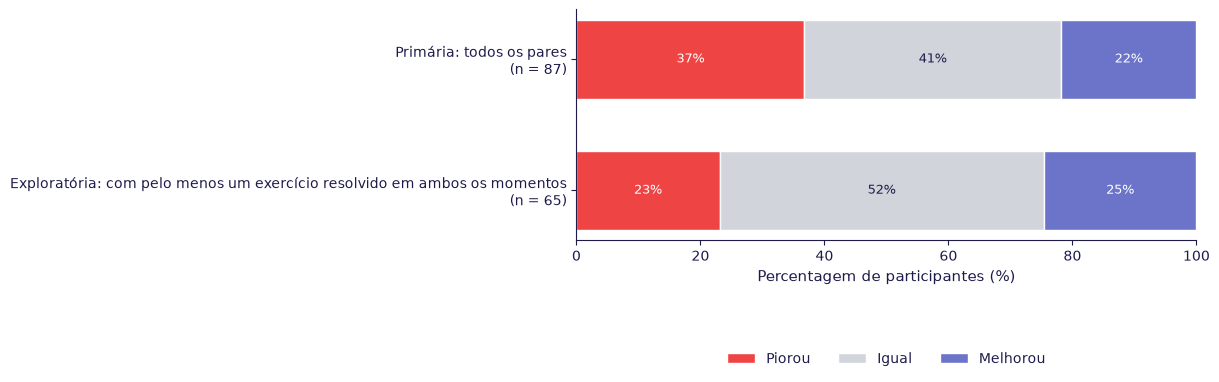

In [45]:
expl = prim[(prim["sem_resolucao_pre"] == 0) & (prim["sem_resolucao_pos"] == 0)]
res_expl = wilcoxon_pratt_spss(
    expl["conhecimento_pre"], expl["conhecimento_pos"],
    "EXPLORATÓRIA (post hoc): sem participantes que não resolveram nenhum exercício num dos momentos")

figura_mip({"Primária: todos os pares": prim,
            "Exploratória: com pelo menos um exercício resolvido em ambos os momentos": expl},
           "4_mip_primaria_vs_exploratoria.png")

### 4.5. Tabela APA

In [46]:
# Tabela APA do resultado primário ---------------------------
def linha_apa(r):
    """Uma linha APA a partir do resultado de wilcoxon_pratt_spss."""
    return {"Análise": r["analise"], "n": r["n"],
            "Pré Mdn": fmt(r["Mdn_pre"], 1), "Pós Mdn": fmt(r["Mdn_pos"], 1),
            "Melhorou / Igual / Piorou": f"{r['n_melhorou']} / {r['n_igual']} / {r['n_piorou']}",
            "Z": fmt(r["Z"]), "p": fmt_p(r["p"]), "r_rb": fmt(r["rbc"], 2, False),
            "Dif. média [IC 95%]": f"{fmt(r['dif_media'])} [{fmt(r['dif_media_ic_inf'])}; {fmt(r['dif_media_ic_sup'])}]",
            "Mdn dif. [IC 95%]": f"{fmt(r['dif_mediana'], 1)} [{fmt(r['dif_mediana_ic_inf'], 1)}; {fmt(r['dif_mediana_ic_sup'], 1)}]"}
 
tabela_primaria = pd.DataFrame([linha_apa(res_primaria), linha_apa(res_expl)])
print(tabela_primaria.to_string(index=False))
tabela_primaria.to_excel(OUT_TAB / "4_primaria_e_exploratoria_apa.xlsx", index=False)

                                                                                        Análise  n Pré Mdn Pós Mdn Melhorou / Igual / Piorou     Z    p r_rb  Dif. média [IC 95%] Mdn dif. [IC 95%]
                                                    Conhecimento: pré vs pós (análise primária) 87     2,0     1,0              19 / 36 / 32 -2,00 ,046 -,29 -0,30 [-0,56; -0,03]    0,0 [0,0; 0,0]
EXPLORATÓRIA (post hoc): sem participantes que não resolveram nenhum exercício num dos momentos 65     2,0     2,0              16 / 34 / 15  0,05 ,957  ,01  -0,02 [-0,25; 0,20]    0,0 [0,0; 0,0]


### 4.6. Resultados

**Resultado primário.** O desempenho nos exercícios de conhecimento foi inferior no pós
(Mdn = 1) do que no pré (Mdn = 2) (Wilcoxon, Z = −2,00, p = ,046, r_rb = −,29;
diferença média = −0,30, IC 95% [−0,56; −0,03]). Dos 87 participantes, 19 (21,8%)
melhoraram, 36 (41,4%) mantiveram-se e 32 (36,8%) pioraram. A mediana das diferenças
foi 0 (IC 95% [0; 0]), refletindo o elevado número de participantes sem mudança.
O efeito de teto foi importante: 34 participantes (39,1%) acertaram os três exercícios
no pré e só podiam manter-se ou piorar; destes, 13 (38,2%) pioraram.

**Não resolução no pós.** Por instrução da investigadora, os participantes que não
conseguiam resolver um exercício em tempo útil respondiam 0 e assinalavam "não sei".
Dezanove participantes (21,8%) não resolveram nenhum exercício no pós, contra 3 no pré.
Estes 19 participantes explicam mais de metade das descidas (17 dos 32 que pioraram)
e nenhum melhorou. Concentraram-se no turno 2 (13 de 28; 46,4%, contra 13,8% no turno 1
e 6,7% no turno 3), tiveram um pós mais curto (Mdn = 3,6 vs. 6,6 minutos), demoraram mais
no pré (Mdn = 18,8 vs. 14,0 minutos) e terminaram menos vezes o jogo (3 de 14 com dados
de jogo, contra 29 de 50). O padrão é mais compatível com falta de tempo ou de
disponibilidade no fim da sessão do que com perda de conhecimento.

**Análise exploratória (post hoc, decidida após o resultado primário).** Excluindo os
participantes que não resolveram nenhum exercício no pré ou no pós (n = 65), não houve
mudança entre o pré e o pós (Z = 0,05, p = ,957, r_rb = ,01; diferença média = −0,02,
IC 95% [−0,25; 0,20]): 16 melhoraram, 34 mantiveram-se e 15 pioraram. Esta análise tende
a sobrestimar o desempenho no pós, porque os participantes excluídos tinham menos
conhecimento no pré (Mdn = 1 vs. 2).

**Leitura conjunta.** A análise primária, que trata a não resolução como erro, é o
cenário mais pessimista; a exploratória é o mais otimista. Em conjunto, indicam que a
sessão não produziu uma melhoria imediata mensurável nos exercícios escritos, e que a
descida observada na análise primária resulta sobretudo de participantes que, no fim
da sessão, não resolveram o pós, em particular no turno 2.

**Limitações a considerar na discussão:** medida com apenas 3 itens (ruído elevado e
regressão para a média), efeito de teto, sets não totalmente equivalentes, instrução
de resposta 0 dada individualmente e de forma não padronizada, e o facto de o DILU-IA
ter sido desenhado como intervenção complementar (a aula laboratorial decorreu
depois do pós, e um trabalho curricular de aplicação de diluições; o follow-up avalia o efeito combinado).

## 5. Análise de Sensibilidade

### 5.1. Definição das sensibilidades

In [47]:
# Cada entrada: nome -> (tabela de pares, variável de conhecimento sem _pre/_pos)
prim = larga[larga["par_pre_pos"] == 1]
 
SENSIBILIDADES = {
    "Primária: todos os pares": (prim, "conhecimento"),
    "S1: completaram o jogo": (prim[prim["game_finished"] == 1], "conhecimento"),
    "S2: sem sinalizados por colaboração": (prim[prim["suspeita_colaboracao"] == 0], "conhecimento"),
    "S4: cotação estrita": (prim, "conhecimento_estrito"),
    "S5: ambíguos invertidos": (prim, "conhecimento_amb_inv"),
    "S6: sem desvios no pós": (prim[(prim["pos_sem_tempo"] == 0) & (prim["pos_fora_sessao"] == 0)],
                               "conhecimento"),
}
 
for nome, (dados, var) in SENSIBILIDADES.items():
    print(f"{nome:<40} n = {len(dados)}")
 

Primária: todos os pares                 n = 87
S1: completaram o jogo                   n = 32
S2: sem sinalizados por colaboração      n = 78
S4: cotação estrita                      n = 87
S5: ambíguos invertidos                  n = 87
S6: sem desvios no pós                   n = 80


### 5.2. Wilcoxon para cada análise de sensibilidade

In [48]:
res_sens = []
for nome, (dados, var) in SENSIBILIDADES.items():
    res_sens.append(wilcoxon_pratt_spss(dados[f"{var}_pre"], dados[f"{var}_pos"], nome))


  Primária: todos os pares
Descriptive Statistics (n = 87)
  pre  M = 1.78 (DP = 1.14)   Mdn = 2.00 [1.00; 3.00]
  pos  M = 1.48 (DP = 1.29)   Mdn = 1.00 [0.00; 3.00]

Ranks (método de Pratt: zeros incluídos na ordenação)
                             N  Mean Rank  Sum of Ranks
Negative Ranks (pós < pré)  32      63.50        2032.0
Positive Ranks (pós > pré)  19      59.47        1130.0
Ties (pós = pré)            36        NaN           NaN
Total                       87        NaN           NaN

Test Statistics
  Z = -1.995
  Asymp. Sig. (2-tailed) = 0.0460
  Rank-biserial r = -0.285
  Diferença média = -0.30  IC 95% [-0.56; -0.03]
  Mediana das diferenças = 0.00  IC 95% [0.00; 0.00]

  S1: completaram o jogo
Descriptive Statistics (n = 32)
  pre  M = 2.06 (DP = 1.16)   Mdn = 3.00 [1.00; 3.00]
  pos  M = 2.25 (DP = 0.95)   Mdn = 2.50 [2.00; 3.00]

Ranks (método de Pratt: zeros incluídos na ordenação)
                             N  Mean Rank  Sum of Ranks
Negative Ranks (pós < pré) 

In [49]:
# %% 5.3 Tabela APA: primária, sensibilidades e exploratória ---------
linhas_sens = [linha_apa(r) for r in res_sens] + [linha_apa(res_expl)]
tabela_sens = pd.DataFrame(linhas_sens)
print(tabela_sens.to_string(index=False))
tabela_sens.to_excel(OUT_TAB / "5_sensibilidades_apa.xlsx", index=False)

                                                                                        Análise  n Pré Mdn Pós Mdn Melhorou / Igual / Piorou     Z    p r_rb  Dif. média [IC 95%] Mdn dif. [IC 95%]
                                                                       Primária: todos os pares 87     2,0     1,0              19 / 36 / 32 -2,00 ,046 -,29 -0,30 [-0,56; -0,03]    0,0 [0,0; 0,0]
                                                                         S1: completaram o jogo 32     3,0     2,5               10 / 15 / 7  0,80 ,421  ,20   0,19 [-0,25; 0,62]    0,0 [0,0; 0,0]
                                                            S2: sem sinalizados por colaboração 78     2,0     2,0              15 / 35 / 28 -2,01 ,044 -,31  -0,28 [-0,55; 0,00]    0,0 [0,0; 0,0]
                                                                            S4: cotação estrita 87     1,0     1,0              22 / 36 / 29 -0,72 ,472 -,10  -0,05 [-0,30; 0,20]    0,0 [0,0; 0,0]
                    

### 5.3. Figura: melhorou / igual / piorou em todas as análises

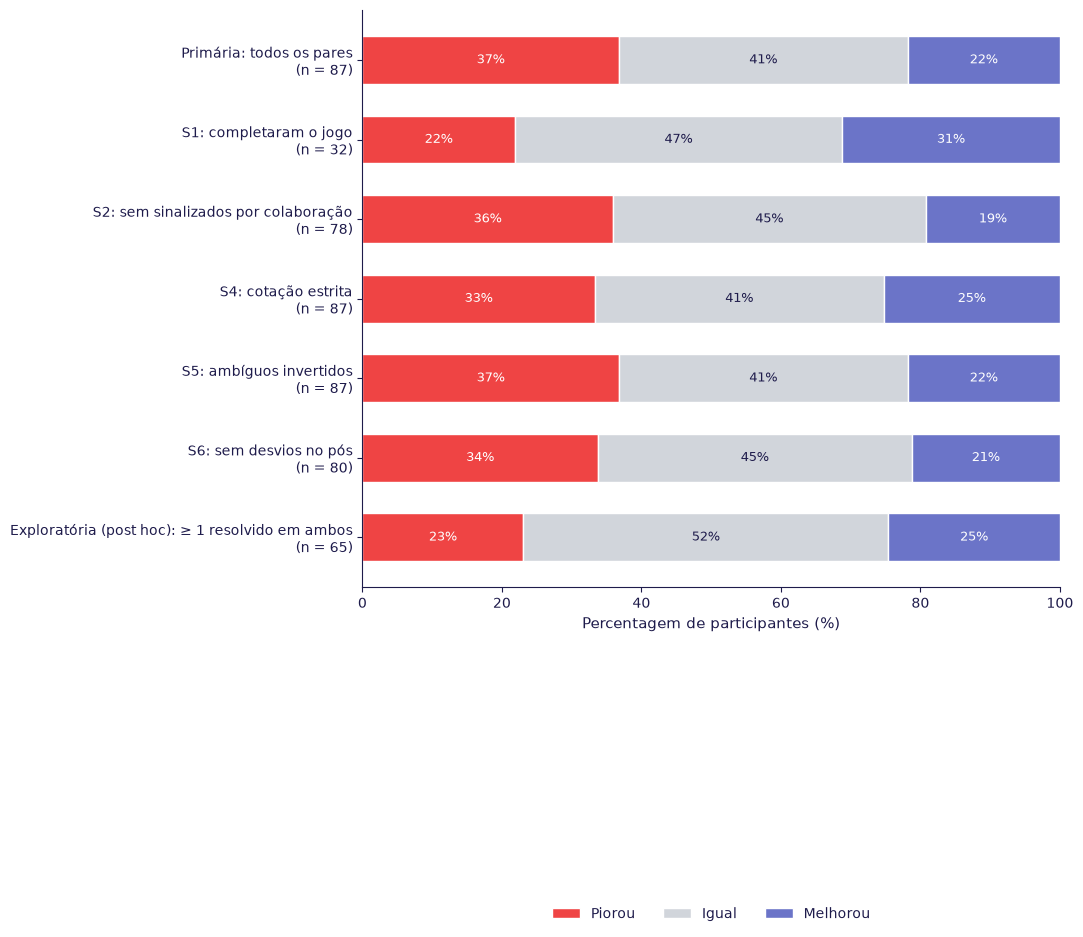

In [50]:
# A figura_mip espera as colunas conhecimento_pre e conhecimento_pos;
# para a S4 e a S5, copiamos a variável certa para esses nomes.
grupos_fig = {}
for nome, (dados, var) in SENSIBILIDADES.items():
    grupos_fig[nome] = pd.DataFrame({"conhecimento_pre": dados[f"{var}_pre"],
                                     "conhecimento_pos": dados[f"{var}_pos"]})
grupos_fig["Exploratória (post hoc): ≥ 1 resolvido em ambos"] = expl
 
figura_mip(grupos_fig, "5_mip_todas_as_analises.png", largura=9)
 

### 5.4. S3: diferença pós − pré por turno (Kruskal-Wallis)

In [51]:
res_s3 = kruskal_spss(prim, "delta_conhecimento", "turno", "S3: diferença pós − pré por turno")


  S3: diferença pós − pré por turno
Ranks
             N  Mean Rank
turno 1.0  29      42.76
turno 2.0  28      30.43
turno 3.0  30      57.87
Total      87        NaN

Test Statistics
  Kruskal-Wallis H = 18.776
  df = 2
  Asymp. Sig. = 0.000
  ε² = 0.218


 Turno  n  Pré Mdn [IIQ]  Pós Mdn [IIQ] Dif. média Melhorou / Igual / Piorou Pré = 3 (teto), n (%) Nenhum resolvido no pós, n (%)
     1 29 1,0 [1,0; 3,0] 1,0 [0,0; 3,0]      -0,34               5 / 13 / 11              9 (31,0)                       4 (13,8)
     2 28 1,5 [1,0; 3,0] 0,0 [0,0; 2,0]      -1,00                4 / 5 / 19             10 (35,7)                      13 (46,4)
     3 30 2,5 [1,2; 3,0] 3,0 [2,0; 3,0]       0,40               10 / 18 / 2             15 (50,0)                        2 (6,7)


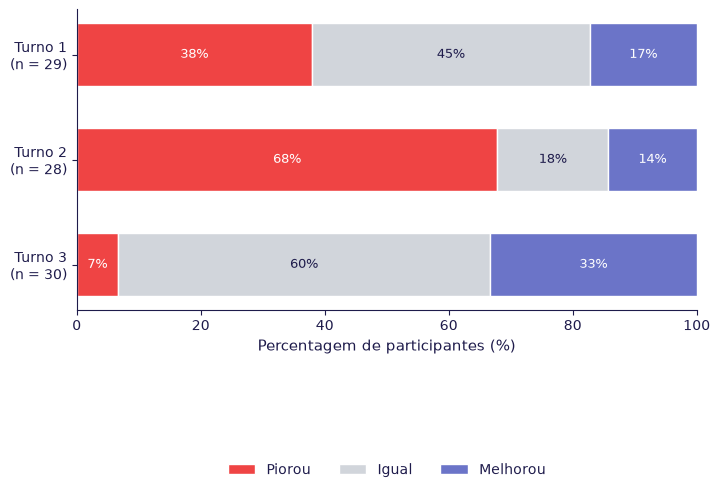

In [52]:
# S3: pré, pós e ganho lado a lado, por turno ------------------
# O turno 3 começou mais alto (secção 1): o ganho lê-se ao lado do teto
linhas_turno = []
for t in sorted(prim["turno"].unique()):
    g = prim[prim["turno"] == t]
    d = g["conhecimento_pos"] - g["conhecimento_pre"]
    linhas_turno.append({
        "Turno": int(t), "n": len(g),
        "Pré Mdn [IIQ]": mdn_iiq(g["conhecimento_pre"], 1),
        "Pós Mdn [IIQ]": mdn_iiq(g["conhecimento_pos"], 1),
        "Dif. média": fmt(d.mean()),
        "Melhorou / Igual / Piorou": f"{(d > 0).sum()} / {(d == 0).sum()} / {(d < 0).sum()}",
        "Pré = 3 (teto), n (%)": n_pct(g["conhecimento_pre"], 3),
        "Nenhum resolvido no pós, n (%)": n_pct(g["sem_resolucao_pos"], 1),
    })
tabela_turno = pd.DataFrame(linhas_turno)
print(tabela_turno.to_string(index=False))
tabela_turno.to_excel(OUT_TAB / "5_S3_por_turno.xlsx", index=False)
 
figura_mip({f"Turno {int(t)}": prim[prim["turno"] == t] for t in sorted(prim["turno"].unique())},
           "5_mip_por_turno.png")

### 5.5. Resultados

As sensibilidades pré-especificadas (decisão 23) mostram que a direção do resultado
primário é estável, mas a sua significância e magnitude não o são.

**Robustez da direção.** Excluindo os participantes sinalizados por colaboração (S2,
n = 78), invertendo a decisão sobre as respostas ambíguas (S5) ou excluindo os
participantes com desvios no pós (S6, n = 80), a descida manteve uma magnitude
semelhante à da análise primária (r_rb entre −,28 e −,31; diferença média entre
−0,26 e −0,31), com p entre ,044 e ,067.

**Dependência da cotação.** Com a cotação estrita, sem recuperação da vírgula decimal
nem das unidades (S4), a descida deixou de existir (Z = −0,72, p = ,472, r_rb = −,10;
diferença média = −0,05, IC 95% [−0,30; 0,20]). As respostas recuperadas estavam
sobretudo no pré, pelo que a magnitude da descida observada na análise primária
depende das decisões de cotação.

**Participantes que completaram o jogo (S1, n = 32).** Não houve mudança significativa
(Z = 0,80, p = ,421, r_rb = ,20; diferença média = 0,19, IC 95% [−0,25; 0,62]).
Estes participantes partiram de um nível mais alto (Mdn = 3) e constituem um subgrupo
selecionado; o resultado não permite inferir um efeito do jogo em quem o completa.

**Diferenças entre turnos (S3).** A mudança pré → pós diferiu fortemente entre turnos
(Kruskal-Wallis, H(2) = 18,78, p < ,001, ε² = ,22). O turno 2 teve a maior descida
(diferença média = −1,00; 19 de 28 pioraram), associada à maior proporção de
participantes sem nenhum exercício resolvido no pós (46,4%). O turno 3 foi o único com
melhoria (diferença média = 0,40; 10 melhoraram, 2 pioraram), apesar de 50% dos
participantes já estarem no máximo no pré. O turno 1 teve uma descida intermédia
(−0,34). O turno está confundido com vários fatores de implementação — hora do dia,
experiência crescente da investigadora na condução da sessão, apoio prestado
(incluindo códigos de nível), colaboração entre participantes e possível difusão dos
exercícios — pelo que estas diferenças indicam que as condições de implementação
pesaram fortemente no resultado, sem permitir identificar qual delas.

**Leitura conjunta (secções 4 e 5).** Nenhuma das análises mostra uma melhoria
imediata do conhecimento após a sessão. A descida observada na análise primária é
consistente em direção, mas depende das decisões de cotação (S4) e resulta sobretudo
de participantes que não resolveram o pós (análise exploratória), concentrados no
turno 2. O padrão por turno sugere que o efeito imediato da sessão foi muito sensível
às condições em que foi implementada.

Nota: as sensibilidades são reportadas sem correção para comparações múltiplas
(decisão 23). A análise exploratória foi decidida após o resultado primário.

## 6. Análise em detalhe do conhecimento

### 6.1. Acertar ou errar

In [53]:
ids_pares = larga.loc[larga["par_pre_pos"] == 1, "participant_id"]
r = respostas[respostas["participant_id"].isin(ids_pares)].copy()
r["momento"] = r["momento"].astype(str)          # evita problemas com categorias
r = r[r["momento"].isin(["pre", "pos"])]
EXS = ["ex1", "ex2", "ex3"]
 
def emparelhar(variavel, exercicio):
    """Tabela com uma linha por participante e as colunas 'pre' e 'pos' da variável,
    só com quem tem valor nos dois momentos."""
    sub = r[r["exercicio"] == exercicio]
    largo = sub.pivot(index="participant_id", columns="momento", values=variavel)
    return largo[["pre", "pos"]].dropna()

In [54]:
res_familia1 = []
for ex in EXS:
    res_familia1.append(mcnemar_spss(emparelhar("correct", ex), f"Certo/errado: {ex}"))
 


  Certo/errado: ex1
Crosstab (linhas = pré, colunas = pós; 1 = certo)
pos    0.0  1.0  Total
pre                   
0.0     12    7     19
1.0     23   45     68
Total   35   52     87

  % certo: pré = 78.2%, pós = 59.8%
  Discordantes: 1→0 (b) = 23, 0→1 (c) = 7
  McNemar Test: Exact Sig. (2-sided, binomial) = 0.0052

  Certo/errado: ex2
Crosstab (linhas = pré, colunas = pós; 1 = certo)
pos    0.0  1.0  Total
pre                   
0.0     30    9     39
1.0     18   30     48
Total   48   39     87

  % certo: pré = 55.2%, pós = 44.8%
  Discordantes: 1→0 (b) = 18, 0→1 (c) = 9
  McNemar Test: Exact Sig. (2-sided, binomial) = 0.1221

  Certo/errado: ex3
Crosstab (linhas = pré, colunas = pós; 1 = certo)
pos    0.0  1.0  Total
pre                   
0.0     36   12     48
1.0     13   26     39
Total   49   38     87

  % certo: pré = 44.8%, pós = 43.7%
  Discordantes: 1→0 (b) = 13, 0→1 (c) = 12
  McNemar Test: Exact Sig. (2-sided, binomial) = 1.0000


### 6.2. Estratégias de resolução

In [55]:
# Em cada exercício, categorias com < 5 respostas (pré + pós, nos pares) → "outro".
# 'sem_tempo' é tratado como em falta.
MIN_CATEGORIA = 5
 
# Para descrever (figura e %): só "sem_tempo" fica em falta
r["metodo_descritivo"] = r["strategy"].where(r["strategy"] != "sem_tempo")

# Para os testes: "sem_tempo" e "nao_resolveu" ficam em falta
r["metodo_analise"] = r["strategy"].where(~r["strategy"].isin(["sem_tempo", "nao_resolveu"]))
juncoes = []
for ex in EXS:
    linhas = r["exercicio"] == ex
    contagens = r.loc[linhas, "metodo_analise"].value_counts()
    raras = [cat for cat, n in contagens.items() if n < MIN_CATEGORIA and cat != "outro"]
    r.loc[linhas & r["metodo_analise"].isin(raras), "metodo_analise"] = "outro"
    juncoes.append({"exercicio": ex, "juntas_a_outro": ", ".join(raras) or "nenhuma"})
print(pd.DataFrame(juncoes).to_string(index=False))

exercicio juntas_a_outro
      ex1        nenhuma
      ex2        nenhuma
      ex3        nenhuma


In [56]:
# Distribuição descritiva dos métodos (nos pares), por exercício e momento
dist_metodos = (pd.crosstab([r["exercicio"], r["momento"]], r["metodo_descritivo"],
                            normalize="index") * 100).round(1)
print(dist_metodos.to_string())
dist_metodos.to_excel(OUT_TAB / "6_metodos_distribuicao_pct.xlsx")

metodo_descritivo  esquema  etapas  formula  nao_resolveu  regra3  tentativa_erro
exercicio momento                                                                
ex1       pos          3.5     0.0     70.6          10.6     7.1             8.2
          pre          2.3     0.0     82.8           4.6     4.6             5.7
ex2       pos          4.8     0.0     69.9          12.0     7.2             6.0
          pre          1.1     0.0     72.4          10.3     9.2             6.9
ex3       pos          2.4    17.1     43.9          15.9    11.0             9.8
          pre          5.7    32.2     24.1          20.7     5.7            11.5


In [57]:
for ex in EXS:
    res_familia1.append(stuart_maxwell_spss(emparelhar("metodo_analise", ex), f"Métodos: {ex}"))


  Métodos: ex1
Crosstab (linhas = pré, colunas = pós)
pos             esquema  formula  regra3  tentativa_erro
pre                                                     
esquema               1        1       0               0
formula               2       51       4               4
regra3                0        1       2               1
tentativa_erro        0        3       0               2

  Stuart-Maxwell χ² = 1.695, df = 3, Asymp. Sig. = 0.6380

  Métodos: ex2
Crosstab (linhas = pré, colunas = pós)
pos             esquema  formula  regra3  tentativa_erro
pre                                                     
esquema               0        1       0               0
formula               3       44       4               4
regra3                1        6       1               0
tentativa_erro        0        3       1               1

  Stuart-Maxwell χ² = 1.968, df = 3, Asymp. Sig. = 0.5791

  Métodos: ex3
Crosstab (linhas = pré, colunas = pós)
pos             esquema  etapas  

### 6.3. Analise exploratoria: Erro de volume final do ex2

In [58]:
res_familia1.append(mcnemar_spss(emparelhar("volume_final", "ex2"),
                                 "Volume final em vez de volume a adicionar: ex2 (exploratório)",
                                 rotulo_1="respondeu o volume final"))


  Volume final em vez de volume a adicionar: ex2 (exploratório)
Crosstab (linhas = pré, colunas = pós; 1 = respondeu o volume final)
pos    0.0  1.0  Total
pre                   
0.0     70    7     77
1.0      5    5     10
Total   75   12     87

  % respondeu o volume final: pré = 11.5%, pós = 13.8%
  Discordantes: 1→0 (b) = 5, 0→1 (c) = 7
  McNemar Test: Exact Sig. (2-sided, binomial) = 0.7744


### 6.4. Correção de Benjamini-Hochberg e Tabela APA

In [59]:
fam1 = pd.DataFrame(res_familia1)
calculaveis = fam1["p"].notna()
print(f"Testes calculáveis na família 1: {calculaveis.sum()} de {len(fam1)}")
 
fam1["p_BH"] = np.nan
fam1.loc[calculaveis, "p_BH"] = multipletests(fam1.loc[calculaveis, "p"], method="fdr_bh")[1]
print(fam1.round(4).to_string(index=False))

Testes calculáveis na família 1: 7 de 7
                                                        teste           tipo  n  pct_pre  pct_pos  b_piorou  c_melhorou  estatistica  gl      p   p_BH
                                            Certo/errado: ex1        McNemar 87  78.1609  59.7701      23.0         7.0          NaN NaN 0.0052 0.0366
                                            Certo/errado: ex2        McNemar 87  55.1724  44.8276      18.0         9.0          NaN NaN 0.1221 0.2848
                                            Certo/errado: ex3        McNemar 87  44.8276  43.6782      13.0        12.0          NaN NaN 1.0000 1.0000
                                                 Métodos: ex1 Stuart-Maxwell 72      NaN      NaN       NaN         NaN       1.6950 3.0 0.6380 0.8933
                                                 Métodos: ex2 Stuart-Maxwell 69      NaN      NaN       NaN         NaN       1.9679 3.0 0.5791 0.8933
                                                 Métod

In [60]:
def resumo_teste(linha):
    if linha["tipo"] == "McNemar":
        if pd.isna(linha["p"]):
            return "—"
        return f"{fmt(linha['pct_pre'], 1)}% → {fmt(linha['pct_pos'], 1)}% (b = {int(linha['b_piorou'])}, c = {int(linha['c_melhorou'])})"
    if pd.isna(linha["p"]):
        return "não calculável"
    return f"χ²({int(linha['gl'])}) = {fmt(linha['estatistica'])}"
 
tabela_fam1 = pd.DataFrame({
    "Teste": fam1["teste"],
    "n": fam1["n"],
    "Resultado": fam1.apply(resumo_teste, axis=1),
    "p": fam1["p"].apply(fmt_p),
    "p (BH)": fam1["p_BH"].apply(fmt_p),
})
print(tabela_fam1.to_string(index=False))
tabela_fam1.to_excel(OUT_TAB / "6_familia1_apa.xlsx", index=False)

                                                        Teste  n                      Resultado     p p (BH)
                                            Certo/errado: ex1 87  78,2% → 59,8% (b = 23, c = 7)  ,005   ,037
                                            Certo/errado: ex2 87  55,2% → 44,8% (b = 18, c = 9)  ,122   ,285
                                            Certo/errado: ex3 87 44,8% → 43,7% (b = 13, c = 12) 1,000  1,000
                                                 Métodos: ex1 72                   χ²(3) = 1,70  ,638   ,893
                                                 Métodos: ex2 69                   χ²(3) = 1,97  ,579   ,893
                                                 Métodos: ex3 61                  χ²(4) = 11,81  ,019   ,066
Volume final em vez de volume a adicionar: ex2 (exploratório) 87   11,5% → 13,8% (b = 5, c = 7)  ,774   ,903


### 6.5. Figuras

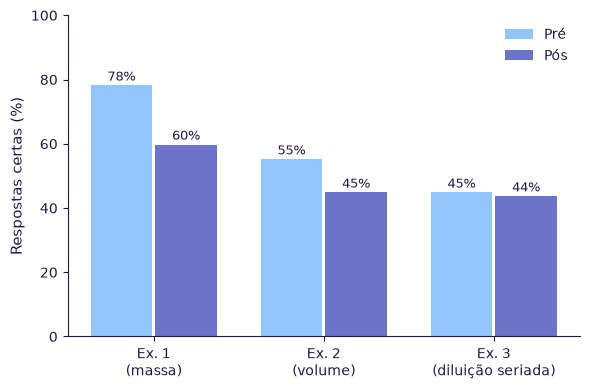

In [61]:
# Figura: % de respostas certas por exercício e momento 
pct = r.groupby(["exercicio", "momento"])["correct"].mean().unstack()[["pre", "pos"]] * 100
 
fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(pct))
for i, (mom, cor, rot) in enumerate([("pre", DILU_ACCENT, "Pré"), ("pos", DILU_BLUE, "Pós")]):
    barras = ax.bar(x + (i - 0.5) * 0.38, pct[mom], width=0.36, color=cor, label=rot)
    for barra, v in zip(barras, pct[mom]):
        ax.text(barra.get_x() + barra.get_width() / 2, v + 1.5, f"{fmt(v, 0)}%",
                ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(["Ex. 1\n(massa)", "Ex. 2\n(volume)", "Ex. 3\n(diluição seriada)"])
ax.set_ylabel("Respostas certas (%)")
ax.set_ylim(0, 100)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(OUT_FIG / "6_acerto_por_exercicio.png", bbox_inches="tight")
plt.show()

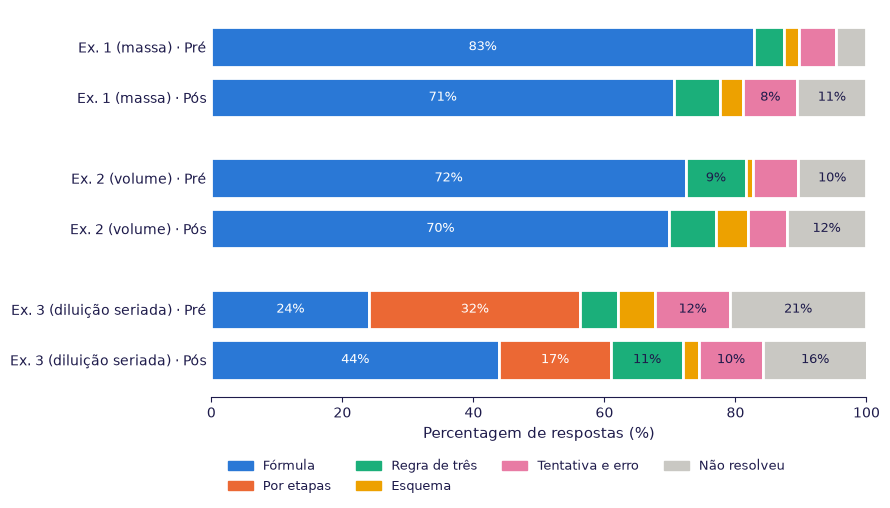

In [62]:
# Figura: distribuição dos métodos por exercício e momento --
# Barras horizontais de 100% (parte do todo): uma linha por exercício × momento.
# Cores categóricas em ordem fixa (validadas para daltonismo, pares adjacentes);
# 'nao_resolveu' em cinzento, porque não é uma estratégia. O mesmo método tem
# sempre a mesma cor. As percentagens vão escritas nos segmentos (≥ 8%) e a
# tabela 6_metodos_distribuicao_pct.xlsx dá todos os valores.
ORDEM_METODOS = ["formula", "etapas", "regra3", "esquema", "tentativa_erro", "outro", "nao_resolveu"]
ROTULOS_METODOS = {"formula": "Fórmula", "etapas": "Por etapas", "regra3": "Regra de três",
                   "esquema": "Esquema", "tentativa_erro": "Tentativa e erro",
                   "outro": "Outro", "nao_resolveu": "Não resolveu"}
CORES_METODOS = {"formula": "#2a78d6", "etapas": "#eb6834", "regra3": "#1baf7a",
                 "esquema": "#eda100", "tentativa_erro": "#e87ba4", "outro": "#6250d6",
                 "nao_resolveu": "#c9c8c3"}
TEXTO_ESCURO = {"regra3", "esquema", "tentativa_erro", "nao_resolveu"}   # fundo claro → texto escuro
 
def figura_metodos(dist, ficheiro):
    """dist: % por (exercicio, momento) × método, como dist_metodos (secção 6.3)."""
    metodos = [m for m in ORDEM_METODOS if m in dist.columns]
    nomes_ex = {"ex1": "Ex. 1 (massa)", "ex2": "Ex. 2 (volume)", "ex3": "Ex. 3 (diluição seriada)"}
    linhas = [(ex, mom) for ex in EXS for mom in ["pre", "pos"]]
    # posições: duas barras por exercício, com um espaço entre exercícios
    y = [i * 1.0 + (i // 2) * 0.6 for i in range(len(linhas))]
 
    fig, ax = plt.subplots(figsize=(9, 5.2))
    for yi, (ex, mom) in zip(y, linhas):
        esquerda = 0.0
        for m in metodos:
            v = float(dist.loc[(ex, mom), m]) if (ex, mom) in dist.index else 0.0
            if v <= 0:
                continue
            ax.barh(yi, v, left=esquerda, height=0.78, color=CORES_METODOS[m],
                    edgecolor="white", linewidth=2)
            if v >= 8:
                ax.text(esquerda + v / 2, yi, f"{fmt(v, 0)}%", ha="center", va="center", fontsize=9,
                        color=DILU_TEXT if m in TEXTO_ESCURO else "white")
            esquerda += v
 
    ax.set_yticks(y)
    ax.set_yticklabels([f"{nomes_ex[ex]} · {'Pré' if mom == 'pre' else 'Pós'}" for ex, mom in linhas])
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentagem de respostas (%)")
    ax.tick_params(axis="y", length=0)
    for lado in ["left"]:
        ax.spines[lado].set_visible(False)
 
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=CORES_METODOS[m], label=ROTULOS_METODOS[m]) for m in metodos],
              ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.13), fontsize=9)
    plt.tight_layout()
    plt.savefig(OUT_FIG / ficheiro, bbox_inches="tight")
    plt.show()
 
figura_metodos(dist_metodos, "6_metodos_por_exercicio.png")

### 6.6. Resultados
**Acerto por exercício (McNemar exato, correção de Benjamini-Hochberg, m = 7).**
A proporção de respostas certas desceu no ex1 (preparação a partir da massa:
78,2% → 59,8%; 23 participantes passaram de certo para errado e 7 de errado para
certo; p = ,005, p BH = ,037). Não houve mudança significativa no ex2 (volume a
adicionar, item de transferência: 55,2% → 44,8%; p = ,122, p BH = ,285) nem no
ex3 (diluição seriada: 44,8% → 43,7%; p = 1,000). A descida do resultado primário
concentra-se, portanto, no ex1, um tipo de problema treinado no nível 1 do jogo,
pelo qual passaram todos os participantes com dados de jogo. A não resolução
aumentou no ex1 (4,6% → 10,6%), mas não explica a totalidade da descida.

**Erro do volume final (ex2, exploratório).** A proporção de participantes que
respondeu o volume final em vez do volume a adicionar não mudou (11,5% → 13,8%;
p = ,774, p BH = ,903).

**Métodos de resolução (Stuart-Maxwell), participantes que resolveram o exercício nos dois momentos).** Nenhuma categoria precisou de ser agrupada (decisão 20). A distribuição dos métodos não mudou no ex1 (n = 72; χ²(3) = 1,70, p = ,638, p BH = ,893) nem no ex2 (n = 69; χ²(3) = 1,97, p = ,579, p BH = ,893), em que a fórmula foi o método dominante nos dois momentos. No ex3 (n = 61), a resolução pela fórmula aumentou de 31,1% para 52,5% e a resolução por etapas diminuiu de 41,0% para 23,0%. A principal mudança foi de etapas para fórmula (11 participantes, contra 3 no sentido inverso). Esta mudança foi significativa sem correção, mas não após a correção para comparações múltiplas (χ²(4) = 11,81, p = ,019, p BH = ,066). Dada a esparsidade das células, o p assintótico deve ser lido com cautela. O exercício 3.1 do jogo apresentava explicitamente a fórmula do fator total (f1 × f2 × f3), o que é compatível com a adoção desse método.

## 7. Afeto e motivação

In [63]:
ESCALAS_F2 = {
    "AP": ("Afeto positivo", 5, 25),
    "AN": ("Afeto negativo", 5, 25),
    "motivacao_intrinseca": ("Motivação intrínseca", 1, 7),
    "regulacao_identificada": ("Regulação identificada", 1, 7),
    "regulacao_externa": ("Regulação externa", 1, 7),
    "desmotivacao": ("amotivação", 1, 7),
}
prim = larga[larga["par_pre_pos"] == 1]

In [64]:
# Wilcoxon por escala ----------------------------------------
# A função usa só quem tem o score nos dois momentos (por isso o n da SIMS
# pode ser menor do que 87, por causa dos itens em falta no pré).
res_familia2 = []
for var, (rotulo, _, _) in ESCALAS_F2.items():
    res = wilcoxon_pratt_spss(prim[f"{var}_pre"], prim[f"{var}_pos"], rotulo)
    res["variavel"] = var
    res_familia2.append(res)


  Afeto positivo
Descriptive Statistics (n = 87)
  pre  M = 15.80 (DP = 4.27)   Mdn = 16.00 [12.50; 19.00]
  pos  M = 16.22 (DP = 4.25)   Mdn = 16.00 [14.00; 19.00]

Ranks (método de Pratt: zeros incluídos na ordenação)
                             N  Mean Rank  Sum of Ranks
Negative Ranks (pós < pré)  36      47.57        1712.5
Positive Ranks (pós > pré)  41      50.26        2060.5
Ties (pós = pré)            10        NaN           NaN
Total                       87        NaN           NaN

Test Statistics
  Z = 0.739
  Asymp. Sig. (2-tailed) = 0.4597
  Rank-biserial r = 0.092
  Diferença média = 0.41  IC 95% [-0.39; 1.20]
  Mediana das diferenças = 0.00  IC 95% [-1.00; 1.00]

  Afeto negativo
Descriptive Statistics (n = 87)
  pre  M = 10.13 (DP = 5.03)   Mdn = 8.00 [6.00; 13.00]
  pos  M = 9.39 (DP = 4.87)   Mdn = 7.00 [5.00; 13.00]

Ranks (método de Pratt: zeros incluídos na ordenação)
                             N  Mean Rank  Sum of Ranks
Negative Ranks (pós < pré)  47      5

In [65]:
# Correção de Benjamini-Hochberg -----------------------------
fam2 = pd.DataFrame(res_familia2)
fam2["p_BH"] = multipletests(fam2["p"], method="fdr_bh")[1]
print(fam2[["analise", "n", "Z", "p", "p_BH", "rbc", "dif_media"]].round(4).to_string(index=False))

               analise  n       Z      p   p_BH     rbc  dif_media
        Afeto positivo 87  0.7394 0.4597 0.6895  0.0922     0.4138
        Afeto negativo 87 -2.8439 0.0045 0.0267 -0.3664    -0.7356
  Motivação intrínseca 86 -0.1408 0.8880 0.8880 -0.0180    -0.0203
Regulação identificada 83 -1.4319 0.1522 0.3043 -0.1857    -0.1867
     Regulação externa 84 -2.1652 0.0304 0.0911 -0.2746    -0.2649
            amotivação 85  0.4271 0.6693 0.8031  0.0546     0.1088


In [66]:
# Tabela APA
def casas(var):
    return 1 if var in ("AP", "AN") else 2       # somas (5–25) com 1 casa; médias (1–7) com 2
 
tabela_fam2 = pd.DataFrame({
    "Escala (amplitude)": [f"{ESCALAS_F2[v][0]} ({ESCALAS_F2[v][1]}–{ESCALAS_F2[v][2]})"
                           for v in fam2["variavel"]],
    "n": fam2["n"],
    "Pré Mdn": [fmt(m, casas(v)) for m, v in zip(fam2["Mdn_pre"], fam2["variavel"])],
    "Pós Mdn": [fmt(m, casas(v)) for m, v in zip(fam2["Mdn_pos"], fam2["variavel"])],
    "Subiu / Igual / Desceu": [f"{a} / {b} / {c}" for a, b, c in
                               zip(fam2["n_melhorou"], fam2["n_igual"], fam2["n_piorou"])],
    "Z": fam2["Z"].apply(fmt),
    "p": fam2["p"].apply(fmt_p),
    "p (BH)": fam2["p_BH"].apply(fmt_p),
    "r_rb": fam2["rbc"].apply(lambda x: fmt(x, 2, False)),
    "Dif. média [IC 95%]": [f"{fmt(m)} [{fmt(i)}; {fmt(s)}]"          # 2 casas: evita "-0,0"
                            for m, i, s in zip(fam2["dif_media"], fam2["dif_media_ic_inf"],
                                               fam2["dif_media_ic_sup"])],
})
print(tabela_fam2.to_string(index=False))
tabela_fam2.to_excel(OUT_TAB / "7_familia2_apa.xlsx", index=False)

          Escala (amplitude)  n Pré Mdn Pós Mdn Subiu / Igual / Desceu     Z    p p (BH) r_rb  Dif. média [IC 95%]
       Afeto positivo (5–25) 87    16,0    16,0           41 / 10 / 36  0,74 ,460   ,690  ,09   0,41 [-0,39; 1,20]
       Afeto negativo (5–25) 87     8,0     7,0           21 / 19 / 47 -2,84 ,004   ,027 -,37  -0,74 [-1,52; 0,07]
  Motivação intrínseca (1–7) 86    3,50    3,62           33 / 16 / 37 -0,14 ,888   ,888 -,02  -0,02 [-0,26; 0,22]
Regulação identificada (1–7) 83    4,25    4,00           31 / 14 / 38 -1,43 ,152   ,304 -,19  -0,19 [-0,43; 0,06]
     Regulação externa (1–7) 84    4,00    3,75            30 / 9 / 45 -2,17 ,030   ,091 -,27 -0,26 [-0,50; -0,03]
            amotivação (1–7) 85    2,50    2,50           35 / 14 / 36  0,43 ,669   ,803  ,05   0,11 [-0,11; 0,34]


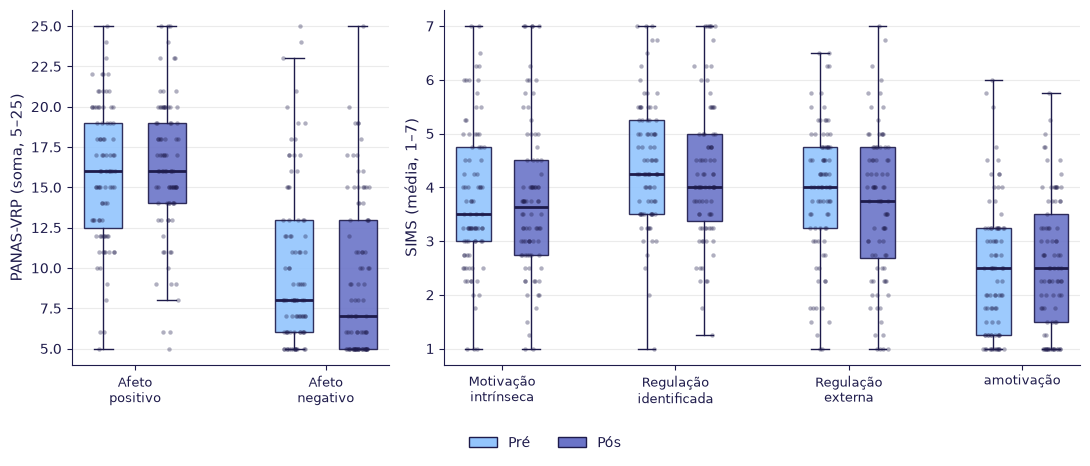

In [67]:
# Figura: pré vs pós, com os participantes individuais --------
# Dois painéis porque as amplitudes são diferentes (PANAS: soma 5–25; SIMS: média 1–7).
# Caixas com a mediana e o IIQ; pontos individuais ligeiramente deslocados.
rng_fig = np.random.default_rng(SEMENTE)
 
def painel(ax, variaveis, titulo, limites):
    for i, var in enumerate(variaveis):
        dados = prim[[f"{var}_pre", f"{var}_pos"]].dropna()
        for j, (mom, cor) in enumerate([("pre", DILU_ACCENT), ("pos", DILU_BLUE)]):
            pos_x = i * 3 + j
            caixa = ax.boxplot(dados[f"{var}_{mom}"], positions=[pos_x], widths=0.6,
                               patch_artist=True, showfliers=False,
                               medianprops=dict(color=DILU_TEXT, linewidth=2),
                               whiskerprops=dict(color=DILU_TEXT), capprops=dict(color=DILU_TEXT))
            caixa["boxes"][0].set(facecolor=cor, edgecolor=DILU_TEXT, alpha=0.9)
            ax.scatter(pos_x + rng_fig.uniform(-0.18, 0.18, len(dados)), dados[f"{var}_{mom}"],
                       s=10, color=DILU_TEXT, alpha=0.35, zorder=3, linewidths=0)
    ax.set_xticks([i * 3 + 0.5 for i in range(len(variaveis))])
    ax.set_xticklabels([ESCALAS_F2[v][0].replace(" ", "\n", 1) for v in variaveis], fontsize=9)
    ax.set_ylim(*limites)
    ax.set_ylabel(titulo)
    ax.grid(axis="y", alpha=0.25)
 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [2, 4]})
painel(ax1, ["AP", "AN"], "PANAS-VRP (soma, 5–25)", (4, 26))
painel(ax2, ["motivacao_intrinseca", "regulacao_identificada", "regulacao_externa", "desmotivacao"],
       "SIMS (média, 1–7)", (0.7, 7.3))
 
from matplotlib.patches import Patch
fig.legend(handles=[Patch(facecolor=DILU_ACCENT, edgecolor=DILU_TEXT, label="Pré"),
                    Patch(facecolor=DILU_BLUE, edgecolor=DILU_TEXT, label="Pós")],
           ncol=2, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(OUT_FIG / "7_afeto_motivacao_pre_pos.png", bbox_inches="tight")
plt.show()
 

### 7.1. Resultados

**Afeto (PANAS-VRP).** O afeto negativo diminuiu entre o pré e o pós (Mdn = 8 → 7;
47 participantes desceram, 21 subiram e 19 mantiveram-se; Wilcoxon, Z = −2,84,
p = ,004, p BH = ,027, r_rb = −,37; mediana das diferenças = −1, IC 95% [−2; 0]).
A diferença média teve um intervalo de confiança que incluía o zero (−0,74,
IC 95% [−1,52; 0,07]): a descida foi consistente na maioria dos participantes, mas
de pequena magnitude, e alguns participantes tiveram subidas grandes. O afeto
negativo partia perto do mínimo da escala (Mdn = 8; mínimo = 5). O afeto positivo
não mudou (Mdn = 16 → 16; p = ,460, p BH = ,690, r_rb = ,09).

**Motivação (SIMS).** A regulação externa desceu sem correção, mas não após correção
para comparações múltiplas (Mdn = 4,00 → 3,75; Z = −2,17, p = ,030, p BH = ,091,
r_rb = −,27; diferença média = −0,26, IC 95% [−0,50; −0,03]). Não houve mudança na
motivação intrínseca (p = ,888), na regulação identificada (p = ,152, p BH = ,304) nem
na amotivação (p = ,669, p BH = ,803).

**Hipóteses pré-especificadas.** O plano previa um aumento do afeto positivo e uma
diminuição da amotivação; nenhuma se confirmou. Ao contrário do piloto, em que a
participação era voluntária, a sessão integrou uma aula curricular obrigatória.

**Interpretação.** A PANAS-VRP foi preenchida imediatamente após os exercícios, pelo
que mede em parte a reação ao próprio teste; a descida do afeto negativo pode refletir
menor nervosismo com um formato já conhecido no pós, o fim da sessão, ou um efeito da
sessão, que o desenho sem grupo de controlo não permite distinguir. Na SIMS, o objeto
avaliado ("esta atividade") não é idêntico nos dois momentos (expectativa vs.
experiência), o que deve ser considerado na leitura das mudanças.

## 8. Analise dados de conhecimento follow-up

### 8.1. Analise descritiva

In [68]:
# 8.1.1 Contexto do follow-up ---------------------------------
fu = participantes[participantes["tem_follow"] == 1].copy()
print("Submissões válidas de follow-up:", len(fu))   # esperado: 44

dias = fu["dias_desde_sessao"]
linhas = [
    {"Variável": "Dias desde a sessão, Mdn [Q1; Q3] (mín.–máx.)",
     "Valor": f"{mdn_iiq(dias, 0)} ({int(dias.min())}–{int(dias.max())})"},
    {"Variável": "Tempo de preenchimento (min), Mdn [Q1; Q3]", "Valor": mdn_iiq(fu["follow_fill_time"], 1)},
    {"Variável": "Praticou depois da aula, n (%)", "Valor": n_pct(fu["practiced"], 1)},
]
for cod, rot in [("exercicios_aula", "com os exercícios da aula"),
                 ("plataforma", "com a plataforma DILU-IA"),
                 ("outros_recursos", "com outros recursos")]:
    linhas.append({"Variável": f"   {rot}, n (%)", "Valor": n_pct(fu["practice_source"], cod)})

for col, rot in [("tech_phone", "telemóvel"), ("tech_tablet", "tablet"),
                 ("tech_computer", "computador (portátil pessoal)")]:
    linhas.append({"Variável": f"Dispositivo: {rot}, n (%)", "Valor": n_pct(fu[col], 1)})
mais_de_um = (fu["tech_n"] > 1).astype(float).where(fu["tech_n"].notna())
linhas.append({"Variável": "Mais do que um dispositivo, n (%)", "Valor": n_pct(mais_de_um, 1)})

util = fu["perceived_usefulness"]
linhas.append({"Variável": "Utilidade da sessão (1–5), Mdn [Q1; Q3]", "Valor": mdn_iiq(util, 0)})
for v in [1, 2, 3, 4, 5]:
    linhas.append({"Variável": f"   {v}, n (%)", "Valor": n_pct(util, v)})
util_alta = (util >= 4).astype(float).where(util.notna())
linhas.append({"Variável": "Útil ou muito útil (4–5), n (%)", "Valor": n_pct(util_alta, 1)})

tabela_fu_contexto = pd.DataFrame(linhas)
print(tabela_fu_contexto.to_string(index=False))
tabela_fu_contexto.to_excel(OUT_TAB / "8_followup_contexto.xlsx", index=False)

Submissões válidas de follow-up: 44
                                         Variável               Valor
    Dias desde a sessão, Mdn [Q1; Q3] (mín.–máx.) 21 [21; 22] (19–22)
       Tempo de preenchimento (min), Mdn [Q1; Q3]     6,6 [4,2; 10,0]
                   Praticou depois da aula, n (%)           30 (68,2)
                 com os exercícios da aula, n (%)           17 (38,6)
                  com a plataforma DILU-IA, n (%)             2 (4,5)
                       com outros recursos, n (%)           11 (25,0)
                    Dispositivo: telemóvel, n (%)           16 (36,4)
                       Dispositivo: tablet, n (%)           19 (43,2)
Dispositivo: computador (portátil pessoal), n (%)           13 (29,5)
                Mais do que um dispositivo, n (%)             4 (9,1)
          Utilidade da sessão (1–5), Mdn [Q1; Q3]            4 [3; 4]
                                         1, n (%)             0 (0,0)
                                         2, n (%)     

In [69]:
# 8.1.2 Distribuição do conhecimento por momento -------------
F1 = larga[larga["par_pre_follow"] == 1]
F2 = larga[larga["tres_momentos"] == 1]
NOMES_MOM = {"pre": "Pré", "pos": "Pós", "follow": "Follow-up"}

def dist_conhecimento(dados, momentos, rotulo):
    """Uma linha por momento: n, Mdn [IIQ], M (DP), n.º de certos (0–3) e não resolução."""
    linhas = []
    for m in momentos:
        s = dados[f"conhecimento_{m}"].dropna()
        cont = s.value_counts().reindex([0, 1, 2, 3], fill_value=0)
        linha = {"Amostra": rotulo, "Momento": NOMES_MOM[m], "n": len(s),
                 "Mdn [Q1; Q3]": mdn_iiq(s, 1), "M (DP)": m_dp(s, 2)}
        for k in range(4):
            linha[f"{k} certos, n (%)"] = f"{cont[k]} ({fmt(100 * cont[k] / len(s), 1)})"
        linha["Nenhum resolvido, n (%)"] = n_pct(dados[f"sem_resolucao_{m}"], 1)
        linhas.append(linha)
    return linhas

tabela_conh_fu = pd.DataFrame(dist_conhecimento(F1, ["pre", "follow"], f"F1 (n = {len(F1)})")
                              + dist_conhecimento(F2, ["pre", "pos", "follow"], f"F2 (n = {len(F2)})"))
print(tabela_conh_fu.to_string(index=False))
tabela_conh_fu.to_excel(OUT_TAB / "8_conhecimento_por_momento.xlsx", index=False)

    Amostra   Momento  n   Mdn [Q1; Q3]      M (DP) 0 certos, n (%) 1 certos, n (%) 2 certos, n (%) 3 certos, n (%) Nenhum resolvido, n (%)
F1 (n = 41)       Pré 41 2,0 [1,0; 3,0] 1,78 (1,08)        6 (14,6)       11 (26,8)       10 (24,4)       14 (34,1)                 3 (7,3)
F1 (n = 41) Follow-up 41 3,0 [2,0; 3,0] 2,63 (0,62)         0 (0,0)         3 (7,3)        9 (22,0)       29 (70,7)                 0 (0,0)
F2 (n = 32)       Pré 32 2,0 [1,0; 3,0] 1,81 (1,03)         3 (9,4)       11 (34,4)        7 (21,9)       11 (34,4)                 0 (0,0)
F2 (n = 32)       Pós 32 1,0 [0,0; 2,2] 1,41 (1,19)       10 (31,2)        7 (21,9)        7 (21,9)        8 (25,0)                4 (12,5)
F2 (n = 32) Follow-up 32 3,0 [2,0; 3,0] 2,62 (0,61)         0 (0,0)         2 (6,2)        8 (25,0)       22 (68,8)                 0 (0,0)


In [70]:
# 8.1.3 Acerto e erros por exercício e momento ---------------
r3 = respostas.copy()
r3["momento"] = r3["momento"].astype(str)

def por_exercicio(ids, momentos, rotulo):
    """% certo, % não resolvido e (ex2) % volume final, por exercício e momento."""
    sub = r3[r3["participant_id"].isin(ids) & r3["momento"].isin(momentos)]
    linhas = []
    for ex in EXS:
        linha = {"Amostra": rotulo, "Exercício": ex}
        for m in momentos:
            s = sub[(sub["exercicio"] == ex) & (sub["momento"] == m)]
            linha[f"{NOMES_MOM[m]}: certo, %"] = fmt(100 * s["correct"].mean(), 1)
            linha[f"{NOMES_MOM[m]}: não resolvido, %"] = fmt(100 * s["nao_resolvido"].mean(), 1)
            if ex == "ex2":
                linha[f"{NOMES_MOM[m]}: volume final, %"] = fmt(100 * s["volume_final"].mean(), 1)
        linhas.append(linha)
    return linhas

tab_ex_F1 = pd.DataFrame(por_exercicio(F1["participant_id"], ["pre", "follow"], "F1"))
tab_ex_F2 = pd.DataFrame(por_exercicio(F2["participant_id"], ["pre", "pos", "follow"], "F2"))
print(tab_ex_F1.to_string(index=False)); print(tab_ex_F2.to_string(index=False))
with pd.ExcelWriter(OUT_TAB / "8_acerto_por_exercicio_followup.xlsx") as w:
    tab_ex_F1.to_excel(w, sheet_name="F1", index=False)
    tab_ex_F2.to_excel(w, sheet_name="F2", index=False)

Amostra Exercício Pré: certo, % Pré: não resolvido, % Follow-up: certo, % Follow-up: não resolvido, % Pré: volume final, % Follow-up: volume final, %
     F1       ex1          78,0                   9,8                87,8                         0,0                  NaN                        NaN
     F1       ex2          61,0                  14,6                85,4                         0,0                 12,2                        9,8
     F1       ex3          39,0                  36,6                90,2                         0,0                  NaN                        NaN
Amostra Exercício Pré: certo, % Pré: não resolvido, % Pós: certo, % Pós: não resolvido, % Follow-up: certo, % Follow-up: não resolvido, % Pré: volume final, % Pós: volume final, % Follow-up: volume final, %
     F2       ex1          87,5                   3,1          65,6                  12,5                90,6                         0,0                  NaN                  NaN              

In [71]:
# Distribuição dos métodos (F2), por exercício e momento; sem_tempo em falta
m3 = r3[r3["participant_id"].isin(F2["participant_id"])].copy()
# Para descrever (figura e %): só "sem_tempo" fica em falta
m3["metodo_descritivo"] = m3["strategy"].where(m3["strategy"] != "sem_tempo")

# Para os testes: "sem_tempo" e "nao_resolveu" ficam em falta
m3["metodo_analise"] = m3["strategy"].where(~m3["strategy"].isin(["sem_tempo", "nao_resolveu"]))
dist_metodos_fu = (pd.crosstab([m3["exercicio"], m3["momento"]], m3["metodo_descritivo"],
                               normalize="index") * 100).round(1)
dist_metodos_fu = dist_metodos_fu.reindex([(ex, m) for ex in EXS for m in ["pre", "pos", "follow"]])
print(dist_metodos_fu.to_string())
dist_metodos_fu.to_excel(OUT_TAB / "8_metodos_tres_momentos_pct.xlsx")

metodo_descritivo  esquema  etapas  formula  nao_resolveu  regra3  tentativa_erro
exercicio momento                                                                
ex1       pre          3.1     0.0     87.5           0.0     6.2             3.1
          pos          3.1     0.0     75.0           9.4     9.4             3.1
          follow       0.0     0.0     96.9           0.0     3.1             0.0
ex2       pre          3.1     0.0     78.1           6.2     9.4             3.1
          pos          3.2     0.0     71.0          12.9     9.7             3.2
          follow       0.0     0.0     93.8           0.0     6.2             0.0
ex3       pre          9.4    25.0     28.1          18.8     9.4             9.4
          pos          6.7    23.3     43.3          16.7    10.0             0.0
          follow       9.4    53.1     31.2           0.0     3.1             3.1


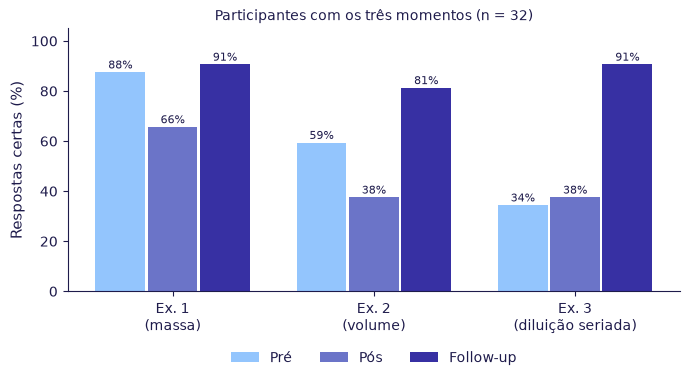

In [72]:
pct = (m3.groupby(["exercicio", "momento"])["correct"].mean().unstack()[["pre", "pos", "follow"]] * 100)
CORES_MOM = [("pre", DILU_ACCENT, "Pré"), ("pos", DILU_BLUE, "Pós"), ("follow", DILU_DARK, "Follow-up")]

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(pct))
largura = 0.26
for i, (mom, cor, rot) in enumerate(CORES_MOM):
    barras = ax.bar(x + (i - 1) * largura, pct[mom], width=largura * 0.95, color=cor, label=rot)
    for barra, v in zip(barras, pct[mom]):
        ax.text(barra.get_x() + barra.get_width() / 2, v + 1.5, f"{fmt(v, 0)}%", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(["Ex. 1\n(massa)", "Ex. 2\n(volume)", "Ex. 3\n(diluição seriada)"])
ax.set_ylabel("Respostas certas (%)")
ax.set_ylim(0, 105)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.set_title(f"Participantes com os três momentos (n = {len(F2)})", fontsize=10)
plt.tight_layout()
plt.savefig(OUT_FIG / "8_acerto_por_exercicio_tres_momentos.png", bbox_inches="tight")
plt.show()

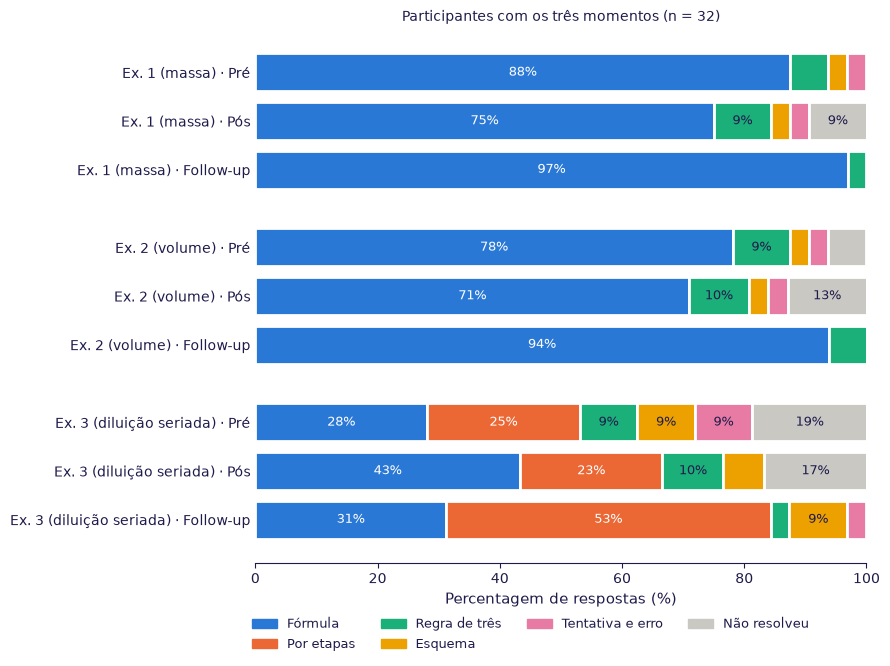

In [73]:
def figura_metodos_momentos(dist, momentos, ficheiro, titulo=None):
    """Barras de 100% por exercício × momento, agrupadas por exercício (ordem temporal dentro de cada grupo)."""
    metodos = [m for m in ORDEM_METODOS if m in dist.columns]
    nomes_ex = {"ex1": "Ex. 1 (massa)", "ex2": "Ex. 2 (volume)", "ex3": "Ex. 3 (diluição seriada)"}
    linhas = [(ex, mom) for ex in EXS for mom in momentos]
    k = len(momentos)
    y = [i + (i // k) * 0.6 for i in range(len(linhas))]          # espaço entre exercícios

    fig, ax = plt.subplots(figsize=(9, 0.55 * len(linhas) + 1.8))
    for yi, (ex, mom) in zip(y, linhas):
        esquerda = 0.0
        for m in metodos:
            v = float(dist.loc[(ex, mom), m]) if (ex, mom) in dist.index else 0.0
            if v <= 0:
                continue
            ax.barh(yi, v, left=esquerda, height=0.78, color=CORES_METODOS[m], edgecolor="white", linewidth=2)
            if v >= 8:
                ax.text(esquerda + v / 2, yi, f"{fmt(v, 0)}%", ha="center", va="center", fontsize=9,
                        color=DILU_TEXT if m in TEXTO_ESCURO else "white")
            esquerda += v

    ax.set_yticks(y)
    ax.set_yticklabels([f"{nomes_ex[ex]} · {NOMES_MOM[mom]}" for ex, mom in linhas])
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentagem de respostas (%)")
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    if titulo:
        ax.set_title(titulo, fontsize=10)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=CORES_METODOS[m], label=ROTULOS_METODOS[m]) for m in metodos],
              ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.08), fontsize=9)
    plt.tight_layout()
    plt.savefig(OUT_FIG / ficheiro, bbox_inches="tight")
    plt.show()

figura_metodos_momentos(dist_metodos_fu, ["pre", "pos", "follow"], "8_metodos_tres_momentos.png",
                        titulo=f"Participantes com os três momentos (n = {len(F2)})")

#### 8.1.1. Resultados: descritivos do follow-up

**Contexto.** Foram analisadas 44 submissões válidas, respondidas em mediana 21 dias depois da sessão (19–22) e preenchidas em 6,6 minutos (IIQ 4,2–10,0). Todos responderam fora da sessão, sem supervisão e sem limite de tempo.
- Estudo posterior: 68,2% disseram ter voltado a praticar, sobretudo com os exercícios da aula (38,6%) ou com outros recursos (25,0%); só 2 (4,5%) usaram a plataforma DILU-IA.
- Dispositivos na sessão: tablet (43,2%), telemóvel (36,4%) e portátil pessoal (29,5%); 9,1% usaram mais do que um.
- Utilidade da sessão: mediana de 4 em 5 (IIQ 3–4); 54,5% consideraram-na útil ou muito útil, 38,6% deram uma resposta neutra e ninguém escolheu o valor mínimo.

**Conhecimento por momento.**
- Na amostra pré–follow-up (F1, n = 41), a mediana passou de 2 para 3 exercícios certos. A proporção com os três certos subiu de 34,1% para 70,7%, e ninguém ficou com zero no follow-up (14,6% no pré).
- Na amostra com os três momentos (F2, n = 32), a trajetória foi descida no pós (M = 1,81 → 1,41) e subida no follow-up (M = 2,62), com a proporção de três certos em 34,4% → 25,0% → 68,8%.
- Não houve nenhum exercício por resolver no follow-up, contra 12,5% de participantes sem nenhum exercício resolvido no pós.

**Por exercício (F2).**
- O acerto no ex1 desceu no pós e recuperou no follow-up (87,5% → 65,6% → 90,6%), e o mesmo aconteceu no ex2 (59,4% → 37,5% → 81,2%).
- O ex3 só mudou no follow-up (34,4% → 37,5% → 90,6%).
- O erro do volume final no ex2 foi de 15,6%, 25,0% e 12,5%.

**Métodos de resolução (F2).**
- No ex1 e no ex2, a fórmula foi dominante nos três momentos e chegou a 94–97% no follow-up.
- No ex3, a resolução por fórmula subiu no pós (28,1% → 43,3%) e voltou a descer no follow-up (31,2%). A resolução por etapas (cálculo de cada diluição) duplicou no follow-up (25,0% → 23,3% → 53,1%), e a não resolução desapareceu (18,8% → 0%).
- No follow-up, o ex3 foi resolvido sobretudo diluição a diluição, e não pela fórmula do fator total apresentada no jogo.

**Leitura.** Estes valores são descritivos; os testes estão na secção 8.2. Três fatores limitam a interpretação:
1. O follow-up foi respondido em casa, sem limite de tempo nem supervisão, enquanto o pós foi respondido no fim de uma sessão com falta de tempo para parte dos participantes.
2. O follow-up mede o percurso completo (sessão DILU-IA, aula laboratorial e estudo posterior), e não o efeito do DILU-IA isoladamente.
3. O ex3 do follow-up (fator 1:10) era aritmeticamente mais fácil do que os do pré e do pós (F7), o que é compatível com parte da subida desse exercício.

### 8.2. Teste comparativos do conhecimento no follow-up

In [74]:
# 0. funções auxiliares
def emparelhar_momentos(variavel, ex, ids, m1, m2):
    """Tabela pré/pós genérica para as funções McNemar: m1 → coluna 'pre', m2 → coluna 'pos'."""
    sub = r3[(r3["exercicio"] == ex) & r3["participant_id"].isin(ids)]
    largo = sub.pivot(index="participant_id", columns="momento", values=variavel)
    return largo[[m1, m2]].dropna().set_axis(["pre", "pos"], axis=1)

def usou_formula_largo(ex, ids):
    """1 = fórmula; 0 = outro método; vazio = não resolveu ou sem tempo (F11). Só completos nos 3 momentos."""
    sub = r3[(r3["exercicio"] == ex) & r3["participant_id"].isin(ids)].copy()
    sub["usou_formula"] = (sub["strategy"] == "formula").astype(float)
    sub.loc[sub["strategy"].isin(["nao_resolveu", "sem_tempo"]) | sub["strategy"].isna(), "usou_formula"] = np.nan
    largo = sub.pivot(index="participant_id", columns="momento", values="usou_formula")[["pre", "pos", "follow"]]
    largo.columns.name = None
    return largo.dropna()


In [75]:
res_f3 = []

# (1) Pré vs follow-up (F1)
r_ = wilcoxon_pratt_spss(F1["conhecimento_pre"], F1["conhecimento_follow"],
                         "F1: conhecimento pré vs follow-up (pre = pré; pos = follow-up)")
res_f3.append({"teste": "Conhecimento: pré vs follow-up", "amostra": "F1", "tipo": "Wilcoxon", **r_})

# (2–4) Certo/errado por exercício, pré vs follow-up (F1)
for ex in EXS:
    r_ = mcnemar_spss(emparelhar_momentos("correct", ex, F1["participant_id"], "pre", "follow"),
                      f"F1: certo/errado {ex}, pré vs follow-up (colunas: pré → follow-up)")
    res_f3.append({**r_, "teste": f"Certo/errado {ex}: pré vs follow-up", "amostra": "F1"})

# (5) Pós vs follow-up (F2)
r_ = wilcoxon_pratt_spss(F2["conhecimento_pos"], F2["conhecimento_follow"],
                         "F2: conhecimento pós vs follow-up (pre = pós; pos = follow-up)")
res_f3.append({"teste": "Conhecimento: pós vs follow-up", "amostra": "F2", "tipo": "Wilcoxon", **r_})

# (6–8) Usou fórmula nos três momentos (F2); McNemar par a par só descritivo (F12)
res_f3_desc = []
for ex in EXS:
    largo = usou_formula_largo(ex, F2["participant_id"])
    res_f3.append({**cochran_spss(largo, f"F2: usou fórmula nos três momentos, {ex}"),
                   "teste": f"Usou fórmula {ex}: três momentos", "amostra": "F2"})
    for m1, m2 in [("pre", "pos"), ("pos", "follow"), ("pre", "follow")]:
        res_f3_desc.append(mcnemar_spss(largo[[m1, m2]].set_axis(["pre", "pos"], axis=1),
                                        f"F2: usou fórmula {ex}, {NOMES_MOM[m1]} → {NOMES_MOM[m2]} (descritivo)",
                                        rotulo_1="usou fórmula"))

# (9) Estudo ativo: mudança pré → follow-up, praticou vs não praticou (F1)
est = F1.dropna(subset=["practiced"]).copy()
est["grupo_estudo"] = est["practiced"].map({1.0: "Praticou", 0.0: "Não praticou"})
r_ = mann_whitney_spss(est, "delta_pre_follow_conhecimento", "grupo_estudo",
                       {"Praticou": "Praticou", "Não praticou": "Não praticou"},
                       "F1: mudança pré → follow-up, praticou vs não praticou")
res_f3.append({"teste": "Estudo ativo: mudança pré → follow-up", "amostra": "F1",
               "tipo": "Mann-Whitney", "n": r_["n1"] + r_["n2"], **r_})


  F1: conhecimento pré vs follow-up (pre = pré; pos = follow-up)
Descriptive Statistics (n = 41)
  pre  M = 1.78 (DP = 1.08)   Mdn = 2.00 [1.00; 3.00]
  pos  M = 2.63 (DP = 0.62)   Mdn = 3.00 [2.00; 3.00]

Ranks (método de Pratt: zeros incluídos na ordenação)
                             N  Mean Rank  Sum of Ranks
Negative Ranks (pós < pré)   4      24.38          97.5
Positive Ranks (pós > pré)  24      28.02         672.5
Ties (pós = pré)            13        NaN           NaN
Total                       41        NaN           NaN

Test Statistics
  Z = 3.823
  Asymp. Sig. (2-tailed) = 0.0001
  Rank-biserial r = 0.747
  Diferença média = 0.85  IC 95% [0.49; 1.22]
  Mediana das diferenças = 1.00  IC 95% [0.00; 1.00]

  F1: certo/errado ex1, pré vs follow-up (colunas: pré → follow-up)
Crosstab (linhas = pré, colunas = pós; 1 = certo)
pos    0.0  1.0  Total
pre                   
0.0      3    6      9
1.0      2   30     32
Total    5   36     41

  % certo: pré = 78.0%, pós = 87.8%


In [76]:
fam3 = pd.DataFrame(res_f3)
calc = fam3["p"].notna()
print(f"Testes calculáveis na família 3: {calc.sum()} de {len(fam3)}")
fam3["p_BH"] = np.nan
fam3.loc[calc, "p_BH"] = multipletests(fam3.loc[calc, "p"], method="fdr_bh")[1]

def resumo_f3(l):
    if l["tipo"] == "Wilcoxon":
        return (f"Mdn {fmt(l['Mdn_pre'], 1)} → {fmt(l['Mdn_pos'], 1)}; "
                f"{int(l['n_melhorou'])}/{int(l['n_igual'])}/{int(l['n_piorou'])}; "
                f"Z = {fmt(l['Z'])}; r_rb = {fmt(l['rbc'], 2, False)}; "
                f"dif. média = {fmt(l['dif_media'])} [{fmt(l['dif_media_ic_inf'])}; {fmt(l['dif_media_ic_sup'])}]")
    if l["tipo"] == "McNemar":
        if pd.isna(l["p"]):
            return "sem pares discordantes"
        return f"{fmt(l['pct_pre'], 1)}% → {fmt(l['pct_pos'], 1)}% (b = {int(l['b_piorou'])}, c = {int(l['c_melhorou'])})"
    if l["tipo"] == "Cochran":
        if pd.isna(l["p"]):
            return "não calculável"
        return (f"{fmt(l['pct_pre'], 1)}% → {fmt(l['pct_pos'], 1)}% → {fmt(l['pct_follow'], 1)}%; "
                f"Q({int(l['gl'])}) = {fmt(l['estatistica'])}")
    if l["tipo"] == "Mann-Whitney":
        return (f"Mdn {fmt(l['Mdn1'], 1)} (praticou) vs {fmt(l['Mdn2'], 1)}; "
                f"U = {fmt(l['U'], 1)}; Z = {fmt(l['Z'])}; r_rb = {fmt(l['r_rb'], 2, False)}")

tabela_fam3 = pd.DataFrame({
    "Teste": fam3["teste"], "Amostra": fam3["amostra"], "n": fam3["n"].astype(int),
    "Resultado": fam3.apply(resumo_f3, axis=1),
    "p": fam3["p"].apply(fmt_p), "p (BH)": fam3["p_BH"].apply(fmt_p),
})
print(tabela_fam3.to_string(index=False))
tabela_fam3.to_excel(OUT_TAB / "8_familia3_apa.xlsx", index=False)
pd.DataFrame(res_f3_desc).to_excel(OUT_TAB / "8_familia3_metodos_pares_descritivo.xlsx", index=False)

Testes calculáveis na família 3: 9 de 9
                                Teste Amostra  n                                                                    Resultado      p p (BH)
       Conhecimento: pré vs follow-up      F1 41 Mdn 2,0 → 3,0; 24/13/4; Z = 3,82; r_rb = ,75; dif. média = 0,85 [0,49; 1,22] < ,001 < ,001
   Certo/errado ex1: pré vs follow-up      F1 41                                                 78,0% → 87,8% (b = 2, c = 6)   ,289   ,365
   Certo/errado ex2: pré vs follow-up      F1 41                                                61,0% → 85,4% (b = 2, c = 12)   ,013   ,029
   Certo/errado ex3: pré vs follow-up      F1 41                                                39,0% → 90,2% (b = 2, c = 23) < ,001 < ,001
       Conhecimento: pós vs follow-up      F2 32  Mdn 1,0 → 3,0; 20/8/4; Z = 3,65; r_rb = ,78; dif. média = 1,22 [0,72; 1,72] < ,001 < ,001
      Usou fórmula ex1: três momentos      F2 29                                           86,2% → 82,8% → 96,6%; Q(2) =

### 8.3. Análises de sensibilidade

In [77]:
f1_sem_colab = F1[F1["suspeita_colaboracao_follow"] == 0]
f2_resolveu = F2[F2["sem_resolucao_pos"] == 0]
r_s13 = wilcoxon_pratt_spss(f1_sem_colab["conhecimento_pre"], f1_sem_colab["conhecimento_follow"],
                            "F13: pré vs follow-up, sem sinalizados no follow-up")
r_s3 = wilcoxon_pratt_spss(f2_resolveu["conhecimento_pos"], f2_resolveu["conhecimento_follow"],
                           "F3: pós vs follow-up, sem não resolução no pós")

r_pf = next(x for x in res_f3 if x["teste"] == "Conhecimento: pré vs follow-up")
r_pof = next(x for x in res_f3 if x["teste"] == "Conhecimento: pós vs follow-up")
tabela_sens_f3 = pd.DataFrame([linha_apa(x) for x in [r_pf, r_s13, r_pof, r_s3]]).rename(
    columns={"Pré Mdn": "Momento 1 Mdn", "Pós Mdn": "Momento 2 Mdn"})
print(tabela_sens_f3.to_string(index=False))
tabela_sens_f3.to_excel(OUT_TAB / "8_familia3_sensibilidades_apa.xlsx", index=False)


  F13: pré vs follow-up, sem sinalizados no follow-up
Descriptive Statistics (n = 39)
  pre  M = 1.82 (DP = 1.10)   Mdn = 2.00 [1.00; 3.00]
  pos  M = 2.67 (DP = 0.62)   Mdn = 3.00 [2.50; 3.00]

Ranks (método de Pratt: zeros incluídos na ordenação)
                             N  Mean Rank  Sum of Ranks
Negative Ranks (pós < pré)   4      23.12          92.5
Positive Ranks (pós > pré)  22      27.11         596.5
Ties (pós = pré)            13        NaN           NaN
Total                       39        NaN           NaN

Test Statistics
  Z = 3.613
  Asymp. Sig. (2-tailed) = 0.0003
  Rank-biserial r = 0.731
  Diferença média = 0.85  IC 95% [0.46; 1.23]
  Mediana das diferenças = 1.00  IC 95% [0.00; 1.00]

  F3: pós vs follow-up, sem não resolução no pós
Descriptive Statistics (n = 28)
  pre  M = 1.61 (DP = 1.13)   Mdn = 2.00 [1.00; 3.00]
  pos  M = 2.57 (DP = 0.63)   Mdn = 3.00 [2.00; 3.00]

Ranks (método de Pratt: zeros incluídos na ordenação)
                             N  Mean 

### 8.4. Resultados

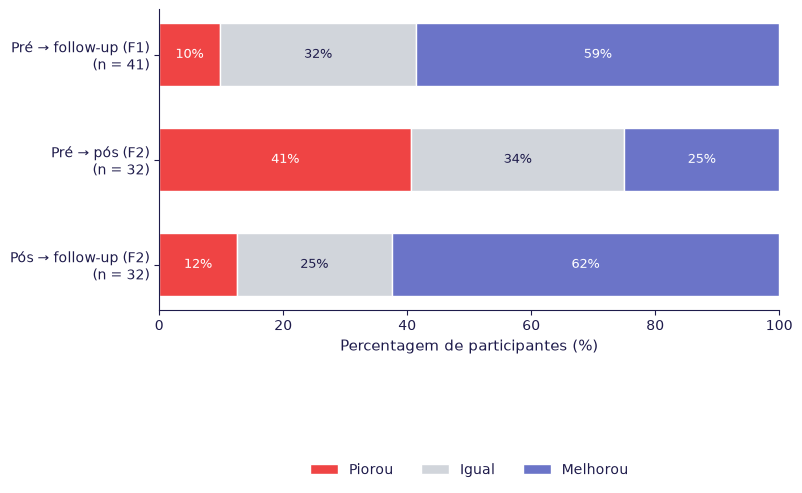

In [78]:
figura_mip({
    "Pré → follow-up (F1)": pd.DataFrame({"conhecimento_pre": F1["conhecimento_pre"],
                                          "conhecimento_pos": F1["conhecimento_follow"]}),
    "Pré → pós (F2)": F2[["conhecimento_pre", "conhecimento_pos"]],
    "Pós → follow-up (F2)": pd.DataFrame({"conhecimento_pre": F2["conhecimento_pos"],
                                          "conhecimento_pos": F2["conhecimento_follow"]}),
}, "8_mip_followup.png")


**Pré vs follow-up (F1, n = 41).** O desempenho no follow-up foi superior ao do pré (Mdn = 2 → 3; Wilcoxon, Z = 3,82, p < ,001, p BH < ,001, r_rb = ,75). Vinte e quatro participantes (58,5%) melhoraram, 13 mantiveram-se e 4 pioraram. A diferença média foi de 0,85 exercícios (IC 95% [0,49; 1,22]). O IC da mediana das diferenças ([0; 1]) não é informativo nesta escala discreta (F4). Excluindo os 2 participantes sinalizados por colaboração no follow-up (F13, n = 39), o resultado foi o mesmo (Z = 3,61, p < ,001, r_rb = ,73; diferença média = 0,85 [0,46; 1,23]).

**Por exercício (McNemar exato, F1):**
- **ex1:** o acerto não mudou significativamente (78,0% → 87,8%; b = 2, c = 6; p = ,289, p BH = ,365). Partia de um nível já elevado.
- **ex2:** o acerto subiu (61,0% → 85,4%; b = 2, c = 12; p = ,013, p BH = ,029).
- **ex3:** o acerto subiu muito (39,0% → 90,2%; b = 2, c = 23; p < ,001, p BH < ,001).

**Pós vs follow-up (F2, n = 32).** O desempenho no follow-up foi superior ao do pós (Mdn = 1 → 3; Z = 3,65, p < ,001, p BH < ,001, r_rb = ,78; 20 melhoraram, 8 mantiveram-se, 4 pioraram; diferença média = 1,22 [0,72; 1,72]). Sem os participantes que não resolveram nenhum exercício no pós (F3, n = 28), a subida manteve-se (Mdn = 2 → 3; Z = 3,04, p = ,002, r_rb = ,71; diferença média = 0,96 [0,46; 1,46]). A subida pós → follow-up não se explica, portanto, só pela não resolução no fim da sessão.

**Métodos de resolução (Q de Cochran, F2, participantes com método válido nos três momentos).** A proporção que usou a fórmula não mudou entre os momentos em nenhum exercício:
- **ex1** (n = 29): 86,2% → 82,8% → 96,6%; Q(2) = 4,33, p = ,115, p BH = ,206;
- **ex2** (n = 25): 80,0% → 80,0% → 92,0%; Q(2) = 2,25, p = ,325, p BH = ,365;
- **ex3** (n = 22): 31,8% → 50,0% → 36,4%; Q(2) = 2,00, p = ,368, p BH = ,368.

No ex1 e no ex2 a fórmula foi dominante desde o pré. No ex3, a subida da fórmula no pós não se manteve no follow-up, em que predominou a resolução por etapas (secção 8.1). Os dados não sustentam que a dependência da fórmula observada no piloto persista três semanas depois.

**Estudo ativo (F1).** A mudança pré → follow-up não diferiu entre quem praticou depois da aula (n = 27; Mdn = 1) e quem não praticou (n = 14; Mdn = 0,5) (U = 149,0, Z = 1,14, p = ,255, p BH = ,365, r_rb = ,21). Com 14 participantes no grupo que não praticou, a potência é baixa.

**Leitura conjunta.** A melhoria entre o pré e o follow-up é consistente, de magnitude moderada a grande, e robusta às sensibilidades pré-especificadas. Concentra-se no ex3 e no ex2. Não é atribuível ao DILU-IA isoladamente, por cinco razões:
1. O follow-up mede o percurso completo: sessão DILU-IA, aula laboratorial formal e um trabalho curricular de aplicação de diluições (curva de calibração de Bradford) que decorreu durante todo o intervalo.
2. Foi respondido em casa, sem limite de tempo nem supervisão.
3. Os sets não são aritmeticamente equivalentes: no follow-up, o ex3 usa fator 1:10 (F7) e o ex2 tem um rácio de concentrações exato (4), ao contrário do pré (4,17).
4. Os participantes do follow-up são autosselecionados (37% dos elegíveis), com o turno 2 sobre-representado e regulação externa mais baixa no pré (secção 1.4).
5. Não há grupo de controlo.

A subida entre o pós e o follow-up, mesmo sem os participantes que não resolveram o pós, mostra que o desempenho medido no fim da sessão subestimou o que os participantes eram capazes de fazer pouco depois, num contexto sem pressão de tempo.

*Nota: família 3 com m = 9 e correção de Benjamini-Hochberg (F12). As sensibilidades F3 e F13 ficam fora da família. Os McNemar par a par dos métodos são descritivos (tabela `8_familia3_metodos_pares_descritivo.xlsx`).*

## 9. Correlações exploratorias

In [79]:
def ic_spearman(r, n, k=0):
    """IC 95% de Bonett & Wright (2000) para Spearman; k = n.º de covariáveis."""
    se = np.sqrt((1 + r ** 2 / 2) / (n - 3 - k))
    return np.tanh(np.arctanh(r) + np.array([-1, 1]) * 1.96 * se)

def spearman_spss(x, y, titulo):
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    n = len(d)
    r, p = stats.spearmanr(d["x"], d["y"])
    ic = ic_spearman(r, n)
    print(f"\n{'=' * 64}\n  {titulo}\n{'=' * 64}")
    print(f"  n = {n}   Spearman's rho = {r:.3f}   IC 95% [{ic[0]:.3f}; {ic[1]:.3f}]   Sig. (2-tailed) = {p:.4f}")
    return {"teste": titulo, "tipo": "Spearman", "n": n, "rho": r, "ic_inf": ic[0], "ic_sup": ic[1], "p": p}

def spearman_parcial_spss(x, y, z, titulo):
    """Correlação parcial de Spearman: correlação entre os resíduos das ordens de x e de y,
    depois de retirar o efeito linear das ordens de z. gl = n − 3."""
    d = pd.DataFrame({"x": x, "y": y, "z": z}).dropna()
    n = len(d)
    rk = d.rank()
    res_x = rk["x"] - np.polyval(np.polyfit(rk["z"], rk["x"], 1), rk["z"])
    res_y = rk["y"] - np.polyval(np.polyfit(rk["z"], rk["y"], 1), rk["z"])
    r = np.corrcoef(res_x, res_y)[0, 1]
    gl = n - 3
    t = r * np.sqrt(gl / (1 - r ** 2))
    p = 2 * stats.t.sf(abs(t), gl)
    r_pg = float(pg.partial_corr(data=d, x="x", y="y", covar="z", method="spearman")["r"].iloc[0])
    assert np.isclose(r, r_pg), f"rho parcial diferente do pingouin ({r:.4f} vs {r_pg:.4f})"
    ic = ic_spearman(r, n, k=1)
    print(f"\n{'=' * 64}\n  {titulo}\n{'=' * 64}")
    print(f"  n = {n}   rho parcial = {r:.3f}   IC 95% [{ic[0]:.3f}; {ic[1]:.3f}]   df = {gl}   Sig. (2-tailed) = {p:.4f}")
    return {"teste": titulo, "tipo": "Spearman parcial", "n": n, "rho": r, "ic_inf": ic[0], "ic_sup": ic[1], "p": p}

In [80]:
res_f4 = []

# H2: conhecimento no pré vs afeto e amotivação no pré (todos com pré)
h2 = larga[larga["tem_pre"] == 1]
for var, rot, direcao in [("AP_pre", "Afeto positivo (pré)", "positiva"),
                          ("AN_pre", "Afeto negativo (pré)", "negativa"),
                          ("desmotivacao_pre", "Amotivação (pré)", "negativa")]:
    r_ = spearman_spss(h2["conhecimento_pre"], h2[var], f"H2: conhecimento (pré) ↔ {rot}")
    res_f4.append({**r_, "relacao": f"Conhecimento (pré) ↔ {rot}", "direcao_esperada": direcao})

# SUS ↔ conhecimento no pós, controlando o pré (pares pré–pós)
prim = larga[larga["par_pre_pos"] == 1]
r_ = spearman_parcial_spss(prim["SUS"], prim["conhecimento_pos"], prim["conhecimento_pre"],
                           "SUS ↔ conhecimento (pós), controlando o pré")
res_f4.append({**r_, "relacao": "SUS ↔ conhecimento (pós) | pré", "direcao_esperada": "positiva"})


  H2: conhecimento (pré) ↔ Afeto positivo (pré)
  n = 113   Spearman's rho = 0.010   IC 95% [-0.175; 0.194]   Sig. (2-tailed) = 0.9188

  H2: conhecimento (pré) ↔ Afeto negativo (pré)
  n = 113   Spearman's rho = -0.077   IC 95% [-0.258; 0.110]   Sig. (2-tailed) = 0.4172

  H2: conhecimento (pré) ↔ Amotivação (pré)
  n = 109   Spearman's rho = -0.034   IC 95% [-0.220; 0.155]   Sig. (2-tailed) = 0.7276

  SUS ↔ conhecimento (pós), controlando o pré
  n = 87   rho parcial = -0.027   IC 95% [-0.238; 0.186]   df = 84   Sig. (2-tailed) = 0.8019


In [81]:
fam4 = pd.DataFrame(res_f4)
fam4["p_BH"] = multipletests(fam4["p"], method="fdr_bh")[1]
fam4["concordante"] = np.where(fam4["direcao_esperada"] == "positiva", fam4["rho"] > 0, fam4["rho"] < 0)

tabela_fam4 = pd.DataFrame({
    "Relação": fam4["relacao"], "n": fam4["n"],
    "ρ [IC 95%]": [f"{fmt(r, 2, False)} [{fmt(i, 2, False)}; {fmt(s, 2, False)}]"
                   for r, i, s in zip(fam4["rho"], fam4["ic_inf"], fam4["ic_sup"])],
    "p": fam4["p"].apply(fmt_p), "p (BH)": fam4["p_BH"].apply(fmt_p),
    "Direção esperada": fam4["direcao_esperada"],
    "Na direção esperada": fam4["concordante"].map({True: "sim", False: "não"}),
})
tabela_fam4 = tabela_fam4.drop(columns="Na direção esperada")
print(tabela_fam4.to_string(index=False))
tabela_fam4.to_excel(OUT_TAB / "9_familia4_apa.xlsx", index=False)

                                  Relação   n       ρ [IC 95%]    p p (BH) Direção esperada
Conhecimento (pré) ↔ Afeto positivo (pré) 113  ,01 [-,18; ,19] ,919   ,919         positiva
Conhecimento (pré) ↔ Afeto negativo (pré) 113 -,08 [-,26; ,11] ,417   ,919         negativa
    Conhecimento (pré) ↔ Amotivação (pré) 109 -,03 [-,22; ,16] ,728   ,919         negativa
           SUS ↔ conhecimento (pós) | pré  87 -,03 [-,24; ,19] ,802   ,919         positiva


In [82]:
# F8: SUS ↔ conhecimento no pós | pré, só quem terminou o jogo
s1 = prim[prim["game_finished"] == 1]
r_f8 = spearman_parcial_spss(s1["SUS"], s1["conhecimento_pos"], s1["conhecimento_pre"],
                             "F8 (sensibilidade): SUS ↔ conhecimento (pós) | pré, completaram o jogo")

# H1 (descritivo, Oldham): quem parte mais baixo ganha mais?
# Correlaciona o ganho com a média de pré e pós, e não com o pré, para evitar a regressão para a média
oldham_media = (prim["conhecimento_pre"] + prim["conhecimento_pos"]) / 2
r_h1 = spearman_spss(oldham_media, prim["delta_conhecimento"],
                     "H1 (descritivo, Oldham): média pré/pós ↔ mudança pós − pré")

pd.DataFrame([r_f8, r_h1]).to_excel(OUT_TAB / "9_familia4_sensibilidade_e_H1.xlsx", index=False)


  F8 (sensibilidade): SUS ↔ conhecimento (pós) | pré, completaram o jogo
  n = 32   rho parcial = 0.071   IC 95% [-0.291; 0.415]   df = 29   Sig. (2-tailed) = 0.7044

  H1 (descritivo, Oldham): média pré/pós ↔ mudança pós − pré
  n = 87   Spearman's rho = 0.193   IC 95% [-0.020; 0.390]   Sig. (2-tailed) = 0.0726


### 9.1. Resultados (correlações exploratórias)

**H2: conhecimento no pré, afeto e amotivação no pré (n = 109–113).** O número de exercícios certos no pré não se associou ao afeto positivo (ρ = ,01, IC 95% [−,18; ,19]), ao afeto negativo (ρ = −,08 [−,26; ,11]) nem à amotivação (ρ = −,03 [−,22; ,16]); todos com p BH = ,919. Os intervalos excluem associações moderadas. A PANAS-VRP foi preenchida logo depois dos exercícios, mas os participantes não sabiam se tinham acertado. O afeto reportado pode, por isso, refletir a perceção do próprio desempenho, mas não o desempenho real. A hipótese H2 não se confirmou.

**SUS e conhecimento no pós, controlando o pré (n = 87).** A usabilidade percebida não se associou ao desempenho no pós (ρ parcial = −,03, IC 95% [−,24; ,19], p = ,802, p BH = ,919). O resultado foi o mesmo só com quem completou o jogo (F8, n = 32: ρ parcial = ,07 [−,29; ,42], p = ,704). A avaliação da usabilidade não acompanhou o desempenho no teste, o que é coerente com a SUS ter refletido sobretudo as condições de uso (dispositivos móveis, falhas de acesso ao LabPartner; secção 10).

**H1 (descritivo, método de Oldham, n = 87).** A associação entre a mudança pós − pré e a média do pré e do pós foi fraca e não significativa (ρ = ,19 [−,02; ,39], p = ,073). O sinal positivo não indica que quem partiu de mais baixo tenha ganho mais. Além disso, é inflacionado pelos participantes que não resolveram o pós, que têm ao mesmo tempo uma média baixa e uma mudança negativa. Com o efeito de teto, esta análise não permite responder à pergunta "quem parte mais baixo ganha mais?".

*Nota: família 4 com m = 4 e correção de Benjamini-Hochberg. A sensibilidade F8 e a H1 ficam fora da família. As variáveis do LabPartner e do conforto com IA são descritivas (secção 11).*

## 10. Analise da Usabilidade

### 10.1. Analise do SUS

In [83]:
sus = participantes[participantes["tem_pos"] == 1].copy()
print("Responderam ao pós:", len(sus), "| com SUS calculada:", sus["SUS"].notna().sum())
 
REFERENCIA_SUS = 68      # média de referência da literatura (Sauro & Lewis)
# Classificação usada no piloto (para comparar os dois estudos).
# CONFIRMAR os limites na referência que citas (Bangor, Kortum & Miller, 2009).
def classificar_sus(x):
    if pd.isna(x):
        return np.nan
    return ("Excelente" if x >= 85 else "Bom" if x >= 71 else
            "Aceitável" if x >= 51 else "Problemático")
 
sus["SUS_classe"] = sus["SUS"].apply(classificar_sus)
 

Responderam ao pós: 89 | com SUS calculada: 89


In [84]:
# Descritivos globais ----------------------------------------
s = sus["SUS"].dropna()
descr_sus = pd.Series({
    "n": len(s),
    "M (DP)": m_dp(s, 1),
    "Mdn [Q1; Q3]": mdn_iiq(s, 1),
    "Mínimo–Máximo": f"{fmt(s.min(), 1)}–{fmt(s.max(), 1)}",
    f"Acima de {REFERENCIA_SUS}, n (%)": f"{(s > REFERENCIA_SUS).sum()} ({fmt(100 * (s > REFERENCIA_SUS).mean(), 1)})",
})
print(descr_sus.to_string())
 
ORDEM_CLASSES = ["Excelente", "Bom", "Aceitável", "Problemático"]
classes = sus["SUS_classe"].value_counts().reindex(ORDEM_CLASSES, fill_value=0)
tabela_classes = pd.DataFrame({"n": classes,
                               "%": (100 * classes / classes.sum()).apply(lambda x: fmt(x, 1))})
print(tabela_classes.to_string())
 
# Comparação com o piloto, só descritiva (valores do notebook do piloto, n = 29)
print("\nPiloto: M = 90,3 (DP = 10,7); Mdn = 92,5 (IIQ = 11,2)")
 

n                                    89
M (DP)                      69,9 (16,9)
Mdn [Q1; Q3]          72,5 [55,0; 82,5]
Mínimo–Máximo                32,5–100,0
Acima de 68, n (%)            51 (57,3)
               n     %
SUS_classe            
Excelente     21  23,6
Bom           24  27,0
Aceitável     22  24,7
Problemático  22  24,7

Piloto: M = 90,3 (DP = 10,7); Mdn = 92,5 (IIQ = 11,2)


In [85]:
# SUS por subgrupo (descritivo, sem testes) ------------------
def linha_sus(dados, rotulo):
    x = dados["SUS"].dropna()
    return {"Grupo": rotulo, "n": len(x), "Mdn [IIQ]": mdn_iiq(x, 1), "M (DP)": m_dp(x, 1),
            f"> {REFERENCIA_SUS}, n (%)": f"{(x > REFERENCIA_SUS).sum()} ({fmt(100 * (x > REFERENCIA_SUS).mean(), 1)})"
            if len(x) else "—"}
 
linhas = [linha_sus(sus, "Todos")]
for t in sorted(sus["turno"].dropna().unique()):
    linhas.append(linha_sus(sus[sus["turno"] == t], f"Turno {int(t)}"))
for v, rot in [(1, "Completou o jogo"), (0, "Não completou o jogo")]:
    linhas.append(linha_sus(sus[sus["game_finished"] == v], rot))
linhas.append(linha_sus(sus[sus["game_finished"].isna()], "Sem dados de jogo"))
for v, rot in [(1, "Reportou falha técnica do LabPartner"), (0, "Não reportou falha técnica")]:
    linhas.append(linha_sus(sus[sus["lp_problema_tecnico"] == v], rot))
 
tabela_sus_grupos = pd.DataFrame(linhas)
print(tabela_sus_grupos.to_string(index=False))
tabela_sus_grupos.to_excel(OUT_TAB / "10_sus_por_grupo.xlsx", index=False)

                               Grupo  n         Mdn [IIQ]      M (DP) > 68, n (%)
                               Todos 89 72,5 [55,0; 82,5] 69,9 (16,9)   51 (57,3)
                             Turno 1 31 62,5 [50,0; 83,8] 67,9 (17,4)   14 (45,2)
                             Turno 2 28 72,5 [57,5; 82,5] 71,0 (15,8)   18 (64,3)
                             Turno 3 30 75,0 [58,1; 82,5] 71,0 (17,8)   19 (63,3)
                    Completou o jogo 33 75,0 [57,5; 85,0] 71,5 (18,0)   20 (60,6)
                Não completou o jogo 32 71,2 [60,0; 80,6] 70,5 (14,9)   18 (56,2)
                   Sem dados de jogo 24 70,0 [50,0; 83,1] 66,9 (18,2)   13 (54,2)
Reportou falha técnica do LabPartner  7 65,0 [58,8; 71,2] 64,3 (10,2)    3 (42,9)
          Não reportou falha técnica 82 72,5 [51,2; 84,4] 70,4 (17,3)   48 (58,5)


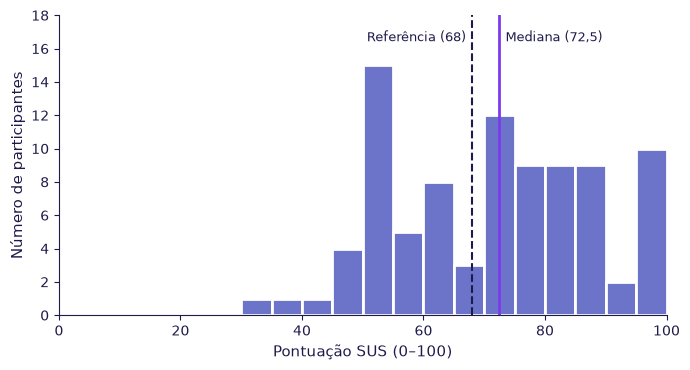

                                       Item Mdn (0–4) Favorável (3–4), % Desfavorável (0–1), %
     1. Gostaria de utilizar com frequência       2,0               44,9                  18,0
  2. Mais complexo do que necessário (inv.)       3,0               59,6                   7,9
                       3. Fácil de utilizar       3,0               64,0                  13,5
4. Precisaria de ajuda de um técnico (inv.)       3,0               67,4                   7,9
          5. Funcionalidades bem integradas       3,0               61,8                   7,9
       6. Demasiadas inconsistências (inv.)       3,0               68,5                   4,5
        7. A maioria aprenderia rapidamente       3,0               68,5                   7,9
     8. Muito complicado de utilizar (inv.)       3,0               68,5                   5,6
                      9. Senti-me confiante       2,0               47,2                  12,4
    10. Tive de aprender muito antes (inv.)       

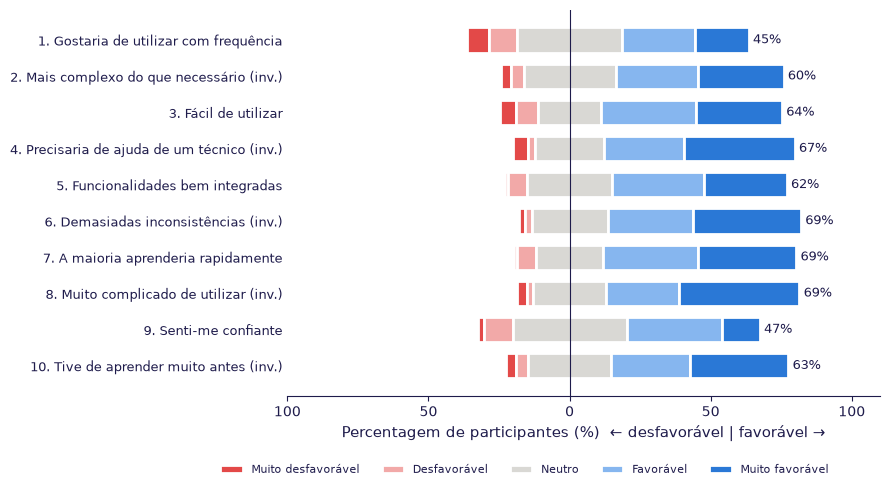

In [86]:
# Figura: distribuição da SUS --------------------------------
fig, ax = plt.subplots(figsize=(7, 3.8))
contagens, _, _ = ax.hist(s, bins=np.arange(0, 102.5, 5), color=DILU_BLUE, edgecolor="white", linewidth=2)
ax.set_ylim(0, contagens.max() * 1.2)          # espaço por cima das barras para os rótulos
ax.axvline(REFERENCIA_SUS, color=DILU_TEXT, linestyle="--", linewidth=1.5)
ax.text(REFERENCIA_SUS - 1, ax.get_ylim()[1] * 0.95, f"Referência ({REFERENCIA_SUS})",
        ha="right", va="top", fontsize=9)
ax.axvline(s.median(), color=DILU_PURPLE, linewidth=2)
ax.text(s.median() + 1, ax.get_ylim()[1] * 0.95, f"Mediana ({fmt(s.median(), 1)})",
        ha="left", va="top", fontsize=9, color=DILU_TEXT)
ax.set_xlim(0, 100)
ax.set_xlabel("Pontuação SUS (0–100)")
ax.set_ylabel("Número de participantes")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.savefig(OUT_FIG / "10_sus_distribuicao.png", bbox_inches="tight")
plt.show()
 
# %% 10.5 Itens da SUS: respostas no sentido favorável ---------------
# Cada item é convertido para a "contribuição" da fórmula (0–4), em que 4 é sempre
# a resposta mais favorável à usabilidade: ímpares = resposta − 1; pares = 5 − resposta.
# Assim, os itens negativos (pares) ficam na mesma direção dos positivos.
ITENS_SUS = {
    1: "Gostaria de utilizar com frequência",
    2: "Mais complexo do que necessário",
    3: "Fácil de utilizar",
    4: "Precisaria de ajuda de um técnico",
    5: "Funcionalidades bem integradas",
    6: "Demasiadas inconsistências",
    7: "A maioria aprenderia rapidamente",
    8: "Muito complicado de utilizar",
    9: "Senti-me confiante",
    10: "Tive de aprender muito antes",
}
favor = pd.DataFrame({i: (sus[f"sus{i}"] - 1) if i % 2 == 1 else (5 - sus[f"sus{i}"])
                      for i in ITENS_SUS})
 
itens_tab = pd.DataFrame({
    "Item": [f"{i}. {ITENS_SUS[i]}" + (" (inv.)" if i % 2 == 0 else "") for i in ITENS_SUS],
    "Mdn (0–4)": [fmt(favor[i].median(), 1) for i in ITENS_SUS],
    "Favorável (3–4), %": [fmt(100 * (favor[i] >= 3).mean(), 1) for i in ITENS_SUS],
    "Desfavorável (0–1), %": [fmt(100 * (favor[i] <= 1).mean(), 1) for i in ITENS_SUS],
})
print(itens_tab.to_string(index=False))
itens_tab.to_excel(OUT_TAB / "10_sus_itens.xlsx", index=False)
 
# %% 10.6 Figura: barras divergentes por item -----------------------
# Desfavorável à esquerda (vermelho), neutro ao centro (cinzento), favorável à direita (azul).
CORES_LIKERT = {0: "#e34948", 1: "#f2a9a8", 2: "#d9d8d4", 3: "#86b6ef", 4: "#2a78d6"}
ROTULOS_LIKERT = {0: "Muito desfavorável", 1: "Desfavorável", 2: "Neutro",
                  3: "Favorável", 4: "Muito favorável"}
 
pct = pd.DataFrame({i: favor[i].value_counts(normalize=True).reindex(range(5), fill_value=0) * 100
                    for i in ITENS_SUS}).T          # linhas = itens, colunas = 0–4
 
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(pct))
inicio = -(pct[0] + pct[1] + pct[2] / 2)            # o centro do "neutro" fica no zero
esquerda = inicio.to_numpy().copy()
for nivel in range(5):
    valores = pct[nivel].to_numpy()
    ax.barh(y, valores, left=esquerda, color=CORES_LIKERT[nivel], edgecolor="white",
            linewidth=2, height=0.7, label=ROTULOS_LIKERT[nivel])
    esquerda += valores
fav = (pct[3] + pct[4]).to_numpy()
for yi, v, fim in zip(y, fav, esquerda):
    ax.text(fim + 1.5, yi, f"{fmt(v, 0)}%", va="center", fontsize=9)   # % favorável no fim da barra
 
ax.axvline(0, color=DILU_TEXT, linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels([f"{i}. {ITENS_SUS[i]}" + (" (inv.)" if i % 2 == 0 else "") for i in ITENS_SUS],
                   fontsize=9)
ax.invert_yaxis()
ax.set_xlim(-100, 110)
ax.set_xticks([-100, -50, 0, 50, 100])
ax.set_xticklabels(["100", "50", "0", "50", "100"])
ax.set_xlabel("Percentagem de participantes (%)  ← desfavorável | favorável →")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.4, -0.15), fontsize=8)
plt.tight_layout()
plt.savefig(OUT_FIG / "10_sus_itens.png", bbox_inches="tight")
plt.show()
 

In [87]:
itens_sus = [f"sus{i}" for i in range(1, 11)]
constantes = sus[itens_sus].nunique(axis=1) == 1
print("Respostas iguais nos 10 itens:", constantes.sum())
print(sus.loc[constantes, itens_sus[0]].value_counts())     # qual o valor repetido
print("SUS exatamente 50:", (sus["SUS"] == 50).sum())

Respostas iguais nos 10 itens: 14
sus1
3.0    11
5.0     2
4.0     1
Name: count, dtype: int64
SUS exatamente 50: 15


In [88]:
s_sem_constantes = sus.loc[~constantes, "SUS"].dropna()
print("Sem respostas constantes (post hoc, descritivo):",
      len(s_sem_constantes), mdn_iiq(s_sem_constantes, 1), m_dp(s_sem_constantes, 1))

Sem respostas constantes (post hoc, descritivo): 75 75,0 [62,5; 85,0] 73,6 (15,9)


#### 10.1.1. Resultados analise do SUS

A usabilidade do jogo, avaliada no pós por 89 participantes, ficou próxima da média
de referência (M = 69,9, DP = 16,9; Mdn = 72,5, IIQ 55,0–82,5; 57,3% acima de 68),
com grande dispersão: os participantes distribuíram-se de forma semelhante pelas
classes excelente (23,6%), boa (27,0%), aceitável (24,7%) e problemática (24,7%).
A SUS foi muito inferior à do piloto (M = 90,3), em que a participação foi voluntária e
o jogo foi usado em computador; nesta sessão, os participantes usaram telemóveis e
tablets, com dimensões das caixas alteradas e falhas de acesso ao LabPartner.

Catorze participantes (15,7%) deram a mesma resposta aos 10 itens — 11 sempre o ponto
neutro (3) e 3 sempre concordância (4 ou 5) —, o que produz uma pontuação de 50
independentemente da resposta escolhida e explica a concentração de pontuações nesse
valor (15 participantes com SUS = 50). A concordância com todos os itens, incluindo os
de sentido negativo, é incoerente e sugere que os itens não foram lidos. Este padrão,
no final de uma sessão longa, indica que parte das respostas foi pouco discriminativa;
os participantes não foram excluídos.

Ao nível dos itens, os aspetos de facilidade de utilização, complexidade e
consistência foram avaliados favoravelmente por 60–69% dos participantes. Os itens
menos favoráveis foram a vontade de utilizar o jogo com frequência (item 1: 44,9%
favorável) e a confiança na sua utilização (item 9: 47,2%). O primeiro pode refletir
a natureza pontual da atividade e a preferência de muitos participantes por resolver
sozinhos; o segundo é consistente com as dificuldades observadas nos exercícios.

Descritivamente, a SUS foi mais baixa no turno 1 (Mdn = 62,5; 45,2% acima de 68) do
que nos turnos 2 (72,5) e 3 (75,0), e entre os 7 participantes que reportaram falhas
técnicas do LabPartner (Mdn = 65,0). O turno 2, com o pior desempenho no pós, não
teve a SUS mais baixa, o que sugere que a avaliação da usabilidade não refletiu
apenas a experiência com o teste. Estas comparações são descritivas e não foram
testadas.

Nota: classificação segundo os limites usados no piloto (≥ 85 excelente, ≥ 71 boa,
≥ 51 aceitável) [confirmar na referência citada].

## 11. Labpartner

### 11.1. Jogo e cliques no LabPartner (pós, n = 89)

In [89]:
pos_p = participantes[participantes["tem_pos"] == 1].copy()

def linha(rot, valor):
    return {"Variável": rot, "Valor": valor}

sem_clique = (pos_p["lp_total"] == 0).astype(float).where(pos_p["lp_total"].notna())
linhas = [
    linha("Com dados de jogo, n (%)", n_pct(pos_p["final_level"].notna().astype(float), 1)),
    linha("Terminou o jogo, n (%)", n_pct(pos_p["game_finished"], 1)),
    *[linha(f"   Nível final {k}, n (%)", n_pct(pos_p["final_level"], k)) for k in [1, 2, 3]],
    linha("Tempo de jogo da última tentativa (min), Mdn [Q1; Q3]", mdn_iiq(pos_p["game_time_min"], 1)),
    linha("Provável recarga (< 5 min), n (%)", n_pct(pos_p["provavel_recarga"], 1)),
    linha("Cliques no LabPartner (0–9), Mdn [Q1; Q3]", mdn_iiq(pos_p["lp_total"], 0)),
    linha("Nenhum clique, n (%)", n_pct(sem_clique, 1)),
    linha("% de exercícios disponíveis com clique, Mdn [Q1; Q3]", mdn_iiq(pos_p["lp_pct"], 0)),
]
tab_jogo = pd.DataFrame(linhas)
print(tab_jogo.to_string(index=False))
tab_jogo.to_excel(OUT_TAB / "11_jogo_cliques.xlsx", index=False)

                                             Variável             Valor
                             Com dados de jogo, n (%)         65 (73,0)
                               Terminou o jogo, n (%)         33 (50,8)
                                 Nível final 1, n (%)           5 (7,7)
                                 Nível final 2, n (%)         16 (24,6)
                                 Nível final 3, n (%)         44 (67,7)
Tempo de jogo da última tentativa (min), Mdn [Q1; Q3] 32,2 [19,6; 35,9]
                    Provável recarga (< 5 min), n (%)           3 (4,8)
            Cliques no LabPartner (0–9), Mdn [Q1; Q3]          2 [1; 2]
                                 Nenhum clique, n (%)         12 (19,7)
 % de exercícios disponíveis com clique, Mdn [Q1; Q3]       22 [11; 33]


### 11.2. Funcionamento do LabPartner reportado no pós

In [90]:
resp_lp = pos_p[pos_p["labpartner_function"].notna()]
print("Responderam à pergunta:", len(resp_lp), "de", len(pos_p))
linhas = [linha(rot, n_pct(resp_lp[col], 1)) for col, rot in [
    ("lp_funcionou_bem", "Funcionou bem"),
    ("lp_confuso", "Respostas confusas ou contraditórias"),
    ("lp_deu_codigo", "Deu o código antes de resolver"),
    ("lp_fez_calculos", "Fez cálculos sem o aluno explicar"),
    ("lp_problema", "Pelo menos um problema pedagógico"),
    ("lp_problema_tecnico", "Outro: não funcionou / lento"),
    ("lp_nao_usou", "Outro: não usou"),
]]
tab_lp_pos = pd.DataFrame(linhas)
print(tab_lp_pos.to_string(index=False))
tab_lp_pos.to_excel(OUT_TAB / "11_labpartner_pos.xlsx", index=False)

Responderam à pergunta: 89 de 89
                            Variável     Valor
                       Funcionou bem 66 (74,2)
Respostas confusas ou contraditórias   7 (7,9)
      Deu o código antes de resolver   1 (1,1)
   Fez cálculos sem o aluno explicar   1 (1,1)
   Pelo menos um problema pedagógico  9 (10,1)
        Outro: não funcionou / lento   7 (7,9)
                     Outro: não usou   8 (9,0)


### 11.3. Acesso, motivos e dispositivo (follow-up, n = 44)

In [91]:
ACESSO_CURTO = {
    "Sim, acedi e usei-o": "Acedeu e usou",
    "Sim, acedi, mas quase não o usei": "Acedeu, quase não usou",
    "Tentei, mas não consegui aceder (por exemplo, problema de login)": "Tentou, sem acesso",
    "Não tentei aceder": "Não tentou",
    "Não me lembro": "Não se lembra",
}
fu["acesso_cat"] = fu["ai_use_raw"].str.strip().map(ACESSO_CURTO)
print(fu["acesso_cat"].value_counts().reindex(ACESSO_CURTO.values(), fill_value=0)
      .to_frame("n").assign(pct=lambda t: (100 * t["n"] / t["n"].sum()).round(1)))

# Motivos: denominador = quem podia responder (não "acedeu e usou")
elegiveis = fu[fu["acesso_cat"] != "Acedeu e usou"]
responderam = elegiveis[elegiveis["reason_not_ai_use"].notna()]
print(f"\nMotivos: responderam {len(responderam)} de {len(elegiveis)} que podiam responder")
for col, rot in [("motivo_ajuda_humana", "Preferiu pedir ajuda aos docentes ou a colegas"),
                 ("motivo_sozinho", "Achou que conseguia resolver sozinho/a"),
                 ("motivo_sem_acesso", "Não conseguiu aceder"),
                 ("motivo_sem_tempo", "Não teve tempo"),
                 ("motivo_nao_percebi", "Não percebeu como funcionava"),
                 ("motivo_outro", "Outro (críticas ao estilo de resposta)")]:
    print(f"  {rot}: {n_pct(responderam[col], 1)}")

# Dispositivo principal × acesso (a falha de login dependia do dispositivo?)
def dispositivo(l):
    if l["tech_n"] > 1: return "Mais do que um"
    if l["tech_phone"] == 1: return "Telemóvel"
    if l["tech_tablet"] == 1: return "Tablet"
    if l["tech_computer"] == 1: return "Computador"
    return np.nan
fu["dispositivo"] = fu.apply(dispositivo, axis=1)
tab_disp = pd.crosstab(fu["dispositivo"], fu["acesso_cat"], margins=True, margins_name="Total")
print("\n", tab_disp.to_string())
tab_disp.to_excel(OUT_TAB / "11_dispositivo_acesso.xlsx")

                         n   pct
acesso_cat                      
Acedeu e usou           15  34.1
Acedeu, quase não usou   9  20.5
Tentou, sem acesso      13  29.5
Não tentou               4   9.1
Não se lembra            3   6.8

Motivos: responderam 13 de 29 que podiam responder
  Preferiu pedir ajuda aos docentes ou a colegas: 5 (38,5)
  Achou que conseguia resolver sozinho/a: 4 (30,8)
  Não conseguiu aceder: 1 (7,7)
  Não teve tempo: 1 (7,7)
  Não percebeu como funcionava: 0 (0,0)
  Outro (críticas ao estilo de resposta): 2 (15,4)

 acesso_cat      Acedeu e usou  Acedeu, quase não usou  Não se lembra  Não tentou  Tentou, sem acesso  Total
dispositivo                                                                                                
Computador                  4                       2              1           1                   2     10
Mais do que um              1                       1              1           1                   0      4
Tablet                  

### 11.4. Coerência entre o pós e o follow-up (quem tem os dois)

In [92]:
pf = larga[(larga["tem_pos"] == 1) & (larga["tem_follow"] == 1) & (larga["follow_nao_atribuivel"] == 0)].copy()
pf["acesso_cat"] = pf["ai_use_raw"].str.strip().map(ACESSO_CURTO)
pf["clicou"] = (pf["lp_total"] > 0).map({True: "≥ 1 clique", False: "0 cliques"})
print("n =", len(pf))
print(pd.crosstab(pf["acesso_cat"], pf["clicou"].fillna("sem dados de jogo"), margins=True).to_string())
print()
print(pd.crosstab(pf["acesso_cat"], pf["lp_outro_cat"].fillna("respondeu a uma opção / em branco"),
                  margins=True).to_string())

n = 32
clicou                  0 cliques  ≥ 1 clique  All
acesso_cat                                        
Acedeu e usou                   4           7   11
Acedeu, quase não usou          3           4    7
Não se lembra                   0           2    2
Não tentou                      2           2    4
Tentou, sem acesso              5           3    8
All                            14          18   32

lp_outro_cat            nao_usou  problema_tecnico  respondeu a uma opção / em branco  All
acesso_cat                                                                                
Acedeu e usou                  0                 0                                 11   11
Acedeu, quase não usou         0                 0                                  7    7
Não se lembra                  0                 0                                  2    2
Não tentou                     2                 0                                  2    4
Tentou, sem acesso             2      

### 11.5. Fidelidade (o LabPartner respeitou o desenho socrático?)

In [93]:
print(pd.crosstab(pos_p["lp_deu_codigo"], pos_p["game_finished"], margins=True,
                  rownames=["Deu o código"], colnames=["Terminou o jogo"]).to_string())
print("Deu o código:", int(pos_p["lp_deu_codigo"].sum()),
      "| Fez cálculos sem explicação:", int(pos_p["lp_fez_calculos"].sum()),
      "| Confuso:", int(pos_p["lp_confuso"].sum()))

Terminou o jogo  0.0  1.0  All
Deu o código                  
0.0               32   33   65
All               32   33   65
Deu o código: 1 | Fez cálculos sem explicação: 1 | Confuso: 7


### 11.6. Contraste “sem acesso por falha técnica” vs “com acesso” (descritivo)

In [94]:
grupos_acesso = {
    "Com acesso (usou ou quase não usou)": pf[pf["acesso_cat"].isin(["Acedeu e usou", "Acedeu, quase não usou"])],
    "Sem acesso (falha técnica)": pf[pf["acesso_cat"] == "Tentou, sem acesso"],
    "Não tentou": pf[pf["acesso_cat"] == "Não tentou"],
}
linhas = []
for rot, g in grupos_acesso.items():
    for nome, var in [("Pré → pós", "delta_conhecimento"), ("Pré → follow-up", "delta_pre_follow_conhecimento")]:
        d = g[var].dropna()
        linhas.append({"Grupo": rot, "Mudança": nome, "n": len(d),
                       "Mdn [Q1; Q3]": mdn_iiq(d, 1), "M (DP)": m_dp(d),
                       "Melhorou / Igual / Piorou": f"{(d > 0).sum()} / {(d == 0).sum()} / {(d < 0).sum()}"})
tab_contraste = pd.DataFrame(linhas)
print(tab_contraste.to_string(index=False))
tab_contraste.to_excel(OUT_TAB / "11_contraste_acesso.xlsx", index=False)

                              Grupo         Mudança  n     Mdn [Q1; Q3]       M (DP) Melhorou / Igual / Piorou
Com acesso (usou ou quase não usou)       Pré → pós 18  0,0 [-1,0; 0,0] -0,17 (1,04)                 4 / 8 / 6
Com acesso (usou ou quase não usou) Pré → follow-up 18   1,0 [0,2; 1,0]  0,83 (0,92)                13 / 3 / 2
         Sem acesso (falha técnica)       Pré → pós  8  0,0 [-2,0; 1,0] -0,38 (1,77)                 3 / 2 / 3
         Sem acesso (falha técnica) Pré → follow-up  8   0,5 [0,0; 1,5]  0,88 (1,46)                 4 / 3 / 1
                         Não tentou       Pré → pós  4 -0,5 [-1,5; 0,2] -0,75 (1,71)                 1 / 1 / 2
                         Não tentou Pré → follow-up  4   0,0 [0,0; 0,5]  0,50 (1,00)                 1 / 3 / 0


### 11.7. Resultados: uso do jogo e do LabPartner (descritivo)

**Jogo (pós, n = 89).** 65 participantes (73,0%) colaram os resultados do jogo. Destes, 33 (50,8%) terminaram o jogo e 44 (67,7%) chegaram ao nível 3. O tempo da última tentativa foi de 32,2 minutos (IIQ 19,6–35,9); 3 tiveram provavelmente uma recarga.

**Cliques no LabPartner.** A mediana foi de 2 cliques (IIQ 1–2) em 9 possíveis, o que corresponde a 22% dos exercícios disponíveis (IIQ 11–33). 19,7% não clicaram nenhuma vez. A métrica regista a abertura da janela, não o login nem a conversa (decisão 11).

**Funcionamento reportado no pós (n = 89).**
- 74,2% escolheram "funcionou bem (nada de estranho a reportar)".
- Problemas pedagógicos foram raros: respostas confusas 7,9%; o LabPartner deu o código antes da resolução em 1 caso e fez cálculos sem pedir o raciocínio noutro. A fidelidade ao desenho socrático foi, portanto, elevada entre quem o usou.
- No campo "outro", 7,9% referiram que não funcionou ou foi lento e 9,0% que não o usaram.

**Acesso reportado no follow-up (n = 44).** 34,1% acederam e usaram, 20,5% acederam mas quase não usaram, 29,5% tentaram sem conseguir aceder, 9,1% não tentaram e 6,8% não se lembravam. A falha de acesso dependeu do dispositivo:

| Dispositivo (só esse) | Sem acesso |
|---|---|
| Telemóvel | 8 de 13 (62%) |
| Tablet | 3 de 17 (18%) |
| Computador | 2 de 10 (20%) |

Dos 29 que não usaram ou quase não usaram, 13 indicaram um motivo. Os mais frequentes foram preferir pedir ajuda aos docentes ou a colegas (5) e achar que conseguiam resolver sozinhos (4). Dois criticaram o estilo de resposta: "não respondia às dúvidas de forma direta" e "dava pouca informação".

**Coerência entre fontes (n = 32 com pós e follow-up).** As três fontes sobre o uso do LabPartner são pouco concordantes:
- dos 8 que no follow-up reportaram falta de acesso, só 4 o assinalaram no pós; os restantes escolheram uma opção pré-definida, sobretudo "funcionou bem";
- 3 desses 8 têm cliques registados no jogo;
- 4 dos 11 que reportaram ter acedido e usado não têm nenhum clique.

A opção "nada de estranho a reportar" terá funcionado como resposta por defeito, e nem a métrica de cliques nem o autorrelato permitem estabelecer quem usou o LabPartner. Por isso, a análise do LabPartner é apenas descritiva.

**Contraste descritivo por acesso (n = 32).** A mudança no conhecimento foi semelhante:
- pré → pós: com acesso, M = −0,17 (n = 18); sem acesso por falha técnica, M = −0,38 (n = 8);
- pré → follow-up: com acesso, M = 0,83; sem acesso, M = 0,88.

Com estes n e com a co-intervenção curricular entre o pós e o follow-up, não é possível tirar conclusões sobre o efeito do acesso ao LabPartner.

## 12. Feedback aberto

### 12.1.Preparar para codificação manual

In [95]:
COMENTARIOS = {"general_comment": "Pós: geral", "positive_comment": "Pós: positivo",
               "negative_comment": "Pós: negativo", "follow_comment": "Follow-up"}
textos = []
for col, origem in COMENTARIOS.items():
    sub = participantes[["participant_id", col]].dropna()
    sub = sub[sub[col].astype(str).str.strip().str.len() > 2]          # remove "-", "." e vazios
    textos.append(sub.rename(columns={col: "texto"}).assign(origem=origem))
feedback = pd.concat(textos, ignore_index=True)

# Triagem (a confirmar à mão)
PALAVRAS = {
    "acesso_login": r"login|aceder|acesso|entrar|conta|copilot",
    "dispositivo_ecra": r"telem|tablet|ecr|caixa|tamanho|pequen",
    "tempo": r"tempo|rápid|demor|lent",
    "ia_labpartner": r"labpartner|lab partner|\bia\b|chatbot|tutor",
    "jogo_positivo": r"divert|interativ|gost|útil|ajud",
}
for tema, padrao in PALAVRAS.items():
    feedback[tema] = feedback["texto"].str.lower().str.contains(padrao, regex=True).astype(int)

print(feedback.groupby("origem").size())
print(feedback.groupby("origem")[list(PALAVRAS)].sum())
feedback.to_excel(OUT_TAB / "12_feedback_aberto_para_codificar.xlsx", index=False)

origem
Follow-up        40
Pós: geral       17
Pós: negativo    86
Pós: positivo    86
dtype: int64
               acesso_login  dispositivo_ecra  tempo  ia_labpartner  \
origem                                                                
Follow-up                 2                 3      1              9   
Pós: geral                0                 0      0              2   
Pós: negativo             6                 5     11             10   
Pós: positivo             0                 0      1              6   

               jogo_positivo  
origem                        
Follow-up                 14  
Pós: geral                 4  
Pós: negativo              2  
Pós: positivo             22  


### 12.2. Ajustes e extração dos temas principais

In [96]:
fb = pd.read_excel ( PASTA / "12_feedback_aberto_codificado.xlsx")
CODIGOS = list(fb.columns[3:])
fb[CODIGOS] = fb[CODIGOS].fillna(0).astype(int)      # há 1 célula vazia
print(fb.shape, "| comentários por origem:\n", fb["origem"].value_counts())

(229, 21) | comentários por origem:
 origem
Pós: positivo    86
Pós: negativo    86
Follow-up        40
Pós: geral       17
Name: count, dtype: int64


In [97]:
# (participante, origem): {coluna: valor, ...} — motivo
AJUSTES = {
    (70, "Pós: negativo"):  {"dificuldade_uso_ia": 0, "qualidade_pedagogica_ia": 1},  # crítica pedagógica, não de uso
    (71, "Follow-up"):      {"dificuldade_uso_ia": 0},                              # idem
    (5,  "Pós: positivo"):  {"qualidade_pedagogica_ia": 0},                         # elogio → já em ia_util
    (44, "Pós: positivo"):  {"qualidade_pedagogica_ia": 0, "ia_util": 1},           # elogio à IA
    (91, "Follow-up"):      {"dificuldade_clareza": 0, "dificuldade_uso_ia": 1},    # usabilidade do LabPartner
    (20, "Pós: negativo"):  {"sem_acesso": 0, "dificuldade_uso_ia": 0, "dificuldade_clareza": 0},  # o jogo não carregou no iPad
    (66, "Pós: negativo"):  {"dificuldade_clareza": 0, "dispositivo_ecra": 1},      # calculadora
    (78, "Pós: negativo"):  {"dificuldade_clareza": 0, "recursos_conteudo": 0, "dispositivo_ecra": 1}, # calculadora
    (97, "Pós: negativo"):  {"recursos_conteudo": 0, "dispositivo_ecra": 1},        # calculadora
    (86, "Pós: negativo"):  {"dificuldade_clareza": 0, "dispositivo_ecra": 1},      # confuso no telemóvel
    (39, "Pós: positivo"):  {"tempo_insuficiente_atividade_longa": 0},              # entusiasmo, não queixa
    (95, "Follow-up"):      {"dificuldade_clareza": 0},                             # "precisa de melhorias"
    (112, "Pós: negativo"): {"dificuldade_clareza": 0},                             # já em formato (papel)
}
for (pid, origem), valores in AJUSTES.items():
    linha = (fb["participant_id"] == pid) & (fb["origem"] == origem)
    assert linha.sum() == 1, f"Não encontrei {pid} em {origem}"
    for col, v in valores.items():
        fb.loc[linha, col] = v

In [98]:
TEMAS = {
    "Fácil de usar e interativo": ["facilidade_uso", "interatividade_ludico"],
    "Útil para rever e consolidar": ["aprendizagem"],
    "LabPartner valorizado por quem lhe acedeu": ["ia_util"],
    "Autonomia e feedback imediato": ["autonomia_feedback"],
    "Recursos visuais e de apoio": ["recursos_conteudo"],
    "Acesso e integração do LabPartner": ["sem_acesso", "dificuldade_uso_ia"],
    "LabPartner pouco informativo": ["qualidade_pedagogica_ia"],
    "Dificuldade ou clareza das tarefas": ["dificuldade_clareza"],
    "Falta de bases prévias": ["conhecimentos_previos_insuficientes"],
    "Tempo insuficiente": ["tempo_insuficiente_atividade_longa"],
    "Dispositivo e interface": ["dispositivo_ecra"],
    "Formato e mecânica do jogo": ["preferencia_outro_formato_papel", "mecanica_jogo"],
    "Instruções da atividade": ["instrucoes_atividade"],
    "Apreciação global positiva": ["Global_positivo"],
}
usadas = sum(TEMAS.values(), []) + ["Sem_conteudo_substantivo"]
assert sorted(usadas) == sorted(CODIGOS), "Há categorias sem tema (ou repetidas)"

for tema, cols in TEMAS.items():
    fb[tema] = fb[cols].max(axis=1)

In [99]:
CITACOES = {
    "Fácil de usar e interativo": [(39, "Pós: positivo")],
    "Apreciação global positiva": [(110, "Follow-up")],
    "Útil para rever e consolidar": [(89, "Pós: positivo")],
    "LabPartner valorizado por quem lhe acedeu": [(112, "Pós: positivo")],
    "Acesso e integração do LabPartner": [(39, "Pós: negativo"), (74, "Pós: negativo")],
    "Autonomia e feedback imediato": [(34, "Pós: positivo"), (72, "Pós: positivo")],
    "Dificuldade ou clareza das tarefas": [(109, "Pós: negativo")],      # «enunciados confusos»
    "Falta de bases prévias": [(133, "Pós: negativo"), (76, "Pós: negativo")],
    "Tempo insuficiente": [(5, "Pós: negativo")],
    "Dispositivo e interface": [(86, "Pós: negativo"), (146, "Pós: negativo")],
    "Formato e mecânica do jogo": [(78, "Follow-up"), (132, "Pós: negativo")],
    "Instruções da atividade": [(65, "Follow-up")],
    "Recursos visuais e de apoio": [(20, "Pós: positivo"), (35, "Pós: positivo")],
    "LabPartner pouco informativo": [(70, "Pós: negativo")],
}

def citar(pid, origem):
    t = fb.loc[(fb["participant_id"] == pid) & (fb["origem"] == origem), "texto"]
    assert len(t) == 1, f"Citação não encontrada: {pid}, {origem}"
    return f"«{str(t.iloc[0]).strip()}» ({origem.lower()})"

In [100]:
print("Participantes com pelo menos um comentário:", fb["participant_id"].nunique())
print("Participantes com pelo menos um comentário com conteúdo:",
      fb.loc[fb["Sem_conteudo_substantivo"] == 0, "participant_id"].nunique())

Participantes com pelo menos um comentário: 96
Participantes com pelo menos um comentário com conteúdo: 93


In [101]:
com_conteudo = fb.loc[fb["Sem_conteudo_substantivo"] == 0, "participant_id"].nunique()
linhas = []
for tema in TEMAS:
    sub = fb[fb[tema] == 1]
    n_part = sub["participant_id"].nunique()
    linhas.append({"Tema": tema,
                   "Comentários": len(sub),
                   "Participantes, n (%)": f"{n_part} ({fmt(100 * n_part / com_conteudo, 1)})",
                   "Citações ilustrativas": " / ".join(citar(*c) for c in CITACOES.get(tema, []))})
tabela_temas = (pd.DataFrame(linhas)
                .sort_values("Comentários", ascending=False, key=lambda s: s)  # por frequência
                .reset_index(drop=True))
print(f"Participantes com pelo menos um comentário com conteúdo: {com_conteudo} de {fb['participant_id'].nunique()}")
print(tabela_temas.to_string(index=False))
tabela_temas.to_excel(OUT_TAB / "12_feedback_sintese_temas.xlsx", index=False)

Participantes com pelo menos um comentário com conteúdo: 93 de 96
                                     Tema  Comentários Participantes, n (%)                                                                                                                                                                                 Citações ilustrativas
               Fácil de usar e interativo           49            47 (50,5)                                                                                           «Explicação util da IA, jogo interativo e interessante, apetece jogar mais e acabar o jogo» (pós: positivo)
               Apreciação global positiva           47            39 (41,9)                                                                                     «Gostei muito e achei que foi uma atividade interessante que nos mostrou como usar a IA para estudar» (follow-up)
             Útil para rever e consolidar           31            26 (28,0)                                     

### 12.3. Resultados

Foram analisados 229 comentários de 96 participantes:
- no pós, 17 comentários gerais, 86 sobre aspetos positivos e 86 sobre aspetos negativos;
- no follow-up, 40 comentários.

93 participantes deixaram pelo menos um comentário com conteúdo. Os comentários foram lidos e agrupados em temas pela investigadora para apoiar a interpretação dos resultados. Não se trata de uma análise qualitativa formal. Um comentário pode pertencer a mais do que um tema, e as percentagens referem-se aos 93 participantes com comentários com conteúdo.

**Aspetos valorizados.**
- O tema mais frequente foi a facilidade de uso e a interatividade do jogo (47 participantes, 50,5%): *«Explicação util da IA, jogo interativo e interessante, apetece jogar mais e acabar o jogo»*.
- 39 participantes (41,9%) deixaram uma apreciação global positiva.
- 26 (28,0%) valorizaram o jogo como forma de **rever e consolidar** matéria, mais do que de aprender conteúdos novos: *«Consegui rever conteúdos de química com facilidade»*.
- O LabPartner foi valorizado por 11 participantes (11,8%), sobretudo pela disponibilidade: *«não precisamos de estar à espera de um prof para tirar dúvidas»*. Outros 9 (9,7%) referiram a autonomia e o apoio disponível durante o jogo.
- 8 (8,6%) destacaram os recursos visuais e a pertinência das questões.

**Barreiras.**
- O tema negativo mais frequente foi o **acesso e a integração do LabPartner** (24 participantes, 25,8%). Inclui falhas técnicas (*«Não resulta a IA em tablets.»*) e obstáculos de desenho, como instalar uma aplicação, abrir uma conversa diferente em cada exercício ou sair do jogo para lhe aceder: *«Podia haver uma só IA (copilot) para todos os exercícios, senão tem de se adicionar sempre a cada exercício»*.
- 11 participantes (11,8%) referiram **dificuldade ou falta de clareza** das tarefas («enunciados confusos»), e 5 (5,4%) referiram explicitamente **falta de bases prévias**: «Mts dúvidas e conteúdo que nunca vi»; «Podiam ter feito uma pequena revisão teórica antes».
- 12 (12,9%) referiram **falta de tempo**: *«Despachei-me durante a aula e sinto que não aproveitei o jogo ao máximo»*.
- 10 (10,8%) referiram limitações do **dispositivo e da interface**: *«Confuso no telemóvel»*; *«Escrever os cálculos no ecrã»*.
- Houve críticas pontuais:
  - ao formato e à mecânica do jogo (5): *«É intuitivo mas acho que não é melhor forma de perceber / consolidar a matéria.»*; *«Não deixa avançar sem colocar a resposta correta»*;
  - à pouca utilidade das respostas do LabPartner (2, a que se juntam 2 motivos de não uso no follow-up);
  - às instruções da atividade (2).

**Convergência com os dados quantitativos.** Os temas negativos coincidem com os problemas observados nos dados quantitativos:
- falha de acesso ao LabPartner dependente do dispositivo (secção 11.1);
- falta de tempo e não resolução no pós, sobretudo no turno 2 (secção 4.3);
- participantes sem nenhum exercício certo no pré (16%; secção 2.2).

A valorização da facilidade de uso não se acompanhou de uma associação entre a SUS e o desempenho (secção 9). Os comentários sobre a qualidade pedagógica das respostas do LabPartner foram raros, o que é coerente com a elevada fidelidade ao desenho socrático entre quem lhe acedeu.

*Nota: codificação manual no Excel; ajustes de fronteira entre categorias, agrupamento em temas e contagens no notebook (dicionários `AJUSTES` e `TEMAS`); citações extraídas do ficheiro pelo código do participante.*

## 13. Logbook de alterações

### >> 11/10/2026

### Versões dos dados

| Versão | Pasta | Data | O que mudou | Verificação |
|---|---|---|---|---|
| v1 | `dados_limpos_2026-10-06` | 06/10/2026 | Primeira versão congelada (pré e pós; follow-up fictício excluído das tabelas); inclui a flag `suspeita_colaboracao` | Restart & Run All sem erros; fluxograma bate certo (118 inscritos = 5 + 87 + 24 + 0 + 2) |
| v2 | `dados_limpos_2026-10-11` | 11/10/2026 | Variáveis descritivas de não resolução (`nao_resolvido`, `n_nao_resolvidos`, `sem_resolucao_pre/pos`); código adaptado ao pandas 3 | `assert_frame_equal` de todas as colunas comuns com a v1: idênticas |
| v3 | `dados_limpos_2026-10-16` | 16/10/2026 | Follow-up real integrado (49 submissões → 44 válidas → 42 atribuíveis); `nao_emparelhavel` → `pre_pos_nao_emparelhavel`; novas flags `tem_follow`, `follow_nao_atribuivel`, `par_pre_follow` (41), `tres_momentos` (32), `suspeita_colaboracao_follow`; momento `follow` nas respostas, na mestra e na larga | Restart & Run All sem erros; cotação, scores e flags do pré e do pós idênticos à v2 (verificação automática no fim do notebook de limpeza) |

Ambiente: pandas 3.0.6 · numpy 2.4.6 · scipy 1.15.3 · statsmodels 0.15.0 · pingouin 0.7.0

### Registo de decisões e análises

| Data | Secção | Alteração / decisão | Motivo | Decidido | Impacto |
|---|---|---|---|---|---|
| 06/10 | Plano | Decisões 19–28 registadas no plano (colaboração, métodos, Wilcoxon de Pratt, tamanhos de efeito, sensibilidades S1–S6, famílias 1, 2 e 4, cotação) | Fixar a análise antes do teste primário | **Antes** | — |
| 06/10 | 1–3 | Fluxo, atrição, caracterização da amostra e fiabilidade | Plano | Antes | Sem diferenças entre quem fez e não fez pós; conhecimento no pré diferente entre turnos (H(2) = 8,57, p = ,014); α entre ,73 e ,94 |
| 06/10 | 4.1 | Teste primário: conhecimento pré vs pós | Plano | Antes | Descida: Z = −2,00, p = ,046, r_rb = −,29 |
| 06/10 | 4.2 | Tabela de transição pré × pós e melhorou / igual / piorou | Plano (foco interpretativo decidido a 06/10) | Antes | 19 melhoraram / 36 iguais / 32 pioraram; 13 dos 34 no máximo do pré pioraram |
| 06/10 | 4 | Verificações V1–V3 (acerto por exercício, não resolução, 3 → 0) | Procurar erros de cotação depois de um resultado inesperado | Depois | Nenhum erro de cotação encontrado; resultado primário mantém-se |
| 11/10 | Limpeza | Documentada a instrução dada aos estudantes (responder 0 e "não sei" após cerca de 15 min) | Informação da investigadora sobre a sessão | Depois | Só descritivo; cotação inalterada (v2) |
| 11/10 | 4.3 | Descrição da não resolução no pós (por turno, tempos, jogo) | Perceber a origem da descida | **Depois (descritivo)** | 19 sem nenhum exercício resolvido no pós (13 no turno 2); explicam 17 das 32 descidas |
| 11/10 | 4.4 | Análise exploratória sem os participantes que não resolveram nenhum exercício num dos momentos | Perceber a origem da descida | **Depois (post hoc)** | n = 65; sem mudança (p = ,957) |
| 11/10 | 5 | Sensibilidades S1–S6, como pré-especificadas | Plano | Antes | Direção estável; S4 (cotação estrita) sem descida; S3: diferenças fortes entre turnos (H(2) = 18,78, p < ,001) |
| 12/10 | 6 | Família 1 (m = 7, B-H) | Plano | Antes | Só o McNemar do ex1 sobrevive à correção (p BH = ,037) |
| 12/10 | 6 | Figura da distribuição dos métodos | Comunicação | Depois | Só descritivo |
| 12/10 | 7 | Família 2 (m = 6, B-H) | Plano | Antes | Só o afeto negativo sobrevive à correção (p BH = ,027) |
| 12/10 | 10 | SUS descritiva (por turno, jogo e falha técnica, sem testes) | Plano | Antes | Mdn = 72,5; 57% acima de 68 |
| 12/10 | 10 | Contagem de respostas constantes na SUS | Explicar o pico em 50 | **Depois (post hoc, descritivo)** | 14 participantes; ninguém excluído |


### Entradas a partir do follow-up (v3)

| Data | Secção | Alteração / decisão | Motivo | Decidido | Impacto |
|---|---|---|---|---|---|
| 16/10 | Plano | Decisões F1–F13 do follow-up registadas (amostras, sensibilidades, cotação, famílias 3 e 4, colaboração) | Fixar a análise do follow-up antes de abrir os dados reais | **Antes** | — |
| 17/10 | 0 | Leitura passa para a v3; contagem de participantes da secção 1.1 restrita a quem tem pré ou pós; família 1 filtrada para o pré e o pós | Integração do follow-up nas tabelas | — | Resultados do pré e do pós inalterados |
| 17/10 | 1.1, 1.4, 2 | Fluxograma e atrição do follow-up; tabela 1b (amostras F1 e F2) | Plano | Antes | Sem diferenças no conhecimento nem no pós; regulação externa no pré mais baixa em quem respondeu (p = ,037); turno 2 sobre-representado |
| 17/10 | 8.1 | Descritivos do follow-up (contexto, conhecimento, acerto por exercício, métodos) | Plano | Antes | 70,7% com os três certos no follow-up (F1); sem não resolução |
| 17/10 | 8.1 | Figuras do acerto e dos métodos nos três momentos | Comunicação | Depois | Só descritivo |
| 17/10 | 8.2 | Família 3 (m = 9, B-H) e sensibilidades F3 e F13 | Decisões F1–F13 | **Antes** | Pré → follow-up: Z = −3,82, p < ,001, r_rb = ,75; mantém-se nas sensibilidades |
| 17/10 | 8.2 | Q de Cochran calculado pela fórmula, com verificação do Q contra o pingouin | Mudança de nome da coluna do p no pingouin | — | Nenhum (Q idêntico) |
| 17/10 | Métodos | Trabalho curricular de Bradford (22/09–15/10) registado como co-intervenção | Informação da investigadora | Depois | Reforça que o follow-up mede o percurso completo; entra no planeado vs implementado |
| 17/10 | 9 | Família 4 (m = 4, B-H), F8 e H1 descritiva; H2 com todos os que têm pré (n = 113) | Plano | Antes | Nenhuma associação; IC excluem associações moderadas |
| 17/10 | 9 | Coluna "na direção esperada" retirada da tabela | Correlações próximas de zero não têm direção | Depois | Só apresentação |
| 17/10 | 11 | LabPartner e jogo: métricas, funcionamento no pós, acesso no follow-up, dispositivo, coerência entre fontes, contraste por acesso | Plano (análise descritiva, decisão 12) | Antes | Falha de acesso dependente do dispositivo (telemóvel 62%); "funcionou bem" no pós não garante acesso |
| 17/10 | 12.1 | Exportação do feedback aberto com triagem por palavras-chave | Preparar a codificação temática | — | Codificação manual pendente |
| 18/10 | 12.2 | Síntese temática do feedback aberto: codificação manual no Excel; ajustes de fronteira, agrupamento em 14 temas, contagens e citações no notebook | Apoiar a interpretação e a discussão | Depois | Só descritivo; temas coincidem com os problemas observados nos dados quantitativos |
| 18/10 | Métodos | Feedback descrito como síntese temática, não como análise qualitativa formal | Coerência entre o objetivo e o método | — | — |
| 26/10 | 6.2. | ‘nao_resolveu’ passa a dado em falta nos testes de estratégias (Stuart-Maxwell). Figuras e descritivos mantêm-no como categoria. Stuart-Maxwell ex3: p = ,053 → ,019 (p BH = ,066); a conclusão não muda. | Coerência com o Cochran | — | — |
| 27/10 | Métodos | Tamanho de efeito do Mann-Whitney passa de Z/√N para correlação rank-biserial. Z do Wilcoxon e do Mann-Whitney passa a ter o sinal da direção. Os p não mudam. | — | — |
| 27/10 | 0 (funções) | Tamanho de efeito do Mann-Whitney passa de \|Z\|/√N para correlação rank-biserial (r_rb = 2U/(n1·n2) − 1); Z do Wilcoxon e do Mann-Whitney passa a ter o sinal da direção | Uma só medida de efeito em todo o relatório; o Z, calculado a partir do p, era sempre negativo | Depois | p inalterados; r da atrição e do estudo ativo mudam (ex.: regulação externa no follow-up ,20 → −,24; estudo ativo ,18 → ,21); Z das subidas passam a positivos. Verificação com dados inventados (asserts) |
| 27/10 | 3, 14 | Rótulo da subescala da SIMS uniformizado para "Amotivação" | Coerência com a versão portuguesa da SIMS e com os métodos | — | Só apresentação |
| 27/10 | 14 | Secção 14 criada: tabelas do relatório geradas a partir dos resultados das secções 1–12 e escritas em `Tabelas_relatorio.xlsx` (formato APA, uma folha por tabela) | Evitar a transcrição manual de valores | — | Só apresentação |
| 27/10 | 14.1 | Tabela 2 com as quatro subescalas da SIMS, linhas de teto (3 e 0 certos no pré) e n da SIMS por amostra na nota | A tabela 1b omitia a regulação identificada e a externa | Depois | Só apresentação |
| 27/10 | 14.2 | Tabela A1 (fiabilidade) em formato largo, com KR-20 por momento; fiabilidade passa para anexo | Os α foram calculados com todos os respondentes, não com as amostras de análise | — | KR-20 do follow-up = ,15 [−,40; ,51] passa a ser reportado |
| 27/10 | 14.3, 14.5, 14.6 | Tabelas 3, 5 e 6: retirada a mediana das diferenças; Tabela 3 com os turnos (descritivos; Kruskal-Wallis na nota); Tabela 6 com as sensibilidades F3 e F13 como linhas indentadas | IC da mediana das diferenças não informativo (0 [0; 0]) | — | Só apresentação |
| 27/10 | 14.4 | Tabela 4: % de uso da fórmula calculada na base do Stuart-Maxwell (resolveram nos dois momentos); volume final do ex2 reportado no texto e mantido na família 1 | Coerência entre texto, tabela e figura | Depois | p BH inalterados (m = 7); ex3: fórmula 31,1% → 52,5% |
| 27/10 | 14.10–14.12 | Figuras 2–4 para o relatório (300 dpi, painéis A/B, sem título interno); Figuras 3B e 4B na base dos testes (4B: base do Q de Cochran, n = 29/25/22) | Coerência com as tabelas | Depois | Estratégias do ex3 no follow-up mudam no texto: por etapas 31,8% → 31,8% → 45,5% (antes 25,0% → 23,3% → 53,1%, com n = 32) |
| 27/10 | 14.7–14.14 | Tabelas A2–A6 do anexo: atrição, correlações exploratórias, itens da SUS, acesso ao LabPartner por dispositivo, temas do feedback aberto | Anexos previstos para os resultados | — | Só apresentação |
| 27/10 | 14.0 | Função de escrita: indentação em dois níveis, quebra de texto nas células e coluna das citações mais larga | Formatação | — | Só apresentação |
| 27/10 | — | Restart & Run All | Verificação final | — | Sem erros; 11 folhas escritas |


## 14. Tabelas do relatório
Cada tabela é guardada no dicionário TABELAS e só é escrita no fim (14.99),
todas no mesmo ficheiro, uma folha por tabela.

In [102]:
from openpyxl.styles import Font, Border, Side, Alignment

TABELAS = {}                      # folha → (número, título, DataFrame, nota)
LINHA = Side(style="thin")

def escrever_tabela_apa(writer, folha, numero, titulo, df, nota, largura_1=42, largura=22):
    """Escreve uma tabela APA numa folha: 'Tabela N' a negrito, título em itálico,
    só linhas horizontais e nota por baixo. Rótulos começados por espaços
    ficam indentados."""
    df = df.copy()
    rotulos = df.iloc[:, 0].astype(str)
    niveis = [(len(s) - len(s.lstrip(" "))) // 2 for s in rotulos]   # 2 espaços = 1 nível
    df.iloc[:, 0] = rotulos.str.strip()

    df.to_excel(writer, sheet_name=folha, startrow=2, index=False)
    ws = writer.sheets[folha]
    ncol = df.shape[1]
    lin_cab = 3                    # linha do cabeçalho (o Excel começa em 1)
    ultima = lin_cab + len(df)     # última linha de dados

    ws.cell(1, 1, f"Tabela {numero}").font = Font(bold=True)
    ws.cell(2, 1, titulo).font = Font(italic=True)

    for c in range(1, ncol + 1):
        horiz = "left" if c == 1 else "center"
        cab = ws.cell(lin_cab, c)
        cab.font = Font(bold=False)
        cab.border = Border(top=LINHA, bottom=LINHA)
        cab.alignment = Alignment(horizontal=horiz, vertical="center", wrap_text=True)
        for i, r in enumerate(range(lin_cab + 1, ultima + 1)):
            cel = ws.cell(r, c)
            cel.border = Border(bottom=LINHA) if r == ultima else Border()
            cel.alignment = Alignment(horizontal=horiz, vertical="top", wrap_text=True,
                                       indent=2 * niveis[i] if c == 1 else 0)

    # Nota: célula fundida por baixo da tabela, com quebra de linha
    ws.cell(ultima + 1, 1, nota).alignment = Alignment(wrap_text=True, vertical="top")
    ws.merge_cells(start_row=ultima + 1, start_column=1, end_row=ultima + 1, end_column=ncol)
    largura_total = largura_1 + largura * (ncol - 1)
    ws.row_dimensions[ultima + 1].height = 15 * (len(nota) // largura_total + 2)

    ws.column_dimensions["A"].width = largura_1
    for c in range(2, ncol + 1):
        letra = ws.cell(1, c).column_letter
        ws.column_dimensions[letra].width = 70 if "Citaç" in str(df.columns[c - 1]) else largura

### 14.1 Tabela 2: características dos participantes nas amostras de análise

In [103]:
AMOSTRAS_T2 = {
    "Análise primária": larga[larga["par_pre_pos"] == 1],
    "Pré–follow-up": larga[larga["par_pre_follow"] == 1],
    "Três momentos": larga[larga["tres_momentos"] == 1],
}
COLS_T2 = {nome: f"{nome} (n = {len(d)})" for nome, d in AMOSTRAS_T2.items()}

def linha_t2(var, rotulo, valor=None, casas=1):
    """n (%) se 'valor' for dado; senão Mdn [P25; P75]. Uma coluna por amostra."""
    linha = {"Variável": rotulo}
    for nome, d in AMOSTRAS_T2.items():
        linha[COLS_T2[nome]] = n_pct(d[var], valor) if valor is not None else mdn_iiq(d[var], casas)
    return linha

def linha_titulo_t2(rotulo):
    """Linha só com o rótulo (ex.: 'Turno, n (%)'), sem valores."""
    return {"Variável": rotulo, **{col: "" for col in COLS_T2.values()}}

linhas = [
    linha_t2("gender", "Género masculino, n (%)", valor=1),
    linha_t2("prior_education", "Grau superior prévio, n (%)", valor=1),
    linha_titulo_t2("Turno, n (%)"),
    linha_t2("turno", "  Turno 1", valor=1),
    linha_t2("turno", "  Turno 2", valor=2),
    linha_t2("turno", "  Turno 3", valor=3),
    linha_t2("digital_confort", "Conforto com jogos digitais (1–5)"),
    linha_t2("ia_confort", "Conforto com IA (1–5)"),
    linha_t2("conhecimento_pre", "Conhecimento no pré (0–3)"),
    linha_t2("conhecimento_pre", "  3 exercícios certos, n (%)", valor=3),
    linha_t2("conhecimento_pre", "  0 exercícios certos, n (%)", valor=0),
    linha_t2("AP_pre", "Afeto positivo no pré (5–25)"),
    linha_t2("AN_pre", "Afeto negativo no pré (5–25)"),
    linha_t2("motivacao_intrinseca_pre", "Motivação intrínseca no pré (1–7)", casas=2),
    linha_t2("regulacao_identificada_pre", "Regulação identificada no pré (1–7)", casas=2),
    linha_t2("regulacao_externa_pre", "Regulação externa no pré (1–7)", casas=2),
    linha_t2("desmotivacao_pre", "Amotivação no pré (1–7)", casas=2),
]
tabela2 = pd.DataFrame(linhas)

# n das subescalas da SIMS em cada amostra (itens em falta), para a nota
VARS_SIMS = ["motivacao_intrinseca_pre", "regulacao_identificada_pre",
             "regulacao_externa_pre", "desmotivacao_pre"]
ns_sims = []
for nome, d in AMOSTRAS_T2.items():
    ns = [int(d[v].notna().sum()) for v in VARS_SIMS]
    ns_sims.append(f"{min(ns)}–{max(ns)} ({nome.lower()})" if min(ns) != max(ns)
                   else f"{min(ns)} ({nome.lower()})")

# participantes do pré–follow-up sem pós
n_f1_sem_pos = int(((larga["par_pre_follow"] == 1) & (larga["par_pre_pos"] == 0)).sum())

nota_t2 = ("Nota. Valores apresentados como n (%) nas variáveis categóricas e Mdn [P25; P75] nas restantes. "
           "As amostras sobrepõem-se: a amostra dos três momentos está contida nas outras duas, e a amostra "
           f"pré–follow-up inclui {n_f1_sem_pos} participantes sem pós; por isso, não foram comparadas "
           "estatisticamente. Por itens em falta, o n das subescalas da SIMS foi de " + "; ".join(ns_sims) + ". "
           "Afeto positivo e negativo avaliados com a PANAS-VRP; motivação avaliada com a SIMS. "
           "IA = inteligência artificial; PANAS-VRP = Escala de Afeto Positivo e Negativo, versão reduzida; "
           "SIMS = Situational Motivation Scale.")

TABELAS["Tabela 2"] = (2, "Características dos participantes nas amostras de análise", tabela2, nota_t2)
print(tabela2.to_string(index=False))
print("\n" + nota_t2)

                           Variável Análise primária (n = 87) Pré–follow-up (n = 41) Três momentos (n = 32)
            Género masculino, n (%)                 21 (24,1)              10 (24,4)               7 (21,9)
        Grau superior prévio, n (%)                   4 (4,6)                2 (4,9)                1 (3,1)
                       Turno, n (%)                                                                        
                            Turno 1                 29 (33,3)              11 (26,8)              10 (31,2)
                            Turno 2                 28 (32,2)              20 (48,8)              14 (43,8)
                            Turno 3                 30 (34,5)              10 (24,4)               8 (25,0)
  Conforto com jogos digitais (1–5)            4,0 [3,0; 4,0]         4,0 [4,0; 4,0]         4,0 [4,0; 4,0]
              Conforto com IA (1–5)            4,0 [3,0; 4,0]         4,0 [4,0; 4,0]         4,0 [4,0; 4,0]
          Conhecimento no pr

### 14.2 Tabela de fiabilidade (anexo) 

In [104]:
# Usa tabela_alfa (secção 3) e recalcula o KR-20 do conhecimento por momento.

def alfa_ic(a, inf, sup):
    """α [IC 95%] em formato APA, com sinal de menos tipográfico."""
    return f"{fmt(a, 2, False)} [{fmt(inf, 2, False)}; {fmt(sup, 2, False)}]".replace("-", "−")

# KR-20 do conhecimento (mesmo cálculo da secção 3), guardado por momento
kr20 = {}
for m in ["pre", "pos", "follow"]:
    w = (respostas[respostas["momento"].astype(str) == m]
         .pivot(index="participant_id", columns="exercicio", values="correct").dropna())
    a, ic = pg.cronbach_alpha(data=w)
    kr20[m] = {"n": len(w), "valor": alfa_ic(a, ic[0], ic[1])}

# Consulta rápida do α por (escala, momento) na tabela da secção 3
alfa_de = {(r["Escala"], r["Momento"]): r for _, r in tabela_alfa.iterrows()}

COLS_FIAB = ["Instrumento/escala", "Itens",
             "Pré n", "Pré α [IC 95%]", "Pós n", "Pós α [IC 95%]",
             "Follow-up n", "Follow-up α [IC 95%]"]

def linha_fiab(escala_sec3, rotulo):
    """Uma linha por escala: n e α [IC] no pré e no pós; follow-up não aplicado."""
    linha = {"Instrumento/escala": rotulo}
    itens = None
    for mom in ["Pré", "Pós"]:
        r = alfa_de.get((escala_sec3, mom))
        if r is None:
            linha[f"{mom} n"], linha[f"{mom} α [IC 95%]"] = "—", "—"
        else:
            itens = int(r["Itens"])
            linha[f"{mom} n"] = int(r["n"])
            linha[f"{mom} α [IC 95%]"] = alfa_ic(r["α"], r["IC95_inf"], r["IC95_sup"])
    linha["Itens"] = itens
    linha["Follow-up n"], linha["Follow-up α [IC 95%]"] = "—", "—"
    return linha

def linha_titulo(rotulo, colunas):
    return {c: (rotulo if c == colunas[0] else "") for c in colunas}

linhas = [
    {"Instrumento/escala": "Exercícios de conhecimento (KR-20)", "Itens": 3,
     "Pré n": kr20["pre"]["n"], "Pré α [IC 95%]": kr20["pre"]["valor"],
     "Pós n": kr20["pos"]["n"], "Pós α [IC 95%]": kr20["pos"]["valor"],
     "Follow-up n": kr20["follow"]["n"], "Follow-up α [IC 95%]": kr20["follow"]["valor"]},
    linha_titulo("PANAS-VRP", COLS_FIAB),
    linha_fiab("PANAS: afeto positivo", "  Afeto positivo"),
    linha_fiab("PANAS: afeto negativo", "  Afeto negativo"),
    linha_titulo("SIMS", COLS_FIAB),
    linha_fiab("SIMS: motivação intrínseca", "  Motivação intrínseca"),
    linha_fiab("SIMS: regulação identificada", "  Regulação identificada"),
    linha_fiab("SIMS: regulação externa", "  Regulação externa"),
    linha_fiab("SIMS: amotivação", "  Amotivação"),
    linha_fiab("SUS", "SUS"),
]
tabela_fiab = pd.DataFrame(linhas)[COLS_FIAB]

nota_fiab = ("Nota. Consistência interna avaliada com o α de Cronbach nas escalas e com o KR-20 nos exercícios "
             "de conhecimento (itens cotados como certo/errado). Os valores foram calculados com todos os "
             "participantes que responderam a todos os itens da escala em cada momento, e não apenas com as "
             "amostras de análise. IC 95% baseados na distribuição F. — = instrumento não aplicado nesse momento. "
             "KR-20 = Kuder-Richardson 20; PANAS-VRP = Escala de Afeto Positivo e Negativo, versão reduzida; "
             "SIMS = Situational Motivation Scale; SUS = System Usability Scale.")

# Número no anexo: ajusta ao teu esquema (ex.: "A1", "VI.1")
TABELAS["Anexo fiabilidade"] = ("A1", "Consistência interna dos instrumentos em cada momento",
                                tabela_fiab, nota_fiab)
print(tabela_fiab.to_string(index=False))

                Instrumento/escala Itens Pré n Pré α [IC 95%] Pós n Pós α [IC 95%] Follow-up n Follow-up α [IC 95%]
Exercícios de conhecimento (KR-20)     3   113 ,70 [,59; ,79]    89 ,84 [,77; ,89]          44      ,15 [−,40; ,51]
                         PANAS-VRP                                                                                 
                    Afeto positivo     5   113 ,86 [,82; ,90]    89 ,88 [,84; ,92]           —                    —
                    Afeto negativo     5   113 ,88 [,84; ,91]    89 ,94 [,92; ,96]           —                    —
                              SIMS                                                                                 
              Motivação intrínseca     4   111 ,90 [,86; ,92]    89 ,91 [,88; ,94]           —                    —
            Regulação identificada     4   108 ,73 [,63; ,80]    89 ,87 [,82; ,91]           —                    —
                 Regulação externa     4   108 ,79 [,71; ,84]    89 ,86 

### 14.3 Tabela 3: análise primária, sensibilidades, exploratória e turnos 

In [105]:

ZERO_R = False    # zero à esquerda no r_rb (False = estilo APA, sem zero)

COLS_T3 = ["Análise", "n", "Mdn Pré", "Mdn Pós", "Melhorou / Igual / Piorou",
           "Z", "p", "r_rb", "Dif. média [IC 95%]"]

def menos(s):
    """Sinal de menos tipográfico (−) em vez do hífen."""
    return s.replace("-", "−")

def dif_ic(m, inf, sup):
    return menos(f"{fmt(m)} [{fmt(inf)}; {fmt(sup)}]")

def linha_t3(rotulo, r):
    """Uma linha a partir do resultado de wilcoxon_pratt_spss."""
    return {"Análise": rotulo, "n": r["n"],
            "Mdn Pré": fmt(r["Mdn_pre"], 1), "Mdn Pós": fmt(r["Mdn_pos"], 1),
            "Melhorou / Igual / Piorou": f"{r['n_melhorou']} / {r['n_igual']} / {r['n_piorou']}",
            "Z": menos(fmt(r["Z"])), "p": fmt_p(r["p"]),
            "r_rb": menos(fmt(r["rbc"], 2, ZERO_R)),
            "Dif. média [IC 95%]": dif_ic(r["dif_media"], r["dif_media_ic_inf"], r["dif_media_ic_sup"])}

# Resultados da secção 5, pelo nome de cada análise
res_por_nome = {r["analise"]: r for r in res_sens}

ROTULOS_SENS = {
    "S1: completaram o jogo": "  Completaram o jogo",
    "S2: sem sinalizados por colaboração": "  Sem sinalizados por colaboração",
    "S4: cotação estrita": "  Cotação estrita",
    "S5: ambíguos invertidos": "  Decisão invertida nos casos ambíguos",
    "S6: sem desvios no pós": "  Sem desvios ao protocolo no pós",
}

linhas = [linha_t3("Análise primária", res_por_nome["Primária: todos os pares"]),
          linha_titulo("Análises de sensibilidade", COLS_T3)]
linhas += [linha_t3(rot, res_por_nome[nome]) for nome, rot in ROTULOS_SENS.items()]
linhas += [linha_titulo("Análise exploratória (post hoc)", COLS_T3),
           linha_t3("  Com ≥ 1 exercício resolvido em ambos os momentos", res_expl),
           linha_titulo("Por turno", COLS_T3)]

# Turnos: só descritivos (sem Wilcoxon por turno)
difs_turno = []
for t in sorted(prim["turno"].unique()):
    g = prim[prim["turno"] == t]
    d = (g["conhecimento_pos"] - g["conhecimento_pre"]).to_numpy()
    difs_turno.append(d)
    ic = ic_bootstrap(d, np.mean)
    linhas.append({"Análise": f"  Turno {int(t)}", "n": len(d),
                   "Mdn Pré": fmt(g["conhecimento_pre"].median(), 1),
                   "Mdn Pós": fmt(g["conhecimento_pos"].median(), 1),
                   "Melhorou / Igual / Piorou": f"{(d > 0).sum()} / {(d == 0).sum()} / {(d < 0).sum()}",
                   "Z": "—", "p": "—", "r_rb": "—",
                   "Dif. média [IC 95%]": dif_ic(d.mean(), ic[0], ic[1])})
tabela3 = pd.DataFrame(linhas)[COLS_T3]

# Kruskal-Wallis da mudança pós − pré entre turnos (para a nota)
h_kw, p_kw = stats.kruskal(*difs_turno)
eps2_kw = h_kw / (len(prim) - 1)

nota_t3 = ("Nota. Número de exercícios certos (0–3). Teste de Wilcoxon para amostras emparelhadas com o "
           "método de Pratt; Z com o sinal da diferença pós − pré. Dif. média = diferença média pós − pré, "
           f"com IC 95% por bootstrap ({N_BOOT} reamostragens). As análises de sensibilidade não foram "
           "corrigidas para comparações múltiplas. A análise exploratória foi decidida após o resultado "
           "primário. Por turno, os valores são descritivos; a mudança pós − pré diferiu entre turnos "
           f"(Kruskal-Wallis, H(2) = {fmt(h_kw)}, p {('= ' + fmt_p(p_kw)) if p_kw >= .001 else fmt_p(p_kw)}, "
           f"ε² = {fmt(eps2_kw, 2, ZERO_R)}). Mdn = mediana; r_rb = correlação rank-biserial.")

TABELAS["Tabela 3"] = (3, "Mudança no desempenho nos exercícios de conhecimento entre o pré e o pós",
                       tabela3, nota_t3)
print(tabela3.to_string(index=False))
print("\n" + nota_t3)

                                           Análise  n Mdn Pré Mdn Pós Melhorou / Igual / Piorou     Z    p r_rb  Dif. média [IC 95%]
                                  Análise primária 87     2,0     1,0              19 / 36 / 32 −2,00 ,046 −,29 −0,30 [−0,56; −0,03]
                         Análises de sensibilidade                                                                                  
                                Completaram o jogo 32     3,0     2,5               10 / 15 / 7  0,80 ,421  ,20   0,19 [−0,25; 0,62]
                   Sem sinalizados por colaboração 78     2,0     2,0              15 / 35 / 28 −2,01 ,044 −,31  −0,28 [−0,55; 0,00]
                                   Cotação estrita 87     1,0     1,0              22 / 36 / 29 −0,72 ,472 −,10  −0,05 [−0,30; 0,20]
              Decisão invertida nos casos ambíguos 87     2,0     1,0              19 / 36 / 32 −1,93 ,054 −,28 −0,26 [−0,52; −0,02]
                   Sem desvios ao protocolo no pós 80     2,0     2,0

### 14.4 Tabela 4: acerto, estratégias e volume final por exercício (família 1)

In [106]:

NOMES_EX = {"ex1": "Ex. 1 (massa)", "ex2": "Ex. 2 (volume)", "ex3": "Ex. 3 (diluição seriada)"}
COLS_T4 = ["Variável", "n", "Pré", "Pós", "Certo→errado / errado→certo", "Estatística", "p", "p BH"]

fam1_por_teste = {r["teste"]: r for _, r in fam1.iterrows()}

def linha_mcnemar(rotulo, r):
    return {"Variável": rotulo, "n": int(r["n"]),
            "Pré": fmt(r["pct_pre"], 1), "Pós": fmt(r["pct_pos"], 1),
            "Certo→errado / errado→certo": f"{int(r['b_piorou'])} / {int(r['c_melhorou'])}",
            "Estatística": "—", "p": fmt_p(r["p"]), "p BH": fmt_p(r["p_BH"])}

def linha_stuart(ex, r):
    """% que usou a fórmula, na mesma base do teste (resolveram nos dois momentos)."""
    pares = emparelhar("metodo_analise", ex).dropna(subset=["pre", "pos"])
    assert len(pares) == int(r["n"]), f"{ex}: n diferente do teste ({len(pares)} vs {int(r['n'])})"
    return {"Variável": f"  {NOMES_EX[ex]}", "n": len(pares),
            "Pré": fmt(100 * (pares["pre"] == "formula").mean(), 1),
            "Pós": fmt(100 * (pares["pos"] == "formula").mean(), 1),
            "Certo→errado / errado→certo": "—",
            "Estatística": f"χ²({int(r['gl'])}) = {fmt(r['estatistica'])}",
            "p": fmt_p(r["p"]), "p BH": fmt_p(r["p_BH"])}

linhas = [linha_titulo("Respostas certas, %", COLS_T4)]
linhas += [linha_mcnemar(f"  {NOMES_EX[ex]}", fam1_por_teste[f"Certo/errado: {ex}"]) for ex in EXS]
linhas += [linha_titulo("Uso da fórmula, %", COLS_T4)]
linhas += [linha_stuart(ex, fam1_por_teste[f"Métodos: {ex}"]) for ex in EXS]
tabela4 = pd.DataFrame(linhas)[COLS_T4]

nota_t4 = ("Nota. Respostas certas: teste de McNemar exato (binomial), sem estatística de teste; a coluna de "
           "mudança indica o número de participantes que passaram de certo para errado e de errado para certo. "
           "Uso da fórmula: teste de Stuart-Maxwell da distribuição completa das estratégias (fórmula, por etapas, "
           "regra de três, esquema, tentativa e erro), apenas com os participantes que resolveram o exercício nos "
           "dois momentos; a percentagem de uso da fórmula é apresentada como descrição. No ex. 3, a esparsidade "
           "das células recomenda cautela na leitura do p assintótico. p BH = p corrigido pelo método de "
           f"Benjamini-Hochberg (m = {len(fam1)}, incluindo a comparação exploratória do volume final no ex. 2, "
           "reportada no texto).")

TABELAS["Tabela 4"] = (4, "Desempenho e estratégias de resolução por exercício entre o pré e o pós",
                       tabela4, nota_t4)
print(tabela4.to_string(index=False))

                  Variável  n  Pré  Pós Certo→errado / errado→certo   Estatística     p  p BH
       Respostas certas, %                                                                   
             Ex. 1 (massa) 87 78,2 59,8                      23 / 7             —  ,005  ,037
            Ex. 2 (volume) 87 55,2 44,8                      18 / 9             —  ,122  ,285
  Ex. 3 (diluição seriada) 87 44,8 43,7                     13 / 12             — 1,000 1,000
         Uso da fórmula, %                                                                   
             Ex. 1 (massa) 72 84,7 77,8                           —  χ²(3) = 1,70  ,638  ,893
            Ex. 2 (volume) 69 79,7 78,3                           —  χ²(3) = 1,97  ,579  ,893
  Ex. 3 (diluição seriada) 61 31,1 52,5                           — χ²(4) = 11,81  ,019  ,066


### 14.5 Tabela 5: afeto e motivação (família 2) 

In [107]:
COLS_T5 = ["Escala (amplitude)", "n", "Pré Mdn [P25; P75]", "Pós Mdn [P25; P75]",
           "Subiu / Igual / Desceu", "Z", "p", "p BH", "r_rb", "Dif. média [IC 95%]"]

def rotulo_t5(texto):
    """Uniformiza o nome da amotivação, qualquer que seja o rótulo na secção 7."""
    return "Amotivação" if texto.lower() in ("desmotivação", "amotivação") else texto

def linha_t5(r):
    var = r["variavel"]
    rotulo, minimo, maximo = ESCALAS_F2[var]
    c = 1 if var in ("AP", "AN") else 2                     # somas com 1 casa; médias com 2
    pares = prim[[f"{var}_pre", f"{var}_pos"]].dropna()       # mesma base do Wilcoxon
    assert len(pares) == r["n"], f"{var}: n diferente do teste"
    return {"Escala (amplitude)": f"  {rotulo_t5(rotulo)} ({minimo}–{maximo})",
            "n": int(r["n"]),
            "Pré Mdn [P25; P75]": mdn_iiq(pares[f"{var}_pre"], c),
            "Pós Mdn [P25; P75]": mdn_iiq(pares[f"{var}_pos"], c),
            "Subiu / Igual / Desceu": f"{r['n_melhorou']} / {r['n_igual']} / {r['n_piorou']}",
            "Z": menos(fmt(r["Z"])), "p": fmt_p(r["p"]), "p BH": fmt_p(r["p_BH"]),
            "r_rb": menos(fmt(r["rbc"], 2, ZERO_R)),
            "Dif. média [IC 95%]": dif_ic(r["dif_media"], r["dif_media_ic_inf"], r["dif_media_ic_sup"])}

panas = fam2[fam2["variavel"].isin(["AP", "AN"])]
sims = fam2[~fam2["variavel"].isin(["AP", "AN"])]

linhas = ([linha_titulo("PANAS-VRP", COLS_T5)] + [linha_t5(r) for _, r in panas.iterrows()] +
          [linha_titulo("SIMS", COLS_T5)] + [linha_t5(r) for _, r in sims.iterrows()])
tabela5 = pd.DataFrame(linhas)[COLS_T5]

n_sims = sims["n"].astype(int)
nota_t5 = ("Nota. Teste de Wilcoxon para amostras emparelhadas com o método de Pratt; Z com o sinal da "
           "diferença pós − pré. Dif. média = diferença média pós − pré, com IC 95% por bootstrap "
           f"({N_BOOT} reamostragens). p BH = p corrigido pelo método de Benjamini-Hochberg (m = {len(fam2)}). "
           "PANAS-VRP: soma de 5 itens (5–25); SIMS: média de 4 itens (1–7). Na SIMS, o n "
           f"({n_sims.min()}–{n_sims.max()}) é inferior ao da amostra primária (87) devido a itens em falta. "
           "Mdn = mediana; P25 e P75 = percentis 25 e 75; r_rb = correlação rank-biserial; "
           "PANAS-VRP = Escala de Afeto Positivo e Negativo, versão reduzida; "
           "SIMS = Situational Motivation Scale.")

TABELAS["Tabela 5"] = (5, "Afeto e motivação situacional antes e depois da sessão", tabela5, nota_t5)
print(tabela5.to_string(index=False))
print("\n" + nota_t5)

            Escala (amplitude)  n Pré Mdn [P25; P75] Pós Mdn [P25; P75] Subiu / Igual / Desceu     Z    p p BH r_rb  Dif. média [IC 95%]
                     PANAS-VRP                                                                                                          
         Afeto positivo (5–25) 87  16,0 [12,5; 19,0]  16,0 [14,0; 19,0]           41 / 10 / 36  0,74 ,460 ,690  ,09   0,41 [−0,39; 1,20]
         Afeto negativo (5–25) 87    8,0 [6,0; 13,0]    7,0 [5,0; 13,0]           21 / 19 / 47 −2,84 ,004 ,027 −,37  −0,74 [−1,52; 0,07]
                          SIMS                                                                                                          
    Motivação intrínseca (1–7) 86  3,50 [3,00; 4,75]  3,62 [2,75; 4,50]           33 / 16 / 37 −0,14 ,888 ,888 −,02  −0,02 [−0,26; 0,22]
  Regulação identificada (1–7) 83  4,25 [3,50; 5,25]  4,00 [3,38; 5,00]           31 / 14 / 38 −1,43 ,152 ,304 −,19  −0,19 [−0,43; 0,06]
       Regulação externa (1–7) 84  4,00 [

### 14.6 Tabela 6: follow-up (família 3) 

In [108]:
COLS_T6 = ["Variável", "n", "Pré", "Pós", "Follow-up", "Mudança", "Estatística", "p", "p BH", "r_rb"]

fam3_por_teste = {r["teste"]: r for _, r in fam3.iterrows()}

def linha_wilcoxon_fu(rotulo, r, m1, p_bh=None):
    """Wilcoxon pré/pós vs follow-up. No resultado, 'pre' = 1.º momento e 'pos' = follow-up."""
    linha = {c: "—" for c in COLS_T6}
    linha.update({"Variável": rotulo, "n": int(r["n"]),
                  m1: fmt(r["Mdn_pre"], 1), "Follow-up": fmt(r["Mdn_pos"], 1),
                  "Mudança": f"{int(r['n_melhorou'])} / {int(r['n_igual'])} / {int(r['n_piorou'])}",
                  "Estatística": f"Z = {menos(fmt(r['Z']))}", "p": fmt_p(r["p"]),
                  "p BH": fmt_p(p_bh) if p_bh is not None else "—",
                  "r_rb": menos(fmt(r["rbc"], 2, ZERO_R))})
    return linha

def linha_mcnemar_fu(ex, r):
    linha = {c: "—" for c in COLS_T6}
    linha.update({"Variável": f"  {NOMES_EX[ex]}", "n": int(r["n"]),
                  "Pré": fmt(r["pct_pre"], 1), "Follow-up": fmt(r["pct_pos"], 1),
                  "Mudança": f"{int(r['b_piorou'])} / {int(r['c_melhorou'])}",
                  "p": fmt_p(r["p"]), "p BH": fmt_p(r["p_BH"])})
    return linha

def linha_cochran_fu(ex, r):
    linha = {c: "—" for c in COLS_T6}
    linha.update({"Variável": f"  {NOMES_EX[ex]}", "n": int(r["n"]),
                  "Pré": fmt(r["pct_pre"], 1), "Pós": fmt(r["pct_pos"], 1),
                  "Follow-up": fmt(r["pct_follow"], 1),
                  "Estatística": f"Q({int(r['gl'])}) = {fmt(r['estatistica'])}",
                  "p": fmt_p(r["p"]), "p BH": fmt_p(r["p_BH"])})
    return linha

pf = fam3_por_teste["Conhecimento: pré vs follow-up"]
pof = fam3_por_teste["Conhecimento: pós vs follow-up"]

linhas = [linha_titulo("Desempenho global (0–3), Mdn", COLS_T6),
          linha_wilcoxon_fu("  Pré vs. follow-up", pf, "Pré", pf["p_BH"]),
          linha_wilcoxon_fu("    Sem sinalizados por colaboração no follow-up", r_s13, "Pré"),
          linha_wilcoxon_fu("  Pós vs. follow-up", pof, "Pós", pof["p_BH"]),
          linha_wilcoxon_fu("    Sem quem não resolveu nenhum exercício no pós", r_s3, "Pós"),
          linha_titulo("Respostas certas, % (pré vs. follow-up)", COLS_T6)]
linhas += [linha_mcnemar_fu(ex, fam3_por_teste[f"Certo/errado {ex}: pré vs follow-up"]) for ex in EXS]
linhas += [linha_titulo("Uso da fórmula, % (três momentos)", COLS_T6)]
linhas += [linha_cochran_fu(ex, fam3_por_teste[f"Usou fórmula {ex}: três momentos"]) for ex in EXS]
tabela6 = pd.DataFrame(linhas)[COLS_T6]

nota_t6 = ("Nota. Mudança: no desempenho global, número de participantes que melhoraram / se mantiveram / "
           "pioraram; nas respostas certas, número que passou de certo para errado / de errado para certo. "
           "Desempenho global: teste de Wilcoxon com o método de Pratt, Z com o sinal da diferença para o "
           "follow-up. Respostas certas: teste de McNemar exato. Uso da fórmula: Q de Cochran, apenas com os "
           "participantes com estratégia válida nos três momentos. A comparação pré vs. follow-up inclui os "
           f"participantes com pré e follow-up (n = {len(F1)}); as restantes, os participantes com os três "
           f"momentos (n = {len(F2)}). p BH = p corrigido pelo método de Benjamini-Hochberg (m = {len(fam3)}, "
           "incluindo a comparação do estudo ativo, reportada no texto); as análises de sensibilidade (linhas "
           "indentadas) não entram na correção. No follow-up, o ex. 3 usou um fator de diluição de 1:10. "
           "Mdn = mediana; r_rb = correlação rank-biserial.")

TABELAS["Tabela 6"] = (6, "Desempenho e estratégias de resolução no follow-up", tabela6, nota_t6)
print(tabela6.to_string(index=False))

                                         Variável  n  Pré  Pós Follow-up     Mudança Estatística      p   p BH r_rb
                     Desempenho global (0–3), Mdn                                                                  
                                Pré vs. follow-up 41  2,0    —       3,0 24 / 13 / 4    Z = 3,82 < ,001 < ,001  ,75
     Sem sinalizados por colaboração no follow-up 39  2,0    —       3,0 22 / 13 / 4    Z = 3,61 < ,001      —  ,73
                                Pós vs. follow-up 32    —  1,0       3,0  20 / 8 / 4    Z = 3,65 < ,001 < ,001  ,78
    Sem quem não resolveu nenhum exercício no pós 28    —  2,0       3,0  16 / 8 / 4    Z = 3,04   ,002      —  ,71
          Respostas certas, % (pré vs. follow-up)                                                                  
                                    Ex. 1 (massa) 41 78,0    —      87,8       2 / 6           —   ,289   ,365    —
                                   Ex. 2 (volume) 41 61,0    —      85,4

### 14.7 Tabela A2: atrição (pós e follow-up) 

In [109]:
def casas_atr(var):
    return 2 if ("motivacao" in var or "regulacao" in var) else 1

def rot_atr(rot):
    return rot.replace(" (pré)", "").replace("Desmotivação", "Amotivação")

mw_res = {"pos": {r["variavel"]: r for r in res_atr},
          "fu": {r["variavel"]: r for r in res_atr_f + res_atr_f2}}
cat_res = {"pos": {r["variavel"]: r for r in res_atr_cat},
           "fu": {r["variavel"]: r for r in res_atr_f_cat + res_atr_f2_cat}}

n_cp, n_sp = (atr["grupo_pos"] == "Com pós").sum(), (atr["grupo_pos"] == "Sem pós").sum()
n_cf, n_sf = (atr_f["grupo_follow"] == "Com follow-up").sum(), (atr_f["grupo_follow"] == "Sem follow-up").sum()
COLS_A2 = ["Variável", f"Com pós (n = {n_cp})", f"Sem pós (n = {n_sp})", "p (pós)", "r_rb (pós)",
           f"Com follow-up (n = {n_cf})", f"Sem follow-up (n = {n_sf})", "p (follow-up)", "r_rb (follow-up)"]
VAZIO = ["—"] * 4

def cel_mw(chave, rot, var):
    """Mdn nos dois grupos, p e r_rb (r_rb > 0: valores mais altos em quem respondeu)."""
    r = mw_res[chave][rot]
    c = casas_atr(var)
    return [fmt(r["Mdn1"], c), fmt(r["Mdn2"], c), fmt_p(r["p"]), menos(fmt(r["r_rb"], 2, ZERO_R))]

def cel_cat(chave, dados, grupo, g1, g2, var, valor, titulo_teste):
    """n (%) nos dois grupos; p do Fisher/χ² se titulo_teste for dado."""
    p = fmt_p(cat_res[chave][titulo_teste]["p"]) if titulo_teste else ""
    return [n_pct(dados.loc[dados[grupo] == g1, var], valor),
            n_pct(dados.loc[dados[grupo] == g2, var], valor), p, "—" if titulo_teste else ""]

def linha_a2(rotulo, pos, fu):
    return dict(zip(COLS_A2, [rotulo] + pos + fu))

G_POS = (atr, "grupo_pos", "Com pós", "Sem pós")
G_FU = (atr_f, "grupo_follow", "Com follow-up", "Sem follow-up")
G_FU2 = (atr_f2, "grupo_follow", "Com follow-up", "Sem follow-up")

linhas = [linha_titulo("Variáveis do pré", COLS_A2)]
for var, rot in VARS_ATR.items():
    linhas.append(linha_a2(f"  {rot_atr(rot)}", cel_mw("pos", rot, var), cel_mw("fu", rot, var)))
for var, rot, titulo in [("gender", "Género masculino, n (%)", "Género (1 = masculino)"),
                         ("prior_education", "Grau superior prévio, n (%)", "Grau superior prévio")]:
    linhas.append(linha_a2(f"  {rot}", cel_cat("pos", *G_POS, var, 1, titulo),
                           cel_cat("fu", *G_FU, var, 1, titulo)))
linhas.append(linha_a2("  Turno, n (%)", ["", "", fmt_p(cat_res["pos"]["Turno"]["p"]), "—"],
                       ["", "", fmt_p(cat_res["fu"]["Turno"]["p"]), "—"]))
for t in [1, 2, 3]:
    linhas.append(linha_a2(f"    Turno {t}", cel_cat("pos", *G_POS, "turno", t, None),
                           cel_cat("fu", *G_FU, "turno", t, None)))
linhas.append(linha_a2("  Respondeu ao pós, n (%)", VAZIO,
                       cel_cat("fu", *G_FU, "tem_pos", 1, "Respondeu ao pós")))

linhas.append(linha_titulo("Variáveis do pós (participantes com pré e pós)", COLS_A2))
for var, rot in VARS_ATR_POS.items():
    linhas.append(linha_a2(f"  {rot.replace(' (pós)', ' no pós')}", VAZIO, cel_mw("fu", rot, var)))
for var, rot, titulo in [("sem_resolucao_pos", "Nenhum exercício resolvido no pós, n (%)", "Nenhum exercício resolvido no pós"),
                         ("game_finished", "Terminou o jogo, n (%)", "Terminou o jogo"),
                         ("suspeita_colaboracao", "Sinalizado por colaboração, n (%)", "Sinalizado por colaboração (pré/pós)")]:
    linhas.append(linha_a2(f"  {rot}", VAZIO, cel_cat("fu", *G_FU2, var, 1, titulo)))
tabela_a2 = pd.DataFrame(linhas)[COLS_A2]

n_cf2, n_sf2 = (atr_f2["grupo_follow"] == "Com follow-up").sum(), (atr_f2["grupo_follow"] == "Sem follow-up").sum()
nota_a2 = ("Nota. Comparação entre quem respondeu e quem não respondeu ao pós (participantes com pré emparelhável) "
           "e ao follow-up (participantes com pré atribuível). Variáveis contínuas: mediana, teste de Mann-Whitney; "
           "r_rb > 0 indica valores mais altos em quem respondeu. Variáveis categóricas: n (%), teste exato de Fisher "
           "ou χ² de Pearson (turno). As variáveis do pós só foram comparadas no follow-up, entre os participantes "
           f"com pré e pós (n = {n_cf2} com follow-up e {n_sf2} sem). Os n das escalas variam por itens em falta. "
           "Comparações descritivas, sem correção para comparações múltiplas. "
           "r_rb = correlação rank-biserial; SUS = System Usability Scale.")

TABELAS["Anexo atrição"] = ("A2", "Comparação entre participantes que responderam e não responderam ao pós e ao follow-up",
                            tabela_a2, nota_a2)
print(tabela_a2.to_string(index=False))

                                      Variável Com pós (n = 87) Sem pós (n = 24) p (pós) r_rb (pós) Com follow-up (n = 41) Sem follow-up (n = 68) p (follow-up) r_rb (follow-up)
                              Variáveis do pré                                                                                                                                  
                                  Conhecimento              2,0              1,5    ,214        ,16                    2,0                    2,0          ,747              ,04
                                Afeto positivo             16,0             16,0    ,573       −,08                   16,0                   16,0          ,482              ,08
                                Afeto negativo              8,0              8,5    ,843        ,03                    8,0                    8,0          ,887             −,02
                          Motivação intrínseca             3,50             3,00    ,443        ,10                

### 14.8 Tabela A3: correlações exploratórias (família 4)

In [110]:
def rot_a3(texto):
    texto = texto.replace("Desmotivação", "Amotivação")
    return texto.replace("SUS ↔ conhecimento (pós) | pré", "SUS ↔ conhecimento (pós), controlando o pré")

tabela_a3 = pd.DataFrame({
    "Relação": fam4["relacao"].apply(rot_a3),
    "n": fam4["n"].astype(int),
    "ρ [IC 95%]": [menos(f"{fmt(r, 2, ZERO_R)} [{fmt(i, 2, ZERO_R)}; {fmt(s, 2, ZERO_R)}]")
                   for r, i, s in zip(fam4["rho"], fam4["ic_inf"], fam4["ic_sup"])],
    "p": fam4["p"].apply(fmt_p),
    "p BH": fam4["p_BH"].apply(fmt_p),
})
nota_a3 = ("Nota. Correlações de Spearman com todos os participantes com pré; a última é a correlação parcial "
           "de Spearman entre a SUS e o conhecimento no pós, controlando o conhecimento no pré, nos participantes "
           "da análise primária. IC 95% pelo método de Bonett e Wright. p BH = p corrigido pelo método de "
           f"Benjamini-Hochberg (m = {len(fam4)}). SUS = System Usability Scale.")
TABELAS["Anexo correlações"] = ("A3", "Correlações exploratórias", tabela_a3, nota_a3)
print(tabela_a3.to_string(index=False))

                                    Relação   n       ρ [IC 95%]    p p BH
  Conhecimento (pré) ↔ Afeto positivo (pré) 113  ,01 [−,18; ,19] ,919 ,919
  Conhecimento (pré) ↔ Afeto negativo (pré) 113 −,08 [−,26; ,11] ,417 ,919
      Conhecimento (pré) ↔ Amotivação (pré) 109 −,03 [−,22; ,16] ,728 ,919
SUS ↔ conhecimento (pós), controlando o pré  87 −,03 [−,24; ,19] ,802 ,919


### 14.9 Tabela A4: itens da SUS

In [111]:
tabela_a4 = itens_tab.rename(columns={"Mdn (0–4)": "Mdn (0–4)",
                                      "Favorável (3–4), %": "Favorável (3–4), %",
                                      "Desfavorável (0–1), %": "Desfavorável (0–1), %"})
nota_a4 = (f"Nota. n = {len(favor)}. Respostas convertidas na contribuição de cada item para a pontuação SUS "
           "(0–4; 4 = mais favorável à usabilidade): itens ímpares = resposta − 1; itens pares, de sentido "
           "negativo (inv.), = 5 − resposta. A percentagem restante corresponde ao ponto neutro (2). "
           "SUS = System Usability Scale.")
TABELAS["Anexo SUS itens"] = ("A4", "Respostas aos itens da System Usability Scale", tabela_a4, nota_a4)
print(tabela_a4.to_string(index=False))

                                       Item Mdn (0–4) Favorável (3–4), % Desfavorável (0–1), %
     1. Gostaria de utilizar com frequência       2,0               44,9                  18,0
  2. Mais complexo do que necessário (inv.)       3,0               59,6                   7,9
                       3. Fácil de utilizar       3,0               64,0                  13,5
4. Precisaria de ajuda de um técnico (inv.)       3,0               67,4                   7,9
          5. Funcionalidades bem integradas       3,0               61,8                   7,9
       6. Demasiadas inconsistências (inv.)       3,0               68,5                   4,5
        7. A maioria aprenderia rapidamente       3,0               68,5                   7,9
     8. Muito complicado de utilizar (inv.)       3,0               68,5                   5,6
                      9. Senti-me confiante       2,0               47,2                  12,4
    10. Tive de aprender muito antes (inv.)       

### 14.10 Figura 2: melhorou / igual / piorou (A: análises; B: turnos)

Análise primária                                   n = 87  Piorou: 36,8%  Igual: 41,4%  Melhorou: 21,8%
Completaram o jogo                                 n = 32  Piorou: 21,9%  Igual: 46,9%  Melhorou: 31,2%
Sem sinalizados por colaboração                    n = 78  Piorou: 35,9%  Igual: 44,9%  Melhorou: 19,2%
Cotação estrita                                    n = 87  Piorou: 33,3%  Igual: 41,4%  Melhorou: 25,3%
Decisão invertida nos casos ambíguos               n = 87  Piorou: 36,8%  Igual: 41,4%  Melhorou: 21,8%
Sem desvios ao protocolo no pós                    n = 80  Piorou: 33,8%  Igual: 45,0%  Melhorou: 21,2%
Com ≥ 1 exercício resolvido nos dois momentos      n = 65  Piorou: 23,1%  Igual: 52,3%  Melhorou: 24,6%
Turno 1                                            n = 29  Piorou: 37,9%  Igual: 44,8%  Melhorou: 17,2%
Turno 2                                            n = 28  Piorou: 67,9%  Igual: 17,9%  Melhorou: 14,3%
Turno 3                                            n = 30  Pioro

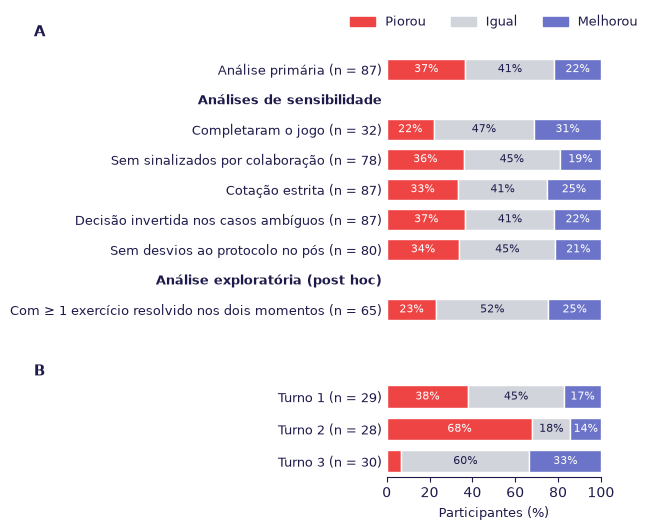

In [112]:

from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

ORDEM_MIP = ["Piorou", "Igual", "Melhorou"]

def pct_mip(pre, pos):
    """n e % de participantes que pioraram, ficaram iguais ou melhoraram."""
    d = (pd.DataFrame({"pre": pre, "pos": pos}).dropna()
           .pipe(lambda x: x["pos"] - x["pre"]))
    return len(d), {"Piorou": 100 * (d < 0).mean(),
                    "Igual": 100 * (d == 0).mean(),
                    "Melhorou": 100 * (d > 0).mean()}

def desenhar_mip(ax, entradas):
    """entradas: lista de ("titulo", texto) ou ("barra", rótulo, pré, pós)."""
    posicoes, rotulos, negrito = [], [], []
    for y, e in enumerate(entradas):
        posicoes.append(y)
        if e[0] == "titulo":
            rotulos.append(e[1]); negrito.append(True)
            continue
        n, pct = pct_mip(e[2], e[3])
        rotulos.append(f"{e[1]} (n = {n})"); negrito.append(False)
        esquerda = 0
        for cat in ORDEM_MIP:
            v = pct[cat]
            ax.barh(y, v, left=esquerda, height=0.7, color=CORES_MIP[cat], edgecolor="white")
            if v >= 8:
                ax.text(esquerda + v / 2, y, f"{fmt(v, 0)}%", ha="center", va="center", fontsize=8,
                        color=DILU_TEXT if cat == "Igual" else "white")
            esquerda += v
        print(f"{e[1]:<50} n = {n}  " + "  ".join(f"{c}: {fmt(pct[c], 1)}%" for c in ORDEM_MIP))
    ax.set_yticks(posicoes)
    ax.set_yticklabels(rotulos, fontsize=9)
    for etiqueta, b in zip(ax.get_yticklabels(), negrito):
        if b:
            etiqueta.set_fontweight("bold")
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.tick_params(axis="y", length=0)
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)

# Painel A: mesmas análises e rótulos da Tabela 3
entradas_A = [("barra", "Análise primária", prim["conhecimento_pre"], prim["conhecimento_pos"]),
              ("titulo", "Análises de sensibilidade")]
for nome, rot in ROTULOS_SENS.items():
    dados, var = SENSIBILIDADES[nome]
    entradas_A.append(("barra", rot.strip(), dados[f"{var}_pre"], dados[f"{var}_pos"]))
entradas_A += [("titulo", "Análise exploratória (post hoc)"),
               ("barra", "Com ≥ 1 exercício resolvido nos dois momentos",
                expl["conhecimento_pre"], expl["conhecimento_pos"])]

# Painel B: análise primária por turno
entradas_B = [("barra", f"Turno {int(t)}",
               prim.loc[prim["turno"] == t, "conhecimento_pre"],
               prim.loc[prim["turno"] == t, "conhecimento_pos"])
              for t in sorted(prim["turno"].unique())]

fig, (axA, axB) = plt.subplots(2, 1, figsize=(6.3, 5.6), sharex=True,
                               gridspec_kw={"height_ratios": [len(entradas_A), len(entradas_B)],
                                            "hspace": 0.25})
fig.subplots_adjust(left=0.56)  
desenhar_mip(axA, entradas_A)
desenhar_mip(axB, entradas_B)
axB.set_xlabel("Participantes (%)", fontsize=9)
axA.tick_params(axis="x", length=0)
axA.spines["bottom"].set_visible(False)

# Letras dos painéis, alinhadas à esquerda da figura
for ax, letra in [(axA, "A"), (axB, "B")]:
    ax.text(0.0, 1.02, letra, transform=blended_transform_factory(fig.transFigure, ax.transAxes),
            fontsize=11, fontweight="bold", va="bottom")

axA.legend(handles=[Patch(color=CORES_MIP[c], label=c) for c in ORDEM_MIP],
           ncol=3, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.02), fontsize=9)

plt.savefig(OUT_FIG / "Figura2_melhorou_igual_piorou.png", dpi=300, bbox_inches="tight")
plt.show()

**Figura 2** Proporção de participantes que melhoraram, se mantiveram ou pioraram entre o pré e o pós
Nota. Mudança no número de exercícios certos (0–3). (A) Análise primária, análises de sensibilidade e análise exploratória (post hoc). (B) Análise primária por turno. Percentagens inferiores a 8% não estão indicadas.

### 14.11 Figura 3: acerto por exercício (A) e estratégias de resolução (B)

ex1 pre: formula 84,7%, tentativa_erro 6,9%, regra3 5,6%, esquema 2,8%
ex1 pos: formula 77,8%, tentativa_erro 9,7%, regra3 8,3%, esquema 4,2%
ex2 pre: formula 79,7%, regra3 11,6%, tentativa_erro 7,2%, esquema 1,4%
ex2 pos: formula 78,3%, regra3 8,7%, tentativa_erro 7,2%, esquema 5,8%
ex3 pre: etapas 41,0%, formula 31,1%, tentativa_erro 14,8%, esquema 8,2%, regra3 4,9%
ex3 pos: formula 52,5%, etapas 23,0%, regra3 13,1%, tentativa_erro 9,8%, esquema 1,6%


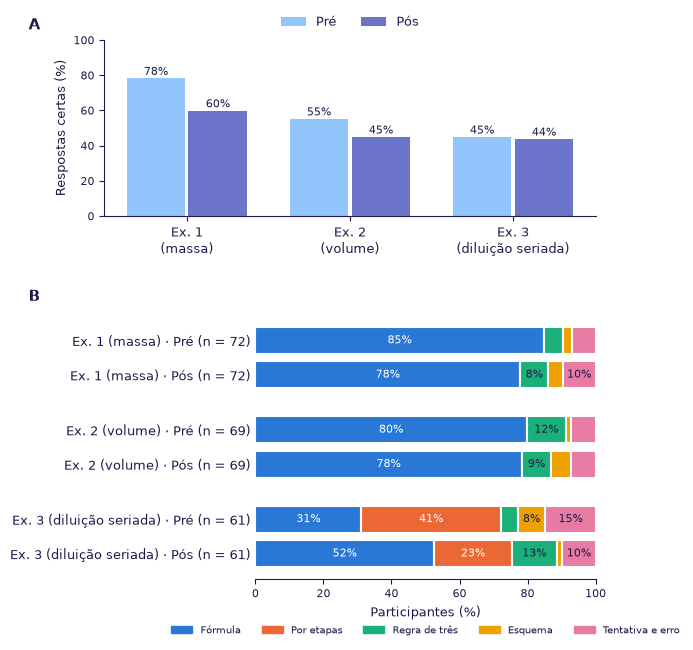

In [113]:
# A: % de respostas certas (n = 87), valores do fam1 (iguais à Tabela 4)
# B: distribuição das estratégias na base do Stuart-Maxwell (resolveram nos dois momentos)
NOMES_EX_FIG = {"ex1": "Ex. 1 (massa)", "ex2": "Ex. 2 (volume)", "ex3": "Ex. 3 (diluição seriada)"}

fig, (axA, axB) = plt.subplots(2, 1, figsize=(6.3, 7.0),
                               gridspec_kw={"height_ratios": [1, 1.5], "hspace": 0.45})
fig.subplots_adjust(left=0.36)

# --- Painel A ----------------------------------------------------------------
x = np.arange(len(EXS))
for i, (mom, cor, rot) in enumerate([("pre", DILU_ACCENT, "Pré"), ("pos", DILU_BLUE, "Pós")]):
    valores = [fam1_por_teste[f"Certo/errado: {ex}"][f"pct_{mom}"] for ex in EXS]
    barras = axA.bar(x + (i - 0.5) * 0.38, valores, width=0.36, color=cor, label=rot)
    for b, v in zip(barras, valores):
        axA.text(b.get_x() + b.get_width() / 2, v + 2, f"{fmt(v, 0)}%", ha="center", fontsize=8)
axA.set_xticks(x)
axA.set_xticklabels([NOMES_EX_FIG[ex].replace(" (", "\n(") for ex in EXS], fontsize=9)
axA.set_ylabel("Respostas certas (%)", fontsize=9)
axA.set_ylim(0, 100)
axA.tick_params(axis="y", labelsize=8)
for lado in ["top", "right"]:
    axA.spines[lado].set_visible(False)
axA.legend(frameon=False, fontsize=9, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))

# --- Painel B ----------------------------------------------------------------
linhas_B, rotulos_B = [], []
for ex in EXS:
    pares = emparelhar("metodo_analise", ex).dropna(subset=["pre", "pos"])
    for mom, nome_mom in [("pre", "Pré"), ("pos", "Pós")]:
        pct = pares[mom].value_counts(normalize=True) * 100
        linhas_B.append(pct)
        rotulos_B.append(f"{NOMES_EX_FIG[ex]} · {nome_mom} (n = {len(pares)})")
        print(f"{ex} {mom}: " + ", ".join(f"{m} {fmt(v, 1)}%" for m, v in pct.items()))

metodos_B = [m for m in ORDEM_METODOS if any(m in p.index for p in linhas_B)]
y = [i + (i // 2) * 0.6 for i in range(len(linhas_B))]          # espaço entre exercícios
for yi, pct in zip(y, linhas_B):
    esquerda = 0.0
    for m in metodos_B:
        v = float(pct.get(m, 0))
        if v <= 0:
            continue
        axB.barh(yi, v, left=esquerda, height=0.78, color=CORES_METODOS[m], edgecolor="white", linewidth=1.5)
        if v >= 8:
            axB.text(esquerda + v / 2, yi, f"{fmt(v, 0)}%", ha="center", va="center", fontsize=8,
                     color=DILU_TEXT if m in TEXTO_ESCURO else "white")
        esquerda += v
axB.set_yticks(y)
axB.set_yticklabels(rotulos_B, fontsize=9)
axB.invert_yaxis()
axB.set_xlim(0, 100)
axB.set_xlabel("Participantes (%)", fontsize=9)
axB.tick_params(axis="y", length=0)
axB.tick_params(axis="x", labelsize=8)
for lado in ["top", "right", "left"]:
    axB.spines[lado].set_visible(False)
axB.legend(handles=[Patch(color=CORES_METODOS[m], label=ROTULOS_METODOS[m]) for m in metodos_B],
           ncol=5, frameon=False, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.14))
# Painel A com a largura toda (não precisa do espaço dos rótulos do B)
posA, posB = axA.get_position(), axB.get_position()
axA.set_position([0.12, posA.y0, posB.x1 - 0.12, posA.height])

# Letras dos painéis
for ax, letra in [(axA, "A"), (axB, "B")]:
    ax.text(0.0, 1.04, letra, transform=blended_transform_factory(fig.transFigure, ax.transAxes),
            fontsize=11, fontweight="bold", va="bottom")

plt.savefig(OUT_FIG / "Figura3_acerto_e_estrategias.png", dpi=300, bbox_inches="tight")
plt.show()

**Figura 3** Respostas certas e estratégias de resolução por exercício, antes e depois da sessão
Nota. (A) Percentagem de respostas certas na amostra da análise primária (n = 87). (B) Distribuição das estratégias de resolução nos participantes que resolveram o exercício nos dois momentos. Percentagens inferiores a 8% não estão indicadas no painel B.

### 14.12 Figura 4: acerto (A) e estratégias (B) nos três momentos (F2)

Pré ['87,5', '59,4', '34,4']
Pós ['65,6', '37,5', '37,5']
Follow-up ['90,6', '81,2', '90,6']
ex1 pre (n = 29): formula 86,2%, regra3 6,9%, esquema 3,4%, tentativa_erro 3,4%
ex1 pos (n = 29): formula 82,8%, regra3 10,3%, esquema 3,4%, tentativa_erro 3,4%
ex1 follow (n = 29): formula 96,6%, regra3 3,4%
ex2 pre (n = 25): formula 80,0%, regra3 12,0%, esquema 4,0%, tentativa_erro 4,0%
ex2 pos (n = 25): formula 80,0%, regra3 12,0%, esquema 4,0%, tentativa_erro 4,0%
ex2 follow (n = 25): formula 92,0%, regra3 8,0%
ex3 pre (n = 22): formula 31,8%, etapas 31,8%, esquema 13,6%, tentativa_erro 13,6%, regra3 9,1%
ex3 pos (n = 22): formula 50,0%, etapas 31,8%, regra3 13,6%, esquema 4,5%
ex3 follow (n = 22): etapas 45,5%, formula 36,4%, esquema 13,6%, regra3 4,5%


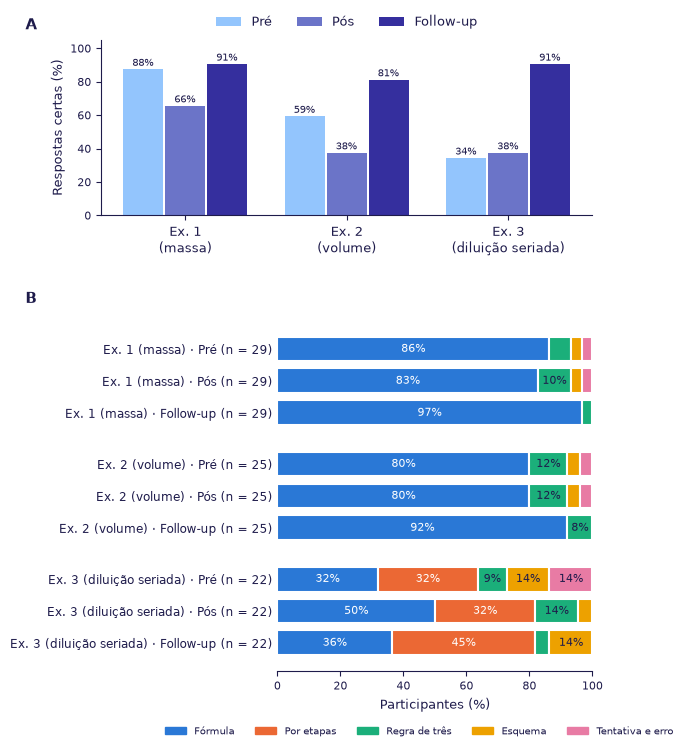

In [114]:
BASE_TESTE = True          # True: estratégia válida nos 3 momentos (base do Cochran); False: todos (n = 32)
COR_FOLLOW = "#352f9e"     # se já tens a cor do follow-up da secção 8, usa essa variável
MOMENTOS = [("pre", DILU_ACCENT, "Pré"), ("pos", DILU_BLUE, "Pós"), ("follow", COR_FOLLOW, "Follow-up")]

ids_f2 = F2["participant_id"]
fig, (axA, axB) = plt.subplots(2, 1, figsize=(6.3, 8.2),
                               gridspec_kw={"height_ratios": [1, 2], "hspace": 0.4})
fig.subplots_adjust(left=0.40)

# --- Painel A: % certo por exercício e momento (n = 32) ----------------------
sub = r3[r3["participant_id"].isin(ids_f2)]
x = np.arange(len(EXS))
largura_barra = 0.26
for i, (mom, cor, rot) in enumerate(MOMENTOS):
    valores = [100 * sub[(sub["exercicio"] == ex) & (sub["momento"] == mom)]["correct"].mean() for ex in EXS]
    barras = axA.bar(x + (i - 1) * largura_barra, valores, width=largura_barra * 0.95, color=cor, label=rot)
    for b, v in zip(barras, valores):
        axA.text(b.get_x() + b.get_width() / 2, v + 2, f"{fmt(v, 0)}%", ha="center", fontsize=7.5)
    print(rot, [fmt(v, 1) for v in valores])
axA.set_xticks(x)
axA.set_xticklabels([NOMES_EX_FIG[ex].replace(" (", "\n(") for ex in EXS], fontsize=9)
axA.set_ylabel("Respostas certas (%)", fontsize=9)
axA.set_ylim(0, 105)
axA.tick_params(axis="y", labelsize=8)
for lado in ["top", "right"]:
    axA.spines[lado].set_visible(False)
axA.legend(frameon=False, fontsize=9, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))

# --- Painel B: estratégias por exercício e momento ---------------------------
col_metodo = "metodo_analise" if BASE_TESTE else "metodo_descritivo"
linhas_B, rotulos_B = [], []
for ex in EXS:
    largo = (m3[m3["exercicio"] == ex]
             .pivot(index="participant_id", columns="momento", values=col_metodo))
    if BASE_TESTE:
        largo = largo.dropna(subset=["pre", "pos", "follow"])
    for mom, _, rot in MOMENTOS:
        s = largo[mom].dropna()
        linhas_B.append(s.value_counts(normalize=True) * 100)
        rotulos_B.append(f"{NOMES_EX_FIG[ex]} · {rot} (n = {len(s)})")
        print(f"{ex} {mom} (n = {len(s)}): " + ", ".join(f"{m} {fmt(v, 1)}%" for m, v in linhas_B[-1].items()))
    if BASE_TESTE:   # confirma que a base é a do Cochran
        assert len(largo) == int(fam3_por_teste[f"Usou fórmula {ex}: três momentos"]["n"]), f"{ex}: base diferente do Cochran"

metodos_B = [m for m in ORDEM_METODOS if any(m in p.index for p in linhas_B)]
y = [i + (i // 3) * 0.6 for i in range(len(linhas_B))]          # espaço entre exercícios
for yi, pct in zip(y, linhas_B):
    esquerda = 0.0
    for m in metodos_B:
        v = float(pct.get(m, 0))
        if v <= 0:
            continue
        axB.barh(yi, v, left=esquerda, height=0.78, color=CORES_METODOS[m], edgecolor="white", linewidth=1.5)
        if v >= 8:
            axB.text(esquerda + v / 2, yi, f"{fmt(v, 0)}%", ha="center", va="center", fontsize=8,
                     color=DILU_TEXT if m in TEXTO_ESCURO else "white")
        esquerda += v
axB.set_yticks(y)
axB.set_yticklabels(rotulos_B, fontsize=8.5)
axB.invert_yaxis()
axB.set_xlim(0, 100)
axB.set_xlabel("Participantes (%)", fontsize=9)
axB.tick_params(axis="y", length=0)
axB.tick_params(axis="x", labelsize=8)
for lado in ["top", "right", "left"]:
    axB.spines[lado].set_visible(False)
axB.legend(handles=[Patch(color=CORES_METODOS[m], label=ROTULOS_METODOS[m]) for m in metodos_B],
           ncol=len(metodos_B), frameon=False, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.45, -0.13))

# Painel A com a largura toda e letras dos painéis
posA, posB = axA.get_position(), axB.get_position()
axA.set_position([0.12, posA.y0, posB.x1 - 0.12, posA.height])
for ax, letra in [(axA, "A"), (axB, "B")]:
    ax.text(0.0, 1.04, letra, transform=blended_transform_factory(fig.transFigure, ax.transAxes),
            fontsize=11, fontweight="bold", va="bottom")

plt.savefig(OUT_FIG / "Figura4_tres_momentos.png", dpi=300, bbox_inches="tight")
plt.show()

**Figura 4** Respostas certas e estratégias de resolução por exercício nos três momentos
Nota. Participantes com os três momentos (n = 32). (A) Percentagem de respostas certas. (B) Distribuição das estratégias de resolução nos participantes com estratégia válida nos três momentos. No follow-up, o ex. 3 usou um fator de diluição de 1:10. Percentagens inferiores a 8% não estão indicadas no painel B.

### 14.13 Tabela A5: acesso ao LabPartner por dispositivo (follow-up)

In [115]:
ORD_DISP = ["Telemóvel", "Tablet", "Computador", "Mais do que um"]
ORD_AC = list(ACESSO_CURTO.values())
ct = (pd.crosstab(fu["dispositivo"], fu["acesso_cat"])
        .reindex(index=ORD_DISP, columns=ORD_AC, fill_value=0))

def linha_a5(rotulo, contagens):
    total = int(contagens.sum())
    linha = {"Dispositivo": rotulo, "n": total}
    for ac in ORD_AC:
        linha[ac] = f"{int(contagens[ac])} ({fmt(100 * contagens[ac] / total, 0)})" if total else "—"
    return linha

linhas = [linha_a5(d, ct.loc[d]) for d in ORD_DISP] + [linha_a5("Total", ct.sum())]
tabela_a5 = pd.DataFrame(linhas)
nota_a5 = (f"Nota. Respostas ao follow-up (n = {int(ct.values.sum())}). Dispositivo usado na sessão e acesso ao "
           "LabPartner reportados pelos participantes; \"Mais do que um\" = mais do que um dispositivo assinalado. "
           "Valores em n (% da linha). Descritivo.")
TABELAS["Anexo dispositivo"] = ("A5", "Acesso ao LabPartner reportado no follow-up, por dispositivo usado na sessão",
                                tabela_a5, nota_a5)
print(tabela_a5.to_string(index=False))

   Dispositivo  n Acedeu e usou Acedeu, quase não usou Tentou, sem acesso Não tentou Não se lembra
     Telemóvel 13        4 (31)                  1 (8)             8 (62)      0 (0)         0 (0)
        Tablet 17        6 (35)                 5 (29)             3 (18)     2 (12)         1 (6)
    Computador 10        4 (40)                 2 (20)             2 (20)     1 (10)        1 (10)
Mais do que um  4        1 (25)                 1 (25)              0 (0)     1 (25)        1 (25)
         Total 44       15 (34)                 9 (20)            13 (30)      4 (9)         3 (7)


### 14.14 Tabela A6: temas do feedback aberto

In [116]:
TEMAS_POSITIVOS = ["Fácil de usar e interativo", "Apreciação global positiva",
                   "Útil para rever e consolidar", "LabPartner valorizado por quem lhe acedeu",
                   "Autonomia e feedback imediato", "Recursos visuais e de apoio"]
TEMAS_NEGATIVOS = [t for t in TEMAS if t not in TEMAS_POSITIVOS]
COLS_A6 = ["Tema", "Participantes, n (%)", "Comentários", "Citações ilustrativas"]

com_conteudo = fb.loc[fb["Sem_conteudo_substantivo"] == 0, "participant_id"].nunique()

def linhas_bloco(temas):
    """Uma linha por tema, ordenadas pelo n de participantes (decrescente)."""
    linhas = []
    for tema in temas:
        sub = fb[fb[tema] == 1]
        n_part = sub["participant_id"].nunique()
        linhas.append({"Tema": f"  {tema}", "_n": n_part,
                       "Participantes, n (%)": f"{n_part} ({fmt(100 * n_part / com_conteudo, 1)})",
                       "Comentários": len(sub),
                       "Citações ilustrativas": " / ".join(citar(*c) for c in CITACOES.get(tema, []))})
    return sorted(linhas, key=lambda l: -l["_n"])

linhas = ([linha_titulo("Aspetos valorizados", COLS_A6)] + linhas_bloco(TEMAS_POSITIVOS) +
          [linha_titulo("Barreiras e críticas", COLS_A6)] + linhas_bloco(TEMAS_NEGATIVOS))
tabela_a6 = pd.DataFrame(linhas)[COLS_A6]

nota_a6 = ("Nota. Comentários abertos do pós (gerais, aspetos positivos e aspetos negativos) e do follow-up, "
           "lidos e agrupados em temas pela investigadora, com contagem de frequências; não constitui uma "
           "análise qualitativa formal. Um comentário pode pertencer a mais do que um tema. Percentagens "
           f"calculadas sobre os {com_conteudo} participantes com pelo menos um comentário com conteúdo "
           f"(de {fb['participant_id'].nunique()} que comentaram; {len(fb)} comentários). Citações "
           "transcritas sem correção, com a origem entre parênteses.")
TABELAS["Anexo feedback"] = ("A6", "Temas do feedback aberto dos participantes", tabela_a6, nota_a6)
print(tabela_a6.drop(columns="Citações ilustrativas").to_string(index=False))

                                       Tema Participantes, n (%) Comentários
                        Aspetos valorizados                                 
                 Fácil de usar e interativo            47 (50,5)          49
                 Apreciação global positiva            39 (41,9)          47
               Útil para rever e consolidar            26 (28,0)          31
  LabPartner valorizado por quem lhe acedeu            11 (11,8)          11
              Autonomia e feedback imediato              9 (9,7)           9
                Recursos visuais e de apoio              8 (8,6)           8
                       Barreiras e críticas                                 
          Acesso e integração do LabPartner            24 (25,8)          27
                         Tempo insuficiente            12 (12,9)          14
         Dificuldade ou clareza das tarefas            11 (11,8)          11
                    Dispositivo e interface            10 (10,8)          12

### 14.99 Escrever todas as tabelas do relatório num só ficheiro 

In [117]:

caminho = OUT_TAB / "Tabelas_relatorio.xlsx"
with pd.ExcelWriter(caminho, engine="openpyxl") as writer:
    for folha, (numero, titulo, df, nota) in TABELAS.items():
        escrever_tabela_apa(writer, folha, numero, titulo, df, nota)
print("Escrito:", caminho, "|", ", ".join(TABELAS))

Escrito: C:\Users\Beatriz Costa\Desktop\DILU-IA\outputs\tabelas\Tabelas_relatorio.xlsx | Tabela 2, Anexo fiabilidade, Tabela 3, Tabela 4, Tabela 5, Tabela 6, Anexo atrição, Anexo correlações, Anexo SUS itens, Anexo dispositivo, Anexo feedback
